> **Ejecución revisada:** esta versión conserva las salidas de K1 y contiene interpretaciones completadas con esas salidas.

# EP2 - Técnicas Avanzadas de Machine Learning I (TLY1101)
**Integrantes:** Karla Hoch y Sebastián Huaiquimilla

**Dataset:** Oxford-IIIT Pet.

**Variante propia (continuidad con la EP1):** clasificación multiclase de 5 razas de gatos, comparando un subconjunto de razas **parecidas entre sí** (Birman, Ragdoll, Siamese, Persian, Maine_Coon) con uno de razas **distintas entre sí** (Bombay, Sphynx, Russian_Blue, Bengal, Abyssinian). Se mantienen las mismas razas, la misma cantidad de imágenes por raza, la misma partición 70/15/15 y la misma semilla (2604) de la EP1, para que la comparación entre modelos sea justa y trazable.

## 1. Definición del problema y continuidad con la EP1

### 1.1 Problema de negocio
Una clínica veterinaria quiere agilizar el registro de pacientes. A partir de una fotografía de un gato, el sistema propone su **raza** para prellenar la ficha clínica (la raza condiciona controles preventivos y riesgos conocidos), y el personal confirma o corrige. Es una herramienta de **apoyo**, no de decisión.

### 1.2 Punto de partida: qué se hizo en la EP1
En la EP1 se resolvió este mismo problema con un **perceptrón multicapa (MLP)** que recibe la imagen aplanada (64x64x3 = 12.288 valores). Su configuración final fue: una capa oculta de 128 neuronas con ReLU, dropout 0,3, learning rate 1e-4, estandarización por canal, aumento de datos, batch 32 y `EarlyStopping` con paciencia 20. Se eligió con unos 87 entrenamientos de ajuste en validación, y se evaluó en prueba con 5 semillas:

| Subconjunto | F1 macro | Accuracy | Recall mínimo | KPI principal (F1 ≥ 0,40) | KPI secundario (recall mín. ≥ 0,20) |
|---|---|---|---|---|---|
| PARECIDAS | 0,363 ± 0,041 | 0,365 ± 0,041 | 0,254 ± 0,026 | No se cumple | Se cumple |
| DISTINTAS | 0,487 ± 0,037 | 0,490 ± 0,036 | 0,360 ± 0,059 | Se cumple | Se cumple |

Las limitaciones que se identificaron en la EP1 motivan esta evaluación: al aplanar la imagen el MLP **pierde la vecindad entre píxeles** y no puede aprender formas locales (orejas, hocico, patrón de la cara), parece guiarse por color y textura global, usa a Ragdoll como "clase comodín" en PARECIDAS, está sobreconfiado, y tiene 1.573.644 parámetros para solo 644 imágenes de entrenamiento. La principal mejora propuesta en la EP1 fue pasar a una **red neuronal convolucional (CNN)**, que es lo que se implementa aquí. Estas cifras provienen del notebook entregado de la EP1; en la sección 7 el MLP se reentrena en este notebook para comparar bajo las mismas condiciones.

### 1.3 Dataset y justificación
Se usa el **Oxford-IIIT Pet Dataset** (37 razas de perros y gatos, unas 200 imágenes por raza, con variabilidad de fondo, postura e iluminación, y anotaciones oficiales que incluyen la raza), uno de los conjuntos que la pauta permite y el recomendado para poder comparar con la EP1. Razones:
1. **Coherencia con el negocio:** son fotografías de mascotas con la raza como etiqueta, que es lo que necesita la clínica.
2. **Comparación objetiva con el MLP:** al reutilizar los mismos datos, las diferencias entre modelos se pueden atribuir a la arquitectura y no a los datos.
3. **Permite construir subconjuntos controlados por raza**, necesarios para estudiar el efecto del parecido visual entre clases.

### 1.4 Variante propia
Se mantiene la variante de la EP1:
- **Problema multiclase de 5 razas de gatos**, en lugar de la clasificación binaria perro vs. gato que menciona la pauta como ejemplo.
- **Dos subconjuntos disjuntos, ambos solo de gatos** (así la especie no cambia entre ellos):
  - **PARECIDAS:** Birman, Ragdoll, Siamese, Persian, Maine_Coon. Birman, Ragdoll y Siamese comparten el patrón *colorpoint* (cuerpo claro con cara, orejas y patas más oscuras); Persian y Maine_Coon se incluyen por su pelaje largo, un parecido más débil. **Límite de la justificación:** el parecido no es homogéneo; los pares Persian–Maine_Coon (0,1268) y Ragdoll–Maine_Coon (0,1384) son los más distantes del subconjunto según la sección 2.2.1, más que 6 de los 10 pares de DISTINTAS. Se mantienen para conservar la trazabilidad con la EP1 y porque el parecido visual (forma, pelaje) no se reduce al color; se declara como limitación y se contrasta con los errores de la sección 9.
  - **DISTINTAS:** Bombay, Sphynx, Russian_Blue, Bengal, Abyssinian. Cada raza difiere de las otras en color, textura o forma.
- **Misma cantidad de imágenes por raza** en ambos subconjuntos (184, la menor disponible), sorteadas con la semilla propia 2604, y **división estratificada 70/15/15** (644 imágenes de entrenamiento y 138 de validación y de prueba por subconjunto).
- **Toda la experimentación se hace sobre PARECIDAS**; la configuración elegida se aplica después a DISTINTAS sin reajustarla.

**Hipótesis de trabajo (formuladas antes de entrenar, en las secciones 2.2 y 3):** (H1) la CNN rendirá igual o mejor que el MLP, con muchos menos parámetros; (H2) la ventaja de la CNN debería notarse sobre todo en PARECIDAS, donde la forma local de los rasgos importa más que el color; (H3) igual que el MLP, la CNN rendirá mejor en DISTINTAS que en PARECIDAS. Se contrastan en las conclusiones, y un resultado distinto también es válido y se analiza.

### 1.5 Objetivos
**General:** diseñar, entrenar y evaluar una CNN que clasifique la raza de un gato a partir de una fotografía, y compararla con el MLP de la EP1 para determinar cuánto aporta la convolución.

**Específicos:**
1. Preparar las imágenes en formato tensorial (redimensionamiento, normalización, partición) manteniendo la trazabilidad con la EP1.
2. Diseñar la arquitectura justificando las capas convolucionales, de pooling y densas, y los hiperparámetros.
3. Seleccionar la configuración con experimentos en validación (un factor a la vez y varias semillas).
4. Evaluar con Accuracy, Precision, Recall, F1-Score y matriz de confusión, con 5 semillas, y verificar los KPIs.
5. Comparar con el MLP en desempeño, cantidad de parámetros, tiempo de entrenamiento y capacidad de generalización.
6. Interpretar los mapas de características y los mapas de activación por clase, y analizar los errores.

### 1.6 KPIs
La línea base del azar con 5 clases balanceadas es **20% de accuracy**. Se mantienen los KPIs de la EP1, sin modificarlos después de ver los resultados:
- **KPI principal:** F1-Score macro en el set de prueba ≥ **0,40** (el doble del azar), promedio de 5 semillas.
- **KPI secundario:** recall mínimo entre las 5 razas ≥ **0,20**, promedio de 5 semillas. Busca que ninguna raza quede ignorada por el modelo.

**Nota sobre el KPI secundario.** Con 5 clases balanceadas, un modelo que adivina al azar tiene un recall esperado de 0,20 en cada raza, así que el umbral coincide con el **nivel del azar**: el KPI solo detecta razas ignoradas por completo y no garantiza un desempeño útil por raza. Se mantiene sin cambios por trazabilidad con la EP1.

**KPI complementario de negocio (definido después de ver los resultados; no se usa para declarar cumplimiento).** Como la herramienta es de apoyo con confirmación del personal, interesa qué fracción de las fotos podría confirmarse con poco riesgo: la **cobertura** (fracción de predicciones con confianza ≥ 0,8) y la **precisión de esas predicciones**. Se reporta en la sección 7.1c.

**Criterio para comparar modelos (el mismo de la EP1):** una diferencia de F1 macro entre dos modelos se considera relevante solo si supera la suma de las desviaciones estándar entre semillas; si es menor, se interpreta como empate técnico.

### 1.7 Metodología (CRISP-DM)
| Fase | Dónde se aborda |
|---|---|
| 1. Comprensión del negocio | Sección 1: problema, punto de partida, objetivos, KPIs, hipótesis |
| 2. Comprensión de los datos | Secciones 1.3 y 2: descripción del dataset, EDA, calidad de datos |
| 3. Preparación de los datos | Sección 2: muestreo, partición, tensores, normalización, aumento de datos |
| 4. Modelado | Secciones 3, 4 y 5: arquitectura, entrenamiento, experimentos y selección |
| 5. Evaluación | Secciones 6 a 9: métricas en prueba, comparación con el MLP, feature maps, análisis de errores |
| 6. Despliegue | No se despliega. Los modelos se guardan en `models/` y se proponen mejoras en las conclusiones |

### 1.8 Cómo reproducir
1. Abrir el notebook en Google Colab.
2. `Entorno de ejecución > Ejecutar todo`. El notebook descarga el dataset oficial y ejecuta todo el pipeline; los resultados intermedios se guardan en `resultados/` y las figuras en `images/`.
3. Las semillas están fijadas (2604 para el muestreo y la partición; listas de semillas para la inicialización) y se activa el **modo determinista de TensorFlow**. Con otro hardware (CPU o GPU) o versión de TensorFlow los resultados pueden variar levemente, y los tiempos dependen de la máquina, por eso los resultados se reportan como media ± desviación estándar de varias semillas. Este notebook se ejecutó en CPU.

### 1.9 Consideraciones éticas
- **Origen y uso de los datos:** el Oxford-IIIT Pet (Parkhi et al., 2012) se usa con fines académicos y se cita su fuente. Son fotografías de internet de mascotas; algunas pueden mostrar personas o lugares reconocibles al fondo, que no se usan ni se analizan.
- **Privacidad en un uso real:** en una clínica, las fotos y la ficha quedan asociadas a los dueños. Habría que pedir consentimiento, guardar las imágenes de forma segura y no usarlas para otros fines.
- **Sesgo y representatividad:** el dataset solo tiene razas definidas, con fotos de internet (en general bien encuadradas), y no incluye gatos mestizos, que son la mayoría en la práctica. Un modelo entrenado así rendirá peor con gatos que no se parezcan a esas fotos, y sus errores no se reparten parejo entre razas (se mide en las secciones 6 y 9).
- **Riesgo de uso:** la raza condiciona controles preventivos. Un error confirmado sin mirar podría llevar a registrar mal una ficha o a sugerir controles inadecuados. Por eso se plantea solo como apoyo, con confirmación del personal, y nunca como decisión automática.
- **Interpretabilidad:** los mapas de activación muestran en qué zona de la imagen se apoyó la red, pero no garantizan que se haya fijado en lo correcto (por ejemplo, el fondo en vez del animal). Se usan para revisar esos casos, no como una explicación definitiva.
- **Transparencia:** se reportan también los resultados que no cumplen los KPIs, junto con sus limitaciones, para no sobreestimar lo que el modelo puede hacer.

In [1]:
# ==========================================
# CONFIGURACIÓN GENERAL
# ==========================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"      # menos logs de TensorFlow (debe ir antes de importar TF)

import random, time, warnings, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, recall_score, precision_score)
from PIL import Image

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
print("Python:", sys.version.split()[0])
print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__, "| pandas:", pd.__version__)
print("GPU disponible:", tf.config.list_physical_devices("GPU"))

# --- Semillas (las mismas de la EP1, para mantener la trazabilidad) ---
SEED_SPLIT = 2604                          # muestreo y división de datos
SEEDS_EXP = [11, 22, 33]                   # experimentos en validación
SEEDS_FINAL = [101, 102, 103, 104, 105]    # evaluación final en prueba

random.seed(SEED_SPLIT); np.random.seed(SEED_SPLIT); tf.keras.utils.set_random_seed(SEED_SPLIT)

try:
    tf.config.experimental.enable_op_determinism()
    print("Modo determinista de TensorFlow: ACTIVADO")
except Exception as e:
    print("No se pudo activar el modo determinista:", e)

# --- Carpetas del proyecto ---
for carpeta in ["images", "models", "resultados"]:
    os.makedirs(carpeta, exist_ok=True)

def guardar_fig(nombre):
    plt.savefig(f"images/{nombre}.png", dpi=150, bbox_inches="tight")

Python: 3.13.16
TensorFlow: 2.21.0
NumPy: 2.1.3 | pandas: 2.2.3
GPU disponible: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Modo determinista de TensorFlow: ACTIVADO


## 2. Preparación del conjunto de datos

Se reutiliza el trabajo de la EP1 para mantener la trazabilidad: se usan las **7.349 imágenes con anotación oficial** del Oxford-IIIT Pet Dataset (`list.txt`), y la **raza** se obtiene del nombre de cada archivo (por ejemplo `Birman_12.jpg`).

**Muestreo:** de cada una de las 10 razas se sortean 184 imágenes con la semilla propia (2604), que es la menor cantidad disponible entre todas las razas (Bombay). Así ambos subconjuntos quedan balanceados y del mismo tamaño.

**División:** 70% entrenamiento, 15% validación y 15% prueba, estratificada por raza y con la misma semilla de la EP1. Esto deja 644 imágenes de entrenamiento y 138 de validación y de prueba por subconjunto, idéntico a lo que vio el MLP.

**Adaptación para la CNN:** a diferencia del MLP, las imágenes **no se aplanan**. Se conservan como matrices de alto x ancho x 3 canales (RGB), porque la convolución necesita esa estructura espacial para funcionar. Además se redimensionan a un tamaño fijo y se normalizan; esos pasos se explican en las celdas siguientes.

In [2]:
# ==========================================
# DESCARGA DEL DATASET OFICIAL (imágenes + anotaciones)
# ==========================================
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz
!wget -q https://www.robots.ox.ac.uk/~vgg/data/pets/data/annotations.tar.gz
!tar -xzf images.tar.gz
!tar -xzf annotations.tar.gz
print("Dataset listo.")

Dataset listo.


In [3]:
# ==========================================
# CARGA DE ANOTACIONES Y DEFINICIÓN DE LA VARIANTE
# ==========================================
cols = ["imagen", "clase_id", "especie", "raza_id"]          # especie: 1 = gato, 2 = perro
lista = pd.read_csv("/content/annotations/list.txt", comment="#", sep=" ", header=None, names=cols)
lista["raza"] = lista["imagen"].str.rsplit("_", n=1).str[0]
lista["ruta"] = "/content/images/" + lista["imagen"] + ".jpg"
print(f"Imágenes anotadas: {len(lista)} | razas: {lista['raza'].nunique()}")
assert lista["ruta"].map(os.path.exists).all(), "Faltan archivos de imagen"

PARECIDAS = ["Birman", "Ragdoll", "Siamese", "Persian", "Maine_Coon"]
DISTINTAS = ["Bombay", "Sphynx", "Russian_Blue", "Bengal", "Abyssinian"]

assert not set(PARECIDAS) & set(DISTINTAS), "Los subconjuntos deben ser disjuntos"
assert set(PARECIDAS + DISTINTAS) <= set(lista["raza"]), "Hay un nombre de raza que no existe"
assert (lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["especie"] == 1).all(), "Todas las razas deben ser gatos"

conteo = lista[lista["raza"].isin(PARECIDAS + DISTINTAS)]["raza"].value_counts()
print("\nImágenes disponibles por raza elegida:")
print(conteo.to_string())
N_POR_CLASE = int(conteo.min())
print(f"\nN_POR_CLASE (mínimo disponible) = {N_POR_CLASE}")

Imágenes anotadas: 7349 | razas: 37

Imágenes disponibles por raza elegida:
raza
Bengal          200
Birman          200
Sphynx          200
Maine_Coon      200
Persian         200
Ragdoll         200
Russian_Blue    200
Siamese         199
Abyssinian      198
Bombay          184

N_POR_CLASE (mínimo disponible) = 184


In [4]:
# ==========================================
# MUESTREO BALANCEADO + DIVISIÓN ESTRATIFICADA 70/15/15
# ==========================================
def preparar_subconjunto(clases, n_por_clase, seed):
    rng = np.random.default_rng(seed)
    partes = []
    for c in clases:
        fc = lista[lista["raza"] == c].sort_values("imagen")      # orden fijo -> muestreo reproducible
        partes.append(fc.iloc[rng.permutation(len(fc))[:n_por_clase]])
    d = pd.concat(partes).reset_index(drop=True)
    d["y"] = d["raza"].map({c: i for i, c in enumerate(clases)})
    tr, tmp = train_test_split(d, test_size=0.30, stratify=d["y"], random_state=seed)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp["y"], random_state=seed)
    return tr.reset_index(drop=True), va.reset_index(drop=True), te.reset_index(drop=True)

SPLITS = {}
for nombre, clases in [("parecidas", PARECIDAS), ("distintas", DISTINTAS)]:
    tr, va, te = preparar_subconjunto(clases, N_POR_CLASE, SEED_SPLIT)
    SPLITS[nombre] = dict(clases=clases, train=tr, val=va, test=te)
    print(f"{nombre:10s} -> train: {len(tr)} | val: {len(va)} | test: {len(te)} | clases: {clases}")

parecidas  -> train: 644 | val: 138 | test: 138 | clases: ['Birman', 'Ragdoll', 'Siamese', 'Persian', 'Maine_Coon']
distintas  -> train: 644 | val: 138 | test: 138 | clases: ['Bombay', 'Sphynx', 'Russian_Blue', 'Bengal', 'Abyssinian']


### 2.1 Carga de imágenes como tensores

Las imágenes originales tienen tamaños muy distintos (de 108 a 1.725 px), y una red neuronal necesita entradas de tamaño fijo. Por eso cada imagen se **redimensiona** y se guarda como un tensor de forma `(alto, ancho, 3)`, donde los 3 canales son rojo, verde y azul (RGB).

**Decisiones:**
1. **Se conserva el formato matricial.** A diferencia del MLP, no se aplica `Flatten` a la entrada. La convolución necesita saber qué píxel está al lado de cuál para poder detectar formas locales (orejas, hocico, patrón de la cara).
2. **Resolución de referencia: 64x64**, la misma que usó el MLP en la EP1. Así la comparación entre modelos parte de la misma información de entrada. Además se carga una versión de **128x128**, que se prueba en el Anexo A (solo en validación) para ver si la CNN aprovecha mejor el detalle fino; el modelo final se mantiene en 64x64 para comparar con el MLP bajo la misma información de entrada (en la EP1, subir la resolución no ayudó al MLP).
3. **Tipo de dato `uint8` (0 a 255).** Los valores se guardan como enteros para ocupar menos memoria. La normalización a [0, 1] se hará dentro del modelo con una capa `Rescaling`, igual que en la EP1, de modo que entrenamiento, validación y prueba reciban exactamente el mismo tratamiento.
4. **Mismo método de redimensionamiento que la EP1** (el de Keras por defecto), para mantener la trazabilidad.
5. **Carga en RGB.** Una imagen del set de entrenamiento de la EP1 venía con canal de transparencia (RGBA); `load_img` la convierte a RGB automáticamente.

Las imágenes se cargan una sola vez como arreglos de NumPy, lo que acelera el entrenamiento y permite repetir experimentos con las mismas entradas.

In [5]:
# ==========================================
# CARGA DE IMÁGENES COMO TENSORES (64x64 y 128x128, RGB, uint8)
# ==========================================
RESOLUCIONES = [64, 128]      # 64 = referencia (igual que el MLP); 128 = experimento posterior
RES_BASE = 64

def cargar(df, lado):
    return np.stack([np.array(tf.keras.utils.load_img(r, target_size=(lado, lado)))
                     for r in df["ruta"]]).astype("uint8")

for nombre, sp in SPLITS.items():
    sp["XR"] = {lado: {parte: cargar(sp[parte], lado) for parte in ["train", "val", "test"]}
                for lado in RESOLUCIONES}
    for parte in ["train", "val", "test"]:
        sp["y_" + parte] = sp[parte]["y"].values
        sp["X_" + parte] = sp["XR"][RES_BASE][parte]      # arreglos por defecto (64x64)
    formas = " | ".join(f"{lado}px: {sp['XR'][lado]['train'].shape}" for lado in RESOLUCIONES)
    print(f"{nombre:10s} X_train -> {formas}")
    print(f"{'':10s} val {sp['X_val'].shape} | test {sp['X_test'].shape} | "
          f"dtype {sp['X_train'].dtype} | rango [{sp['X_train'].min()}, {sp['X_train'].max()}]")

parecidas  X_train -> 64px: (644, 64, 64, 3) | 128px: (644, 128, 128, 3)
           val (138, 64, 64, 3) | test (138, 64, 64, 3) | dtype uint8 | rango [0, 255]
distintas  X_train -> 64px: (644, 64, 64, 3) | 128px: (644, 128, 128, 3)
           val (138, 64, 64, 3) | test (138, 64, 64, 3) | dtype uint8 | rango [0, 255]


### 2.2 Visualización de ejemplos representativos y distribución de clases

Antes de diseñar la red, se revisan dos cosas sobre el **set de entrenamiento** (para no filtrar información de validación ni de prueba):
1. **Distribución de clases:** si hay razas con más imágenes que otras, el modelo podría favorecer a las más frecuentes.
2. **Ejemplos por raza a 64x64:** se muestran las imágenes tal como las recibe la red, para ver cuánto detalle se conserva después del redimensionamiento.

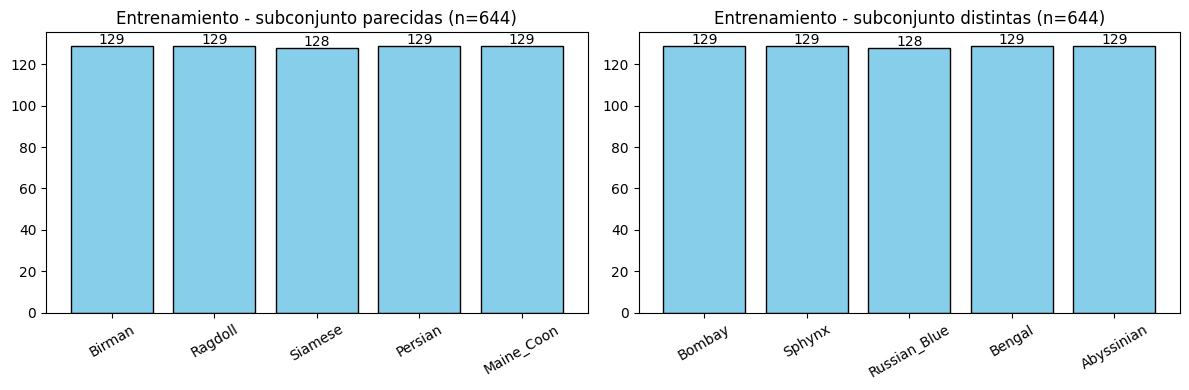

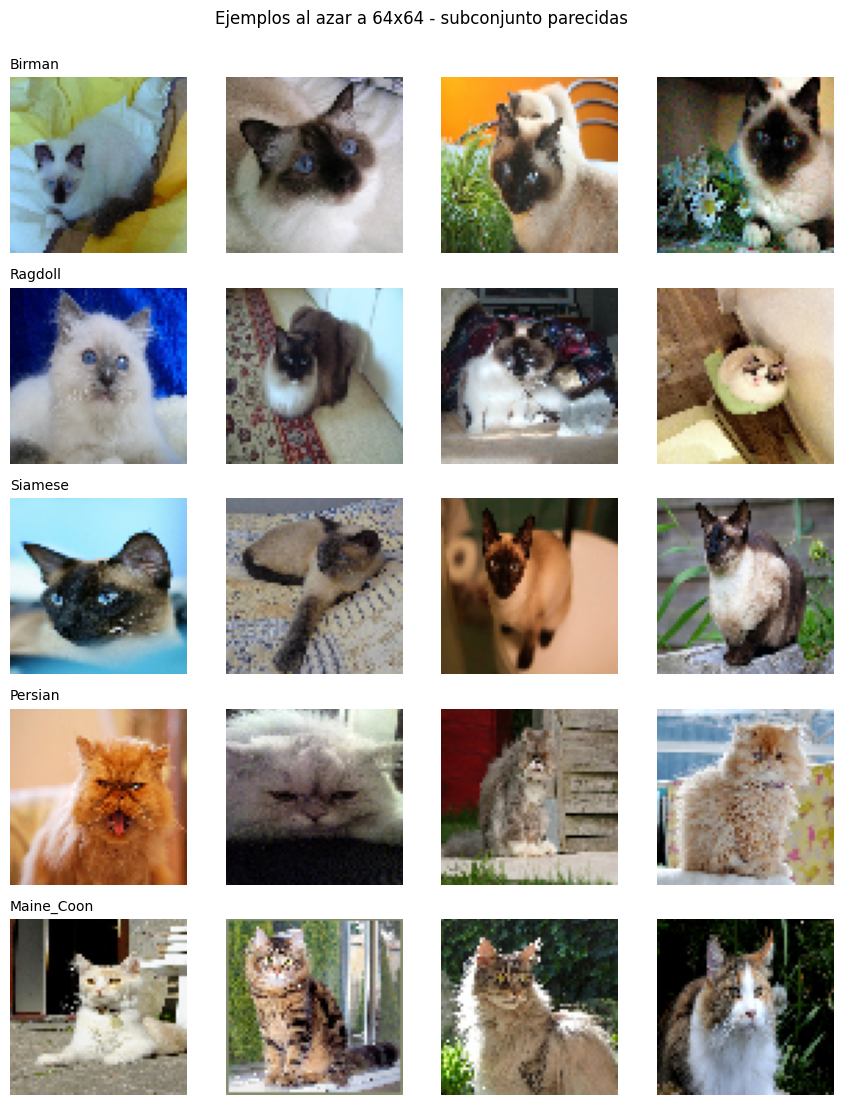

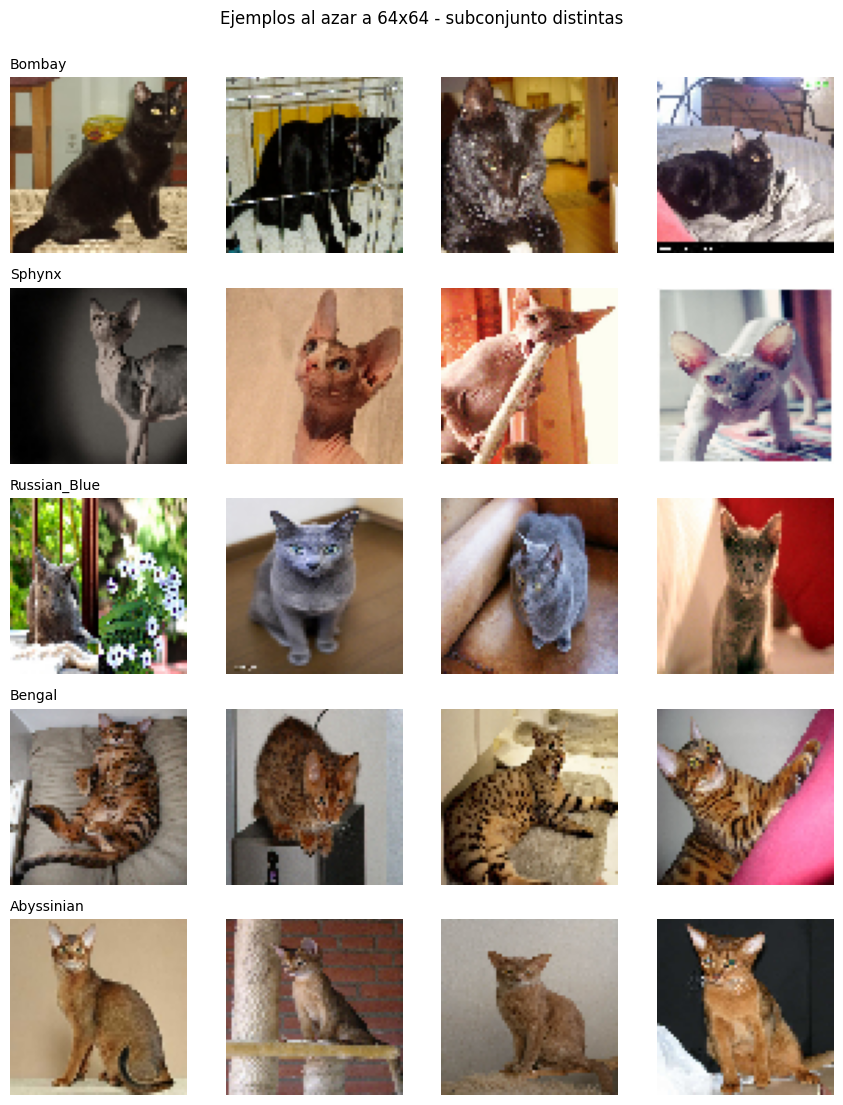

In [6]:
# ==========================================
# EDA: DISTRIBUCIÓN DE CLASES Y EJEMPLOS A 64x64 (solo entrenamiento)
# ==========================================
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (nombre, sp) in zip(ejes, SPLITS.items()):
    cuentas = sp["train"]["raza"].value_counts().reindex(sp["clases"])
    ax.bar(cuentas.index, cuentas.values, color="skyblue", edgecolor="black")
    ax.set_title(f"Entrenamiento - subconjunto {nombre} (n={len(sp['train'])})")
    ax.tick_params(axis="x", rotation=30)
    for i, v in enumerate(cuentas.values):
        ax.text(i, v + 1, str(v), ha="center")
plt.tight_layout(); guardar_fig("01_distribucion_clases"); plt.show()

def mostrar_ejemplos(nombre, por_raza=4):
    sp = SPLITS[nombre]; clases = sp["clases"]
    rng = np.random.default_rng(SEED_SPLIT)
    fig, ejes = plt.subplots(len(clases), por_raza, figsize=(2.2 * por_raza, 2.2 * len(clases)))
    for i, c in enumerate(clases):
        idx = np.where(sp["y_train"] == i)[0]
        for j, k in enumerate(rng.choice(idx, por_raza, replace=False)):
            ejes[i, j].imshow(sp["X_train"][k]); ejes[i, j].axis("off")
            if j == 0:
                ejes[i, j].set_title(c, fontsize=10, loc="left")
    plt.suptitle(f"Ejemplos al azar a 64x64 - subconjunto {nombre}", y=1.0)
    plt.tight_layout(); guardar_fig(f"02_ejemplos_{nombre}"); plt.show()

mostrar_ejemplos("parecidas")
mostrar_ejemplos("distintas")

### Interpretación del EDA

**Balance de clases.** Cada subconjunto tiene 644 imágenes de entrenamiento, con 128 o 129 por raza. Como el muestreo tomó la misma cantidad por raza y la división fue estratificada, cada raza representa cerca del 20% del conjunto, que coincide con la línea base del azar (accuracy de 0,20). Por eso no se aplica `class_weight` ni otro tratamiento de desbalance: las clases ya están parejas por diseño.

**Observaciones visuales a 64x64** (4 ejemplos al azar por raza; son impresiones, no conclusiones).
- *DISTINTAS:* las razas se distinguen a simple vista. Bombay es completamente negro; Sphynx no tiene pelo, es delgado y de color rosado; Russian_Blue es gris uniforme; Bengal tiene manchas negras y patrones tipo tigre; y Abyssinian es naranjo. Bengal y Abyssinian podrían confundirse por el tono naranjo, pero Bengal tiene manchas y rayas oscuras que Abyssinian no tiene.
- *PARECIDAS:* Birman, Ragdoll y Siamese comparten colores similares (tonos beige y marrón oscuro en cara, orejas y patas) y un largo de pelaje relativamente parecido, por lo que a simple vista son difíciles de separar. Persian y Maine_Coon se ven menos parecidas a ese trío: comparten el pelaje esponjoso entre ellas, pero Maine_Coon muestra más variedad de colores y patrones.
- *Variabilidad dentro de una misma raza:* Persian aparece en tonos naranjo, blanco y gris, así que el color por sí solo no la identifica. También varían el fondo (alfombras, plantas, fondos de colores intensos), la postura y el encuadre, y hay casos con elementos que tapan al gato (barrotes en una foto de Bombay) o con bordes negros.
- *Efecto del tamaño:* a 64x64 las imágenes se ven pixeladas y se pierde detalle fino de orejas, hocico y largo del pelaje, justo lo que ayudaría a separar las razas del trío colorpoint.

**Qué implica para el modelado (hipótesis, no se ha probado).** Se espera que la CNN rinda mejor en DISTINTAS que en PARECIDAS, igual que el MLP. Como en PARECIDAS el color no basta para separar tres de las cinco razas, se espera que la ventaja de la CNN sobre el MLP aparezca justamente ahí, porque la convolución puede apoyarse en formas locales además del color. Los experimentos y los feature maps permitirán comprobarlo.

### 2.2.1 Calidad de datos y similitud entre razas

Antes de modelar se revisan dos aspectos más, igual que en la EP1 y también solo sobre el **set de entrenamiento** (para no filtrar información de validación ni de prueba):

1. **Calidad de datos y dimensiones:** se abren las imágenes de entrenamiento de ambos subconjuntos y se registran su ancho, alto y modo de color, y se detectan archivos dañados. Esto decide cómo se redimensionan las imágenes para la CNN: una red necesita un tamaño de entrada fijo, y si las fotos originales no son cuadradas, el redimensionamiento a 64x64 las deforma.
2. **Similitud entre razas:** para comprobar con datos que PARECIDAS es realmente un subconjunto de razas más parecidas que DISTINTAS, se miden dos distancias entre cada par de razas (a menor valor, más parecidas): (a) la distancia entre los **histogramas de color** promedio de cada raza y (b) la distancia entre las **imágenes promedio** de cada raza, píxel a píxel. Ambas capturan solo color y apariencia global, no la forma local (orejas, hocico), así que son un indicador parcial. La medición se hace antes de entrenar cualquier modelo, de modo que no influyó en la selección de las razas.

Imágenes analizadas: 1288
Ancho: min 114 | max 1725 | media 438 | mediana 500
Alto:  min 108 | max 1600 | media 392 | mediana 375
Modos de color: {'RGB': 1287, 'RGBA': 1}
Imágenes corruptas: 0


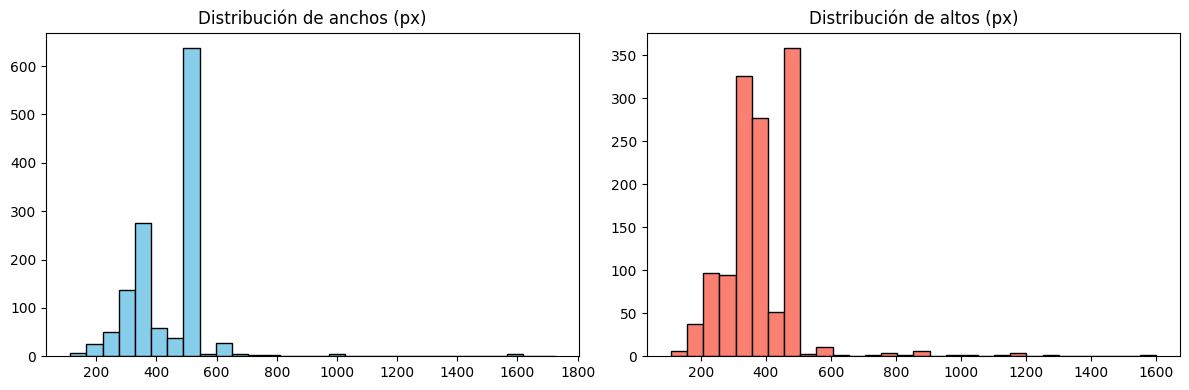

In [7]:
# ==========================================
# EDA: CALIDAD DE DATOS Y DIMENSIONES (100% del set de entrenamiento de ambos subconjuntos)
# ==========================================
anchos, altos, modos, corruptas = [], [], [], []
for nombre, sp in SPLITS.items():
    for r in sp["train"]["ruta"]:
        try:
            with Image.open(r) as im:
                im.load()                       # fuerza la lectura completa: detecta archivos dañados
                anchos.append(im.size[0]); altos.append(im.size[1]); modos.append(im.mode)
        except Exception as e:
            corruptas.append((r, str(e)))

print(f"Imágenes analizadas: {len(anchos)}")
print(f"Ancho: min {min(anchos)} | max {max(anchos)} | media {np.mean(anchos):.0f} | mediana {np.median(anchos):.0f}")
print(f"Alto:  min {min(altos)} | max {max(altos)} | media {np.mean(altos):.0f} | mediana {np.median(altos):.0f}")
print(f"Modos de color: {dict(Counter(modos))}")
print(f"Imágenes corruptas: {len(corruptas)}")

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].hist(anchos, bins=30, color="skyblue", edgecolor="black"); ejes[0].set_title("Distribución de anchos (px)")
ejes[1].hist(altos, bins=30, color="salmon", edgecolor="black"); ejes[1].set_title("Distribución de altos (px)")
plt.tight_layout(); guardar_fig("03_dimensiones"); plt.show()

### Interpretación de la calidad de datos y las dimensiones

**Dimensiones.** Se analizaron las 1.288 imágenes de entrenamiento de ambos subconjuntos. Los anchos van de 114 a 1.725 px (media 438, mediana 500) y los altos de 108 a 1.600 px (media 392, mediana 375). Según los histogramas, cerca de la mitad de las imágenes mide alrededor de 500 px de ancho (la barra más alta supera las 600 imágenes) y los altos se concentran entre 300 y 500 px, con una cola de imágenes más pequeñas y unas pocas de más de 1.000 px. Como en el ancho la media es menor que la mediana, esa cola de imágenes pequeñas es la que baja el promedio. Las imágenes no son cuadradas (la mediana es de 500x375, una proporción de 4:3), así que redimensionarlas a 64x64 las comprime horizontalmente en torno a un 25% respecto del alto. Esa deformación afecta a todas las imágenes por igual, y se acepta porque la CNN necesita una entrada de tamaño fijo; no se recorta, para no perder partes del animal. Esta decisión se contrasta con un recorte central que conserva la proporción en el experimento A7 del Anexo A (solo validación).

**Calidad de datos.** No hay imágenes corruptas (0 de 1.288). Todas están en modo RGB salvo una en modo RGBA (con canal de transparencia), que `load_img` convierte a RGB al cargarla, por lo que no requiere tratamiento manual.

**Coherencia con la EP1.** Estas estadísticas son idénticas a las reportadas en la EP1 para el mismo conjunto de entrenamiento, lo que es consistente con que el muestreo y la partición se hayan reproducido con las mismas semillas (no es una prueba de que las imágenes sean exactamente las mismas, pero sí una comprobación razonable).

**Implicancia para el modelado.** El tamaño de entrada de 64x64 reduce las imágenes originales (de entre 108 y 1.725 px) a una fracción pequeña de su resolución, por lo que se pierde detalle fino (manchas, rayas, largo del pelo). Es una limitación declarada y una de las posibles explicaciones de las confusiones que se analizan más adelante (hipótesis, no probada).

In [8]:
# ==========================================
# EDA: ¿PARECIDAS ES REALMENTE MÁS PARECIDO? (solo entrenamiento, antes de entrenar ningún modelo)
# Dos medidas entre pares de razas (más bajo = más parecidas):
#  1) distancia entre histogramas de color promedio (0 = idénticos, 1 = totalmente distintos)
#  2) distancia RMS entre las imágenes promedio de cada raza (píxel a píxel, valores en [0, 1])
# ==========================================
def hist_medio(X, bins=16):
    H = np.stack([np.concatenate([np.histogram(x[..., c], bins=bins, range=(0, 255))[0] for c in range(3)])
                  for x in X]).astype(float)
    return (H / H.sum(axis=1, keepdims=True)).mean(axis=0)

def similitud_clases(sp):
    clases, X, y = sp["clases"], sp["X_train"], sp["y_train"]
    H = [hist_medio(X[y == i]) for i in range(len(clases))]
    M = [X[y == i].mean(axis=0).ravel() / 255 for i in range(len(clases))]
    filas = []
    for i in range(len(clases)):
        for j in range(i + 1, len(clases)):
            filas.append(dict(par=f"{clases[i]} - {clases[j]}",
                              dist_histograma=0.5 * np.abs(H[i] - H[j]).sum(),
                              dist_imagen_promedio=np.sqrt(np.mean((M[i] - M[j]) ** 2))))
    return pd.DataFrame(filas)

sim = {nombre: similitud_clases(sp) for nombre, sp in SPLITS.items()}
resumen_sim = pd.DataFrame({nombre: d[["dist_histograma", "dist_imagen_promedio"]].mean() for nombre, d in sim.items()})
print("Distancia promedio entre pares de razas (más baja = más parecidas):")
print(resumen_sim.round(4).to_string())
for medida in ["dist_histograma", "dist_imagen_promedio"]:
    d_par, d_dis = sim["parecidas"][medida].mean(), sim["distintas"][medida].mean()
    print(f"- Según {medida}: el subconjunto más parecido es '{'parecidas' if d_par < d_dis else 'distintas'}' "
          f"(parecidas={d_par:.4f} | distintas={d_dis:.4f})")
for nombre in SPLITS:
    fila = sim[nombre].sort_values("dist_histograma").iloc[0]
    print(f"Par más parecido en '{nombre}' (histograma): {fila['par']} ({fila['dist_histograma']:.4f})")
print()
for nombre in SPLITS:
    print(f"Todos los pares de '{nombre}', de más a menos parecidos (histograma):")
    print(sim[nombre].sort_values("dist_histograma").round(4).to_string(index=False), "\n")
resumen_sim.to_csv("resultados/similitud_subconjuntos.csv")

Distancia promedio entre pares de razas (más baja = más parecidas):
                      parecidas  distintas
dist_histograma          0.0854     0.1178
dist_imagen_promedio     0.0631     0.0830
- Según dist_histograma: el subconjunto más parecido es 'parecidas' (parecidas=0.0854 | distintas=0.1178)
- Según dist_imagen_promedio: el subconjunto más parecido es 'parecidas' (parecidas=0.0631 | distintas=0.0830)
Par más parecido en 'parecidas' (histograma): Birman - Siamese (0.0404)
Par más parecido en 'distintas' (histograma): Bengal - Abyssinian (0.0743)

Todos los pares de 'parecidas', de más a menos parecidos (histograma):
                 par  dist_histograma  dist_imagen_promedio
    Birman - Siamese           0.0404                0.0359
   Ragdoll - Persian           0.0628                0.0495
    Birman - Ragdoll           0.0707                0.0578
    Birman - Persian           0.0723                0.0460
Siamese - Maine_Coon           0.0780                0.0719
 Birman

### Interpretación de la similitud entre razas

Antes de entrenar cualquier modelo se midió la distancia entre pares de razas en el set de entrenamiento (a menor valor, más parecidas):

| Medida (promedio de los 10 pares de razas) | PARECIDAS | DISTINTAS |
|---|---|---|
| Distancia entre histogramas de color | 0,0854 | 0,1178 |
| Distancia entre imágenes promedio | 0,0631 | 0,0830 |

**Resultado general.** Con ambas medidas, PARECIDAS tiene distancias menores: unos 27% menos en el histograma de color y unos 24% menos en la imagen promedio. Esto respalda con datos el criterio con que se armaron los subconjuntos, y coincide con lo medido en la EP1 sobre el mismo conjunto de entrenamiento. El par más parecido de PARECIDAS (Birman - Siamese, 0,0404 en histograma) tiene una distancia unos 46% menor que la del par más parecido de DISTINTAS (Bengal - Abyssinian, 0,0743). Birman y Siamese comparten el patrón colorpoint, y Bengal y Abyssinian son las dos razas marrón-anaranjadas de DISTINTAS, algo que ya se notaba en los ejemplos del EDA.

**Matices que no se deben pasar por alto.**
- **DISTINTAS contiene un par muy cercano.** Según la distancia entre imágenes promedio, el par más parecido de todos los 20 pares es Bengal - Abyssinian (0,0313), incluso menor que el de Birman - Siamese (0,0359). Es decir, el subconjunto "distinto" no es uniformemente distinto, y esto anticipa la confusión que luego domina sus errores (Abyssinian clasificada como Bengal, sección 9).
- **Bombay es la raza más separada.** Sus cuatro pares tienen las cuatro distancias de histograma más grandes de DISTINTAS (entre 0,1353 y 0,1906), coherente con ser el negro liso del grupo y con que sea la raza que mejor reconoce la CNN en la semilla 101 (F1 0,764). Es una asociación observada, no una prueba.
- **PARECIDAS es relativamente parecida, pero no es homogénea.** Dentro del trío colorpoint, Birman - Siamese es el par más cercano (0,0404) y Birman - Ragdoll el tercero (0,0707), pero Ragdoll - Siamese está bastante más lejos (0,0912, el séptimo de 10 pares), y Ragdoll - Persian (0,0628) es más cercano que Birman - Ragdoll. Persian - Maine_Coon (0,1268) y Ragdoll - Maine_Coon (0,1384) son los dos pares más distantes del subconjunto: el pelaje largo que comparten Persian y Maine_Coon no aparece en el color, por lo que estas medidas no lo capturan.

**Relación con las hipótesis.** En la EP1 se formuló la hipótesis de que en PARECIDAS se confundiría sobre todo Birman con Siamese. Con el MLP no se cumplió (dominó Ragdoll como clase por defecto); con la CNN el par más confundido sí es Birman → Siamese (8 de 27, sección 9).

**Alcance y limitaciones.** Ambas medidas capturan solo color y apariencia global, no la forma local (orejas, hocico, contorno del cuerpo), por lo que son un indicador parcial del parecido visual. Con 10 pares por subconjunto y una sola medida de cada tipo, no se puede afirmar que todos los pares de PARECIDAS sean más cercanos que todos los de DISTINTAS (por ejemplo, Bengal - Abyssinian está entre los pares más cercanos de ambos subconjuntos), solo que el promedio lo es. Como la medición se hizo antes de entrenar cualquier modelo, no hubo necesidad de ajustar la selección de razas.

### 2.2.2 Imagen promedio y color medio por raza

Además de los ejemplos individuales, se calcula la **imagen promedio de cada raza** (el promedio píxel a píxel de sus imágenes de entrenamiento a 64x64) y el **color medio, brillo y contraste**. Sirven para ver patrones globales de color y composición antes de modelar, y respaldan con una vista directa la medición de similitud de la sección 2.2.1. Solo se usa el set de entrenamiento.

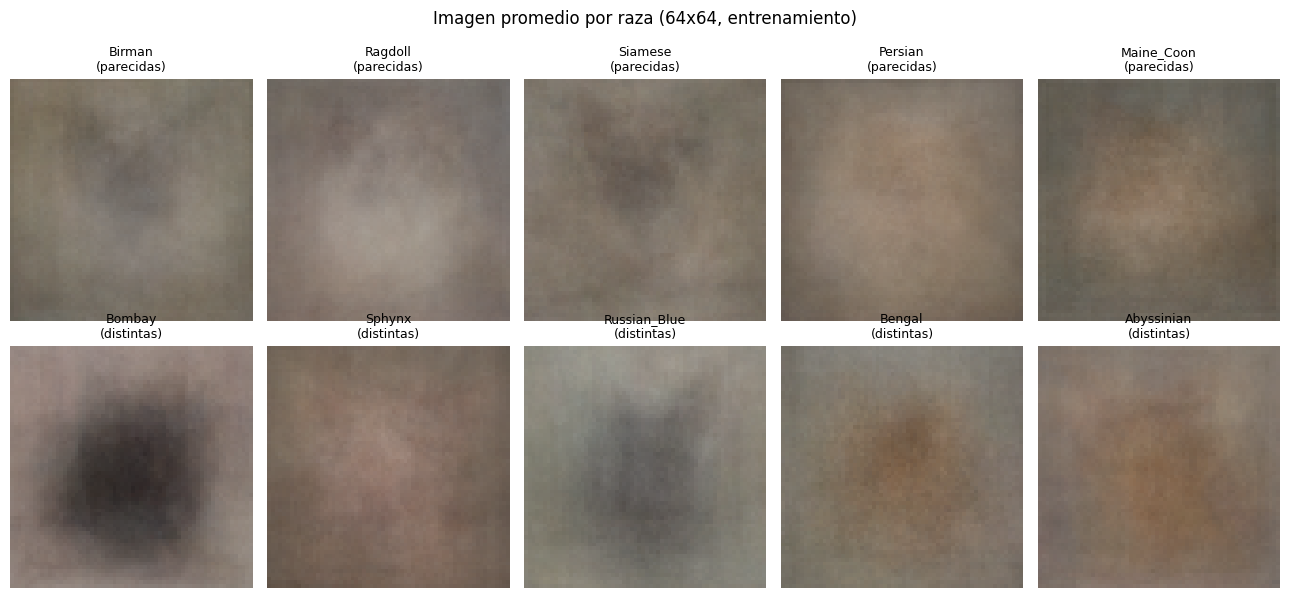

subconjunto         raza     R     G     B  brillo  contraste
  parecidas       Birman 0.485 0.455 0.408   0.449      0.271
  parecidas      Ragdoll 0.521 0.478 0.447   0.482      0.262
  parecidas      Siamese 0.485 0.447 0.401   0.444      0.277
  parecidas      Persian 0.519 0.463 0.405   0.462      0.261
  parecidas   Maine_Coon 0.442 0.401 0.347   0.397      0.268
  distintas       Bombay 0.446 0.399 0.378   0.408      0.310
  distintas       Sphynx 0.490 0.418 0.370   0.426      0.291
  distintas Russian_Blue 0.493 0.480 0.446   0.473      0.274
  distintas       Bengal 0.497 0.450 0.394   0.447      0.267
  distintas   Abyssinian 0.507 0.437 0.378   0.441      0.282


In [9]:
# ==========================================
# EDA: IMAGEN PROMEDIO POR RAZA Y COLOR MEDIO (solo entrenamiento)
# ==========================================
fig, ejes = plt.subplots(2, 5, figsize=(13, 6))
for fila, (nombre, sp) in enumerate(SPLITS.items()):
    for i, c in enumerate(sp["clases"]):
        media = sp["X_train"][sp["y_train"] == i].mean(axis=0) / 255.0
        ejes[fila, i].imshow(media); ejes[fila, i].axis("off")
        ejes[fila, i].set_title(f"{c}\n({nombre})", fontsize=9)
plt.suptitle("Imagen promedio por raza (64x64, entrenamiento)", y=1.0)
plt.tight_layout(); guardar_fig("02b_imagen_promedio"); plt.show()

filas = []
for nombre, sp in SPLITS.items():
    for i, c in enumerate(sp["clases"]):
        Xc = sp["X_train"][sp["y_train"] == i].astype("float32") / 255.0
        filas.append(dict(subconjunto=nombre, raza=c, R=Xc[..., 0].mean(), G=Xc[..., 1].mean(), B=Xc[..., 2].mean(),
                          brillo=Xc.mean(), contraste=Xc.std()))
color = pd.DataFrame(filas)
print(color.round(3).to_string(index=False))
color.to_csv("resultados/color_medio_por_raza.csv", index=False)

### Interpretación de las imágenes promedio y el color

Los promedios describen diferencias generales, pero mezclan animal, fondo, luz y encuadre. En PARECIDAS, Ragdoll tiene el mayor brillo (0,482) y Maine_Coon el menor (0,397); Birman y Siamese son cercanas (0,449 y 0,444), consistente con la cercanía de color observada antes. En DISTINTAS, Bombay tiene el menor brillo (0,408) y mayor contraste (0,310), compatible con pelaje negro y fondos variados. Sphynx muestra un promedio relativamente cálido (R 0,490; B 0,370). Son observaciones exploratorias, no prueba de qué rasgos usa el modelo.


### 2.3 Normalización y aumento de datos (dentro del modelo)

Para que la comparación con el MLP sea justa, la CNN recibe **el mismo tratamiento de entrada** que el modelo final de la EP1. Ambos pasos se implementan como capas dentro del modelo, así se aplican igual a entrenamiento, validación y prueba, y quedan guardados junto con él.

1. **Normalización a [0, 1]** con una capa `Rescaling(1/255)`: los píxeles pasan de 0-255 a 0-1, lo que hace el entrenamiento más estable.
2. **Estandarización por canal** con una capa `Normalization`: centra y escala cada canal de color (R, G, B). La media y la desviación se calculan **solo con el set de entrenamiento**, para no filtrar información de validación ni de prueba. En la EP1 esto fue lo que más ayudó al MLP.
3. **Aumento de datos solo en entrenamiento:** volteo horizontal, rotación de hasta ~20° y desplazamientos de hasta 10%. Simulan variaciones reales de cómo se fotografía un gato (cámara ladeada, animal descentrado). No se usa volteo vertical porque un gato cabeza abajo no es una situación realista. Estas capas solo actúan al entrenar; en validación y prueba no hacen nada.

Como hay solo 644 imágenes de entrenamiento, el aumento de datos funciona como una forma de regularización: cada época la red ve versiones ligeramente distintas de las mismas fotos, lo que dificulta que las memorice.

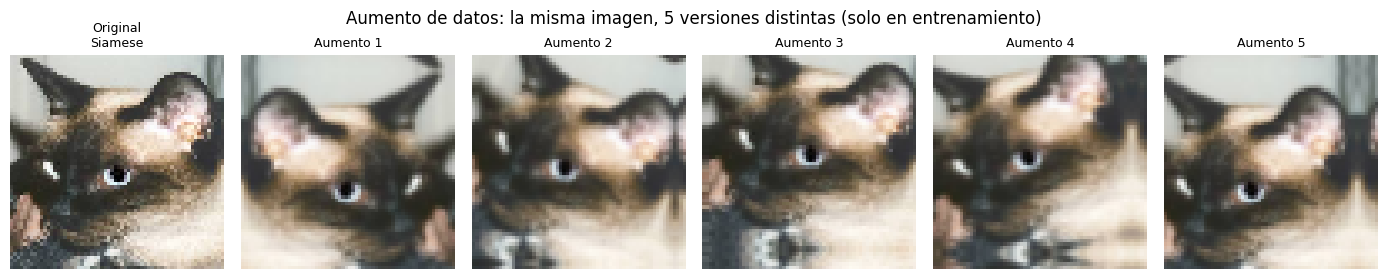

In [10]:
# ==========================================
# VERIFICACIÓN VISUAL DEL AUMENTO DE DATOS (una imagen de entrenamiento, 5 versiones)
# ==========================================
aumento_demo = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.055),
    layers.RandomTranslation(0.1, 0.1),
])

sp = SPLITS["parecidas"]
tf.keras.utils.set_random_seed(SEED_SPLIT)
img = sp["X_train"][0:1].astype("float32")
raza = sp["clases"][sp["y_train"][0]]

fig, ejes = plt.subplots(1, 6, figsize=(14, 2.8))
ejes[0].imshow(img[0].astype("uint8")); ejes[0].set_title(f"Original\n{raza}", fontsize=9); ejes[0].axis("off")
for k in range(1, 6):
    ejes[k].imshow(aumento_demo(img, training=True)[0].numpy().astype("uint8"))
    ejes[k].set_title(f"Aumento {k}", fontsize=9); ejes[k].axis("off")
plt.suptitle("Aumento de datos: la misma imagen, 5 versiones distintas (solo en entrenamiento)")
plt.tight_layout(); guardar_fig("03_aumento_datos"); plt.show()

**Interpretación del aumento de datos.** En las cinco versiones de la imagen de ejemplo el gato sigue siendo reconocible (ojos, orejas y patrón de la cara), pero cambian su posición, su inclinación y su orientación. Esa es la idea: la red debe reconocer la raza aunque la foto esté ladeada, volteada o descentrada. Dos observaciones: (1) cuando una imagen se desplaza o rota, los bordes que quedan vacíos se rellenan reflejando los píxeles vecinos, lo que genera pequeños artefactos (zonas "espejadas") visibles en las versiones 2 y 3; (2) la imagen de ejemplo es un primer plano, así que algunas versiones cortan parte de una oreja. Se considera aceptable porque la intensidad es moderada y solo se aplica en entrenamiento, pero es una limitación de este tipo de aumento.

### 2.4 Qué cambió respecto a la EP1 (adaptación para la CNN)

| Aspecto | EP1 (MLP) | EP2 (CNN) | Por qué |
|---|---|---|---|
| Razas, imágenes por raza y partición 70/15/15 | 5 + 5 razas, 184 por raza | **Idénticos** | Comparación justa y trazable |
| Semillas | 2604 (datos), 11-33 y 101-105 | **Idénticas** | Mismo reparto de imágenes |
| Formato de entrada | Aplanado a un vector de 12.288 valores | **Tensor (64, 64, 3)** | La convolución necesita la vecindad entre píxeles |
| Resolución | 64x64 (también se probó 96 y 128) | 64x64 de referencia, 128x128 como experimento | Misma información de entrada para comparar |
| Normalización y aumento de datos | `Rescaling`, estandarización, aumento | **Idénticos** | Aislar el efecto de la convolución |
| Tipo de dato guardado | `float32` | `uint8` | Menos memoria; la normalización la hace el modelo |

## 3. Diseño de la Red Neuronal Convolucional

Se define **K0** como CNN base: una arquitectura inicial compacta para medir cuánto aporta la convolución frente al MLP. K0 usa 3 bloques con 32, 64 y 128 filtros. Tras seleccionar hiperparámetros usando únicamente validación, la configuración final se toma dinámicamente de esa selección. En la ejecución preparada se espera K1 (dropout 0,5), que conserva los filtros 32-64-128 de K0 y cambia solo el dropout. Las curvas de la sección 4 corresponden a K0; las métricas finales y la comparación con el MLP corresponden a la configuración elegida en la sección 5. Cada decisión se justifica por las características del problema (5 clases, imágenes de 64x64x3, solo 644 imágenes de entrenamiento).

**Estructura:** 3 bloques `Conv2D + MaxPooling` → `GlobalAveragePooling` → capa densa → salida softmax. Antes de las convoluciones van las capas de aumento, `Rescaling` y `Normalization` (sección 2.3).

| Componente | K0 (base) | Justificación |
|---|---|---|
| **Capas convolucionales** | 3 (32, 64 y 128 filtros); la selección final usa los filtros de la configuración elegida; K1 conserva 32, 64 y 128 | Cada capa detecta patrones sobre lo que encontró la anterior: la primera tiende a responder a bordes y colores simples, la segunda a texturas y combinaciones de bordes, y la tercera a combinaciones más amplias (**hipótesis**: se contrasta con los feature maps de la sección 8; el campo receptivo de `conv3` es de 18x18 píxeles, sección 3.2, así que ve partes locales y no la cabeza completa). Más filtros en las capas profundas porque ahí hay más combinaciones posibles. Con 644 imágenes, 3 capas es una profundidad moderada que evita memorizar. |
| **Tamaño del filtro** | 3x3, `padding="same"` | Es el tamaño estándar: ve un vecindario pequeño y barato en parámetros. Apilar capas de 3x3 permite "ver" zonas cada vez más grandes de la imagen. `same` conserva el tamaño del mapa para que solo el pooling lo reduzca. |
| **Activación** | ReLU | Igual que en el MLP: no se satura con valores positivos y es barata de calcular. |
| **Pooling** | MaxPooling 2x2 después de cada convolución | Reduce el mapa a la mitad (64→32→16→8) quedándose con la respuesta más fuerte de cada zona de 2x2. Disminuye parámetros y cálculo, y da cierta tolerancia a que el rasgo esté un poco corrido. |
| **Paso a la parte densa** | `GlobalAveragePooling2D` | Promedia cada mapa de características en un solo número (128 valores). Evita un `Flatten` de 8·8·128 = 8.192 valores, que conectado a la capa densa de 64 neuronas aportaría 524.352 parámetros (en vez de los 8.256 actuales) y llevaría el modelo de 101.836 a unos 617.900. Además permite obtener mapas de activación por clase más adelante. |
| **Capa densa final** | `Dense(64)` + ReLU + `Dropout(0,3)` | Combina los 128 rasgos para decidir la raza. Tamaño pequeño porque ya vienen resumidos. Dropout 0,3 como en el MLP, por el riesgo de memorización. |
| **Salida** | `Dense(5)` con softmax | 5 razas excluyentes: softmax entrega una probabilidad por raza que suma 1. |
| **Función de pérdida** | `sparse_categorical_crossentropy` | Etiquetas enteras (0 a 4) y salida softmax, igual que el MLP. |
| **Optimizador** | Adam, learning rate 1e-3 | Adam ajusta el paso de cada peso por separado. 1e-3 es el valor habitual para CNN; el MLP necesitó 1e-4 porque trabajaba con 12.288 entradas aplanadas. Se verificará con un experimento. |
| **Batch size** | 32 | Igual que el MLP. |
| **EarlyStopping** | monitorea `val_loss`, paciencia 15, restaura los mejores pesos | El número de épocas lo decide la validación, no un número fijo. |

**Lo que se mantiene igual que el MLP** (entrada, normalización, aumento, pérdida, batch, semillas) y **lo que cambia** (la convolución y el pooling en lugar de aplanar) queda explícito para que cualquier diferencia de resultados pueda atribuirse a la arquitectura.

In [11]:
# ==========================================
# FUNCIÓN QUE CONSTRUYE LA CNN + RESUMEN DE LA ARQUITECTURA
# ==========================================
from tensorflow.keras import regularizers

def crear_cnn(n_clases, filtros=(32, 64, 128), kernel=3, densa=64, dropout=0.3, lr=1e-3, l2=0.0,
              aumento=True, X_adapt=None, resolucion=RES_BASE):
    reg = regularizers.l2(l2) if l2 > 0 else None
    capas = [layers.Input(shape=(resolucion, resolucion, 3))]
    if aumento:   # solo actúan durante el entrenamiento
        capas += [layers.RandomFlip("horizontal"), layers.RandomRotation(0.055),
                  layers.RandomTranslation(0.1, 0.1)]
    capas.append(layers.Rescaling(1 / 255))
    norm = layers.Normalization(axis=-1)
    norm.adapt(X_adapt.astype("float32") / 255.0)      # media y desviación SOLO con entrenamiento
    capas.append(norm)
    for i, f in enumerate(filtros, start=1):
        capas.append(layers.Conv2D(f, kernel, padding="same", activation="relu",
                                   kernel_regularizer=reg, name=f"conv{i}"))
        capas.append(layers.MaxPooling2D(2, name=f"pool{i}"))
    capas.append(layers.GlobalAveragePooling2D(name="gap"))
    capas.append(layers.Dense(densa, activation="relu", kernel_regularizer=reg))
    capas.append(layers.Dropout(dropout))
    capas.append(layers.Dense(n_clases, activation="softmax"))
    m = models.Sequential(capas)
    m.compile(optimizer=optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

sp = SPLITS["parecidas"]
cnn_demo = crear_cnn(len(sp["clases"]), X_adapt=sp["X_train"])
cnn_demo.summary()

# Cálculo a mano de los parámetros de cada capa convolucional: (alto x ancho x canales de entrada + 1) x filtros
entrada = 3
for f in (32, 64, 128):
    print(f"Conv {f} filtros: (3x3x{entrada} + 1) x {f} = {(3*3*entrada + 1) * f:,} parámetros")
    entrada = f

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_1            │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization (Normalization)   │ (None, 64, 64, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,836 (397.80 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 7 (32.00 B)

Conv 32 filtros: (3x3x3 + 1) x 32 = 896 parámetros
Conv 64 filtros: (3x3x32 + 1) x 64 = 18,496 parámetros
Conv 128 filtros: (3x3x64 + 1) x 128 = 73,856 parámetros


### Interpretación de la arquitectura

La CNN tiene **101.836 parámetros** frente a 1.573.644 del MLP (unas **15,5 veces menos**). Las convoluciones aportan 93.248 parámetros (91,6%) y la tercera capa 73.856. El uso compartido de filtros y GAP explica la reducción. El resultado respalda la hipótesis de menor tamaño, pero no garantiza mayor desempeño ni rapidez: K1 supera al MLP en DISTINTAS, no en PARECIDAS, y tarda más en esta corrida.


### 3.1 Cómo funcionan la convolución y el pooling

**Convolución.** Un filtro (o *kernel*) pequeño, por ejemplo de 3x3, se desliza por la imagen. En cada posición multiplica sus pesos por los píxeles que cubre y suma el resultado (más un sesgo): ese número es un píxel del **mapa de características**. Lo que el filtro "busca" lo decide el entrenamiento. Con `padding="same"` el mapa conserva el tamaño de la entrada; sin relleno (`valid`) el tamaño de salida es (N − K + 2P) / S + 1 (N entrada, K filtro, P relleno, S paso).

**Pooling.** El max pooling de 2x2 divide el mapa en bloques de 2x2 y conserva el valor máximo de cada uno. No tiene parámetros, reduce el tamaño a la mitad y da tolerancia a pequeños desplazamientos del rasgo.

**Comparación con el MLP.** El MLP aplana la imagen (12.288 valores) y cada neurona de la primera capa tiene **un peso por píxel y por posición**: no sabe qué píxel está al lado de cuál y lo aprendido en una zona no se reutiliza en otra. Un filtro 3x3x3 tiene solo 28 parámetros y **los mismos pesos en todas las posiciones**, así detecta el mismo rasgo donde aparezca y conserva la vecindad. Por eso se espera que extraiga rasgos locales con muchos menos parámetros.

**Mismo principio en otros tipos de datos.** En una serie de tiempo o en audio la convolución es 1D: el filtro se desliza en el tiempo y detecta patrones (subidas, picos) sin importar cuándo ocurren. En texto, filtros 1D recorren ventanas de palabras. A continuación se muestra un ejemplo a mano en 2D (imagen) y otro en 1D (serie), y la misma operación sobre una foto real.

Mapa de características (4x4):
 [[ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]
 [ 0. 27. 27.  0.]]
Después de ReLU y max pooling 2x2 (2x2):
 [[27. 27.]
 [27. 27.]]
Parámetros de un filtro 3x3x3 con sesgo: 28 | pesos de UNA neurona del MLP: 12289

Serie: [2, 2, 2, 2, 8, 8, 8, 8, 3, 3]
Respuesta del filtro 1D: [0, 0, 6, 6, 0, 0, -5, -5] -> positiva en la subida, negativa en la bajada


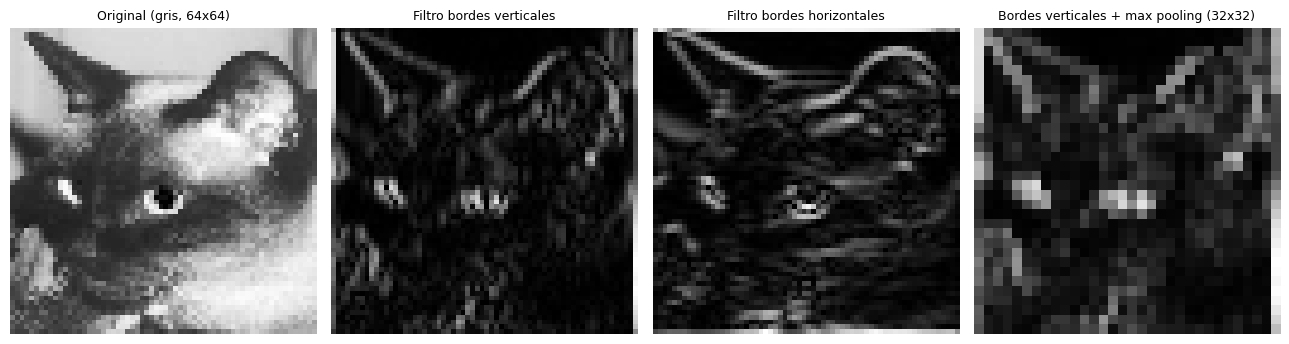

In [12]:
# ==========================================
# 3.1 EJEMPLOS A MANO: CONVOLUCIÓN 2D, POOLING Y CONVOLUCIÓN 1D
# ==========================================
# --- Ejemplo 2D: un borde vertical (columnas 0-2 oscuras, 3-5 claras) ---
X = np.array([[0, 0, 0, 9, 9, 9]] * 6, dtype="float32")
K = np.array([[-1, 0, 1]] * 3, dtype="float32")          # filtro: derecha menos izquierda (borde vertical)

salida = np.zeros((4, 4), dtype="float32")               # (6 - 3 + 0)/1 + 1 = 4
for i in range(4):
    for j in range(4):
        salida[i, j] = (X[i:i + 3, j:j + 3] * K).sum()
relu = np.maximum(salida, 0)
pool = relu.reshape(2, 2, 2, 2).max(axis=(1, 3))         # max pooling 2x2

# Verificación con TensorFlow (tf.nn.conv2d calcula la misma operación)
tf_out = tf.nn.conv2d(X[None, :, :, None], K[:, :, None, None], strides=1, padding="VALID").numpy()[0, :, :, 0]
assert np.allclose(salida, tf_out)
print("Mapa de características (4x4):\n", salida)
print("Después de ReLU y max pooling 2x2 (2x2):\n", pool)
print("Parámetros de un filtro 3x3x3 con sesgo:", 3 * 3 * 3 + 1, "| pesos de UNA neurona del MLP:", 64 * 64 * 3 + 1)

# --- Ejemplo 1D: serie con un salto (otro tipo de dato) ---
serie = np.array([2, 2, 2, 2, 8, 8, 8, 8, 3, 3], dtype="float32")
filtro1d = np.array([-1, 0, 1], dtype="float32")         # detecta cambios
resp = np.array([(serie[i:i + 3] * filtro1d).sum() for i in range(len(serie) - 2)])
print("\nSerie:", serie.astype(int).tolist())
print("Respuesta del filtro 1D:", resp.astype(int).tolist(), "-> positiva en la subida, negativa en la bajada")

# --- Sobre una foto real: bordes verticales y horizontales + pooling ---
img = SPLITS["parecidas"]["X_train"][0].astype("float32").mean(axis=2) / 255.0   # a gris
kv = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype="float32")             # Sobel vertical
kh = kv.T                                                                         # Sobel horizontal
def conv(imagen, k):
    return tf.nn.conv2d(imagen[None, :, :, None], k[:, :, None, None], strides=1, padding="SAME").numpy()[0, :, :, 0]
bv, bh = np.abs(conv(img, kv)), np.abs(conv(img, kh))
bv_pool = tf.nn.max_pool2d(bv[None, :, :, None], 2, 2, "VALID").numpy()[0, :, :, 0]

fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, im, t in zip(ejes, [img, bv, bh, bv_pool],
                     ["Original (gris, 64x64)", "Filtro bordes verticales", "Filtro bordes horizontales", "Bordes verticales + max pooling (32x32)"]):
    ax.imshow(im, cmap="gray"); ax.set_title(t, fontsize=9); ax.axis("off")
plt.tight_layout(); guardar_fig("00_convolucion_pooling_ejemplo"); plt.show()

**Interpretación.** En el ejemplo 2D el filtro responde con 27 justo donde hay un borde vertical (columnas 1 y 2 del mapa) y con 0 en las zonas uniformes; el max pooling resume esa respuesta en un mapa más pequeño (2x2). En 1D el mismo mecanismo detecta la subida (+6) y la bajada (−5) de una serie, sin importar en qué posición ocurran. En la foto real, los dos filtros de Sobel resaltan contornos distintos (verticales y horizontales); en la CNN esos filtros **no se diseñan a mano: se aprenden** para la tarea, y se apilan para combinar bordes en texturas y partes. Una neurona del MLP necesita 12.289 pesos solo para mirar una vez la imagen; un filtro 3x3x3 usa 28 y se reutiliza en toda la imagen, que es la razón por la que la CNN de este trabajo tiene decenas de miles de parámetros y el MLP más de un millón y medio.

### 3.2 Arquitectura de la CNN final seleccionada: resumen, parámetros y campo receptivo

**Aclaración.** La arquitectura base K0 usa 32-64-128 filtros y 101.836 parámetros. La evaluación final usa la configuración elegida en la sección 5; se seleccionó **K1 (dropout 0,5)**, que mantiene los mismos filtros y parámetros que K0. Se muestra su resumen, el cálculo de sus parámetros a mano y el **campo receptivo** de cada capa (cuántos píxeles de la imagen original influyen en una neurona).

In [13]:
# ==========================================
# ARQUITECTURA BASE K0 / FINAL ESPERADA K1: RESUMEN, PARÁMETROS A MANO Y CAMPO RECEPTIVO
# ==========================================
sp = SPLITS["parecidas"]
cnn_k3_demo = crear_cnn(len(sp["clases"]), filtros=(32, 64, 128), dropout=0.5, X_adapt=sp["X_train"])
cnn_k3_demo.summary()

entrada, total = 3, 7                                   # 7 = parámetros de la capa Normalization
for f in (32, 64, 128):
    p = (3 * 3 * entrada + 1) * f
    total += p
    print(f"Conv {f} filtros: (3x3x{entrada} + 1) x {f} = {p:,} parámetros")
    entrada = f
p_d1, p_d2 = (entrada + 1) * 64, (64 + 1) * 5
total += p_d1 + p_d2
print(f"Dense(64): ({entrada} + 1) x 64 = {p_d1:,} | Dense(5): (64 + 1) x 5 = {p_d2:,}")
print(f"Total calculado a mano (con Normalization): {total:,} | Keras: {cnn_k3_demo.count_params():,}")
assert total == cnn_k3_demo.count_params()

# Campo receptivo: cuántos píxeles de entrada influyen en una neurona de cada capa
def campo_receptivo(capas):
    rf, salto, filas = 1, 1, []
    for nombre, k, s in capas:
        rf += (k - 1) * salto
        salto *= s
        filas.append((nombre, rf, salto))
    return filas

arquitectura = [("conv1", 3, 1), ("pool1", 2, 2), ("conv2", 3, 1), ("pool2", 2, 2), ("conv3", 3, 1)]
print("\nCampo receptivo (píxeles de entrada que influyen en una neurona):")
for nombre, rf, salto in campo_receptivo(arquitectura):
    print(f"  {nombre}: {rf}x{rf} px de la imagen de {RES_BASE}x{RES_BASE} ({rf / RES_BASE:.0%} del lado)")

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_2 (RandomFlip)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_2               │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation_2            │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalization_1 (Normalization) │ (None, 64, 64, 3)      │             7 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1 (Conv2D)                  │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool1 (MaxPooling2D)            │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2 (Conv2D)                  │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool2 (MaxPooling2D)            │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv3 (Conv2D)                  │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ pool3 (MaxPooling2D)            │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,836 (397.80 KB)

 Trainable params: 101,829 (397.77 KB)

 Non-trainable params: 7 (32.00 B)

Conv 32 filtros: (3x3x3 + 1) x 32 = 896 parámetros
Conv 64 filtros: (3x3x32 + 1) x 64 = 18,496 parámetros
Conv 128 filtros: (3x3x64 + 1) x 128 = 73,856 parámetros
Dense(64): (128 + 1) x 64 = 8,256 | Dense(5): (64 + 1) x 5 = 325
Total calculado a mano (con Normalization): 101,836 | Keras: 101,836

Campo receptivo (píxeles de entrada que influyen en una neurona):
  conv1: 3x3 px de la imagen de 64x64 (5% del lado)
  pool1: 4x4 px de la imagen de 64x64 (6% del lado)
  conv2: 8x8 px de la imagen de 64x64 (12% del lado)
  pool2: 10x10 px de la imagen de 64x64 (16% del lado)
  conv3: 18x18 px de la imagen de 64x64 (28% del lado)


**Interpretación.** El resumen confirma **101.836 parámetros** en K0/K1: 101.829 entrenables y 7 de Normalization (896 + 18.496 + 73.856 en convoluciones, 8.256 en Dense y 325 en salida). El campo receptivo crece de 3x3 en conv1 a 8x8 en conv2 y 18x18 en conv3; cada neurona final observa una región local. GAP reduce parámetros, pero promedia la ubicación espacial. En el anexo, Flatten mejora el F1 de validación en esta exploración.


## 4. Entrenamiento del modelo

Se entrena la CNN base **K0 (32-64-128 filtros)** sobre PARECIDAS con la primera semilla final (101) y se registra el comportamiento del aprendizaje época por época. Se grafican las curvas de pérdida y accuracy de entrenamiento y validación, y se interpretan con dos referencias:
- **El azar:** accuracy de 0,20 y pérdida de ln 5 ≈ 1,609 (lo que tendría un modelo que asigna 20% a cada raza).
- **La brecha** entre entrenamiento y validación: si el entrenamiento mejora y la validación se estanca o empeora, hay sobreajuste; si ambos se quedan cerca del azar, hay subajuste.

**Estrategia de entrenamiento:** optimizador Adam (learning rate 1e-3), batch de 32, hasta 100 épocas máximo, con `EarlyStopping` sobre la pérdida de validación (paciencia 15, restaura los mejores pesos). El número de épocas lo decide la validación y no una cifra fijada a ojo. También se mide el **tiempo de entrenamiento**, que la pauta pide comparar con el MLP.

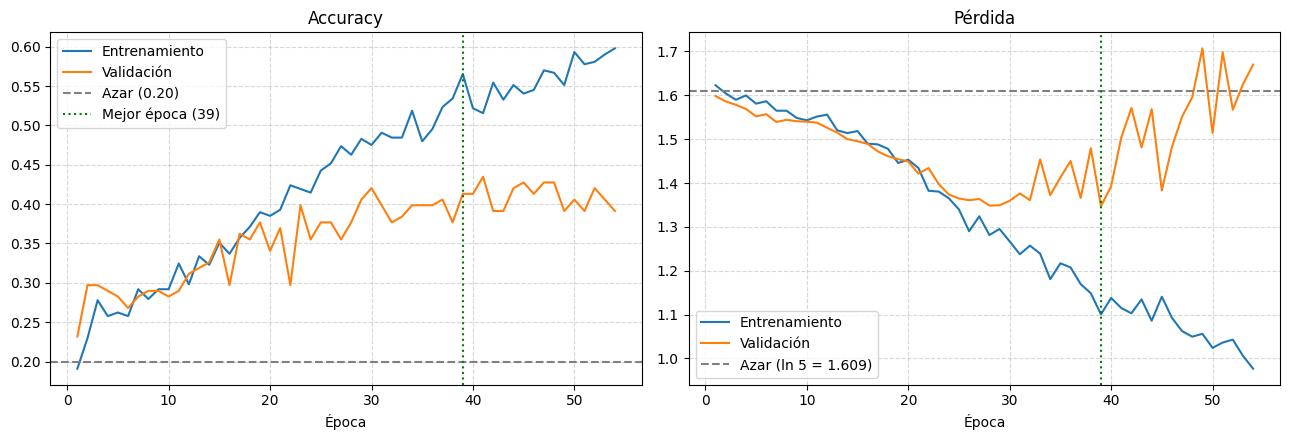

Parámetros: 101,836 | tiempo de entrenamiento: 24.4 s
Épocas entrenadas: 54 | mejor época según val_loss: 39
Accuracy entrenamiento (con aumento y dropout activos): 0.565 | validación: 0.413 | azar: 0.200
Pérdida validación: 1.347 | pérdida del azar ln(5): 1.609
Brecha entrenamiento - validación: +0.152


In [14]:
# ==========================================
# FUNCIONES DE ENTRENAMIENTO Y MÉTRICAS
# ==========================================
EPOCAS_MAX = 100
BATCH_SIZE = 32
PACIENCIA = 15

def metricas(modelo, X, y):
    pred = modelo.predict(X, verbose=0).argmax(axis=1)
    rec = recall_score(y, pred, average=None, zero_division=0)
    met = dict(acc=accuracy_score(y, pred),
               precision=precision_score(y, pred, average="macro", zero_division=0),
               recall=recall_score(y, pred, average="macro", zero_division=0),
               f1=f1_score(y, pred, average="macro", zero_division=0),
               recall_min=rec.min())
    return met, pred

def entrenar_cnn(sp, seed, **cfg):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    cfg = dict(cfg)
    batch = cfg.pop("batch", BATCH_SIZE)
    pac = cfg.pop("paciencia", PACIENCIA)
    D = sp["XR"][cfg.get("resolucion", RES_BASE)]
    m = crear_cnn(len(sp["clases"]), X_adapt=D["train"], **cfg)
    es = EarlyStopping(monitor="val_loss", patience=pac, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(D["train"], sp["y_train"], validation_data=(D["val"], sp["y_val"]),
              epochs=EPOCAS_MAX, batch_size=batch, callbacks=[es], verbose=0)
    return m, h, time.time() - t0

# ==========================================
# ENTRENAMIENTO DE LA CNN BASE K0 (32-64-128; PARECIDAS, semilla 101) + CURVAS
# ==========================================
sp = SPLITS["parecidas"]; n = len(sp["clases"])
modelo_cnn, hist_cnn, seg_cnn = entrenar_cnn(sp, SEEDS_FINAL[0])
h = hist_cnn.history
mejor_ep = int(np.argmin(h["val_loss"]))
ep = range(1, len(h["loss"]) + 1)

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
ejes[0].plot(ep, h["accuracy"], label="Entrenamiento"); ejes[0].plot(ep, h["val_accuracy"], label="Validación")
ejes[0].axhline(1 / n, color="gray", linestyle="--", label=f"Azar ({1/n:.2f})")
ejes[0].axvline(mejor_ep + 1, color="green", linestyle=":", label=f"Mejor época ({mejor_ep + 1})")
ejes[0].set_title("Accuracy"); ejes[0].set_xlabel("Época"); ejes[0].legend(); ejes[0].grid(True, linestyle="--", alpha=0.5)
ejes[1].plot(ep, h["loss"], label="Entrenamiento"); ejes[1].plot(ep, h["val_loss"], label="Validación")
ejes[1].axhline(np.log(n), color="gray", linestyle="--", label=f"Azar (ln {n} = {np.log(n):.3f})")
ejes[1].axvline(mejor_ep + 1, color="green", linestyle=":")
ejes[1].set_title("Pérdida"); ejes[1].set_xlabel("Época"); ejes[1].legend(); ejes[1].grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("04_curvas_cnn_base"); plt.show()

acc_tr, acc_va = h["accuracy"][mejor_ep], h["val_accuracy"][mejor_ep]
print(f"Parámetros: {modelo_cnn.count_params():,} | tiempo de entrenamiento: {seg_cnn:.1f} s")
print(f"Épocas entrenadas: {len(h['loss'])} | mejor época según val_loss: {mejor_ep + 1}")
print(f"Accuracy entrenamiento (con aumento y dropout activos): {acc_tr:.3f} | validación: {acc_va:.3f} | azar: {1/n:.3f}")
print(f"Pérdida validación: {h['val_loss'][mejor_ep]:.3f} | pérdida del azar ln({n}): {np.log(n):.3f}")
print(f"Brecha entrenamiento - validación: {acc_tr - acc_va:+.3f}")

In [15]:
# ==========================================
# VALORES EXACTOS DE LAS CURVAS (para citarlos en el texto)
# ==========================================
hh = hist_cnn.history
print(f"Accuracy de validación: mín {min(hh['val_accuracy']):.3f} (época {int(np.argmin(hh['val_accuracy']))+1}) | máx {max(hh['val_accuracy']):.3f} (época {int(np.argmax(hh['val_accuracy']))+1})")
print(f"Pérdida de validación: mín {min(hh['val_loss']):.3f} (época {int(np.argmin(hh['val_loss']))+1}) | máx {max(hh['val_loss']):.3f} (época {int(np.argmax(hh['val_loss']))+1})")
print(f"Accuracy de entrenamiento: última época {hh['accuracy'][-1]:.3f} | máximo {max(hh['accuracy']):.3f}")
print(f"Pérdida de entrenamiento: última época {hh['loss'][-1]:.3f}")

Accuracy de validación: mín 0.232 (época 1) | máx 0.435 (época 41)
Pérdida de validación: mín 1.347 (época 39) | máx 1.707 (época 49)
Accuracy de entrenamiento: última época 0.598 | máximo 0.598
Pérdida de entrenamiento: última época 0.977


### Interpretación de las curvas de la CNN base K0

K0 entrenó **54 épocas** y conservó los pesos de la **época 39**, con val_loss mínima **1,347** frente al azar 1,609. Accuracy en esa época: 0,565 en entrenamiento y 0,413 en validación (brecha 0,152). La validación llegó a accuracy máximo 0,435 en época 41, pero su pérdida alcanzó 1,707 en época 49. Al final, entrenamiento siguió mejorando mientras validación ya no lo hacía: hay señales de sobreajuste tardío. El entrenamiento tomó 24,4 s con GPU en esta sesión; el tiempo depende del entorno.

La val_loss mínima de K0 fue menor que la del MLP reentrenado con semilla 101 (1,559), pero su val_accuracy fue levemente menor (0,413 vs 0,420). Es diagnóstico de una sola semilla, no comparación concluyente; motivó experimentar regularización.


## 5. Experimentación y selección de la configuración de la CNN

**Por qué.** Las curvas de la CNN base mostraron sobreajuste después de la época 39 (la pérdida de validación subió hasta 1,707 mientras la de entrenamiento seguía bajando). Para decidir con datos cómo corregirlo, y para que la comparación con el MLP sea justa (el MLP de la EP1 pasó por una ronda de ajuste), se prueban cuatro cambios sobre la CNN base.

**Diseño (definido antes de ejecutar).** Se cambia **un factor a la vez** sobre la base K0, en el subconjunto **PARECIDAS**, con **3 semillas** de inicialización (11, 22 y 33) y se reporta media ± desviación estándar, porque con 138 imágenes de validación una sola ejecución es muy ruidosa. Las métricas se calculan en **validación**; el set de prueba no se usa en esta sección.

| Config | Cambio respecto a la base | Qué se quiere probar |
|---|---|---|
| K0 | Ninguno (32-64-128 filtros, dropout 0,3, lr 1e-3) | Referencia |
| K1 | Dropout 0,5 | Más regularización en la capa densa |
| K2 | Learning rate 3e-4 | Aprendizaje más lento y estable, con menos picos en la validación |
| K3 | Filtros 16-32-64 | Menos capacidad, menos riesgo de memorizar |
| K4 | Regularización L2 de 1e-3 en convoluciones y capa densa | Penalizar pesos grandes |

**Criterio de selección (igual al de la EP1):** se elige la configuración con **mayor F1 macro de validación promedio**. Si otras quedan dentro de **una desviación estándar** de la mejor, se prefiere la de **menos parámetros**; si empatan en parámetros, gana la de mayor F1.

**Transparencia.** El diseño de esta ronda se hizo después de ver las curvas de la CNN base (una semilla, sobre validación), pero antes de mirar el set de prueba, que no se ha usado.

**Limitaciones.** Cambiar un factor a la vez no explora interacciones entre factores. Son 15 entrenamientos, bastante menos que los ~87 del MLP en la EP1, así que la CNN queda menos ajustada que el MLP. Una sola partición de datos y 3 semillas.

In [16]:
# ==========================================
# EJECUCIÓN DE LOS EXPERIMENTOS DE LA CNN (PARECIDAS, métricas en VALIDACIÓN)
# ==========================================
BASE_CNN = dict(filtros=(32, 64, 128), densa=64, dropout=0.3, lr=1e-3, l2=0.0, aumento=True)
CONFIGS_CNN = {
    "K0 base": {},
    "K1 dropout 0,5": dict(dropout=0.5),
    "K2 lr 3e-4": dict(lr=3e-4),
    "K3 filtros 16-32-64": dict(filtros=(16, 32, 64)),
    "K4 L2 1e-3": dict(l2=1e-3),
}

sp = SPLITS["parecidas"]
filas = []
for nombre, cambios in CONFIGS_CNN.items():
    cfg = {**BASE_CNN, **cambios}
    for s in SEEDS_EXP:
        m, h, seg = entrenar_cnn(sp, s, **cfg)
        met, _ = metricas(m, sp["X_val"], sp["y_val"])
        mejor_ep = int(np.argmin(h.history["val_loss"]))
        n_ep = len(h.history["loss"])
        filas.append(dict(config=nombre, semilla=s, parametros=m.count_params(),
                          epoca_mejor=mejor_ep + 1, epocas_totales=n_ep, llego_al_tope=n_ep >= EPOCAS_MAX,
                          segundos=seg, acc_train=h.history["accuracy"][mejor_ep], acc_val=met["acc"],
                          f1_val=met["f1"], val_loss=min(h.history["val_loss"])))
        pd.DataFrame(filas).to_csv("resultados/experimentos_cnn_por_semilla.csv", index=False)   # guarda el avance
        print(f"{nombre} | semilla {s} | F1 val {met['f1']:.3f} | {n_ep} épocas | {seg/60:.1f} min")
    print(f"--> {nombre}: listo\n")

K0 base | semilla 11 | F1 val 0.384 | 61 épocas | 0.4 min
K0 base | semilla 22 | F1 val 0.323 | 32 épocas | 0.2 min
K0 base | semilla 33 | F1 val 0.360 | 46 épocas | 0.3 min
--> K0 base: listo

K1 dropout 0,5 | semilla 11 | F1 val 0.366 | 48 épocas | 0.3 min
K1 dropout 0,5 | semilla 22 | F1 val 0.363 | 33 épocas | 0.2 min
K1 dropout 0,5 | semilla 33 | F1 val 0.413 | 75 épocas | 0.4 min
--> K1 dropout 0,5: listo

K2 lr 3e-4 | semilla 11 | F1 val 0.248 | 22 épocas | 0.2 min
K2 lr 3e-4 | semilla 22 | F1 val 0.350 | 41 épocas | 0.3 min
K2 lr 3e-4 | semilla 33 | F1 val 0.331 | 44 épocas | 0.3 min
--> K2 lr 3e-4: listo

K3 filtros 16-32-64 | semilla 11 | F1 val 0.254 | 20 épocas | 0.1 min
K3 filtros 16-32-64 | semilla 22 | F1 val 0.343 | 32 épocas | 0.2 min
K3 filtros 16-32-64 | semilla 33 | F1 val 0.349 | 29 épocas | 0.2 min
--> K3 filtros 16-32-64: listo

K4 L2 1e-3 | semilla 11 | F1 val 0.262 | 24 épocas | 0.2 min
K4 L2 1e-3 | semilla 22 | F1 val 0.382 | 39 épocas | 0.3 min
K4 L2 1e-3 | s

### 5.1 Resultados de los experimentos

La tabla resume, para cada configuración, la **media de las 3 semillas** de las métricas en validación. Columnas: `f1_media` y `f1_std` (F1 macro y su variación entre semillas), `acc_val` y `acc_train` (accuracy de validación y de entrenamiento en la mejor época), `brecha` (entrenamiento menos validación), `val_loss` (mejor pérdida de validación), `epoca_mejor` y `minutos` (duración promedio). El gráfico muestra el F1 de cada semilla (puntos) junto a la media (barra) y su desviación estándar (línea). La configuración elegida se calcula aplicando el criterio definido en la sección 5.

                     parametros  f1_media  f1_std  acc_val  acc_train  brecha  val_loss  epoca_mejor  minutos
config                                                                                                       
K0 base                  101836     0.356   0.031    0.389      0.464   0.075     1.392       31.333    0.308
K1 dropout 0,5           101836     0.381   0.028    0.415      0.436   0.021     1.376       37.000    0.338
K2 lr 3e-4               101836     0.309   0.054    0.350      0.351   0.001     1.495       20.667    0.245
K3 filtros 16-32-64       28076     0.315   0.053    0.348      0.339  -0.009     1.484       12.000    0.167
K4 L2 1e-3               101836     0.336   0.065    0.370      0.375   0.006     1.544       21.333    0.244

Mejor F1 medio: K1 dropout 0,5 (0.381 ± 0.028) | umbral = 0.353
Dentro del umbral: ['K0 base', 'K1 dropout 0,5']
CONFIGURACIÓN ELEGIDA (menos parámetros dentro del umbral): K1 dropout 0,5


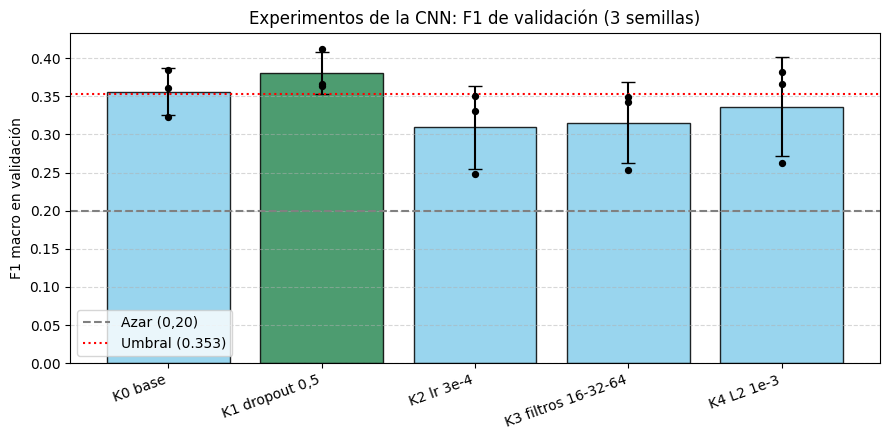

In [17]:
# ==========================================
# TABLA RESUMEN DE LOS EXPERIMENTOS DE LA CNN + SELECCIÓN SEGÚN EL CRITERIO
# ==========================================
df = pd.read_csv("resultados/experimentos_cnn_por_semilla.csv")
df["brecha"] = df["acc_train"] - df["acc_val"]

res = df.groupby("config", sort=False).agg(
    parametros=("parametros", "first"),
    f1_media=("f1_val", "mean"), f1_std=("f1_val", "std"),
    acc_val=("acc_val", "mean"), acc_train=("acc_train", "mean"), brecha=("brecha", "mean"),
    val_loss=("val_loss", "mean"), epoca_mejor=("epoca_mejor", "mean"),
    minutos=("segundos", lambda s: s.mean() / 60))
print(res.round(3).to_string())
res.to_csv("resultados/experimentos_cnn_resumen.csv")

# --- Criterio definido antes de ejecutar ---
mejor = res["f1_media"].idxmax()
umbral = res.loc[mejor, "f1_media"] - res.loc[mejor, "f1_std"]
candidatas = res[res["f1_media"] >= umbral]
elegida = candidatas.sort_values(["parametros", "f1_media"], ascending=[True, False]).index[0]
print(f"\nMejor F1 medio: {mejor} ({res.loc[mejor, 'f1_media']:.3f} ± {res.loc[mejor, 'f1_std']:.3f}) | umbral = {umbral:.3f}")
print("Dentro del umbral:", list(candidatas.index))
print(f"CONFIGURACIÓN ELEGIDA (menos parámetros dentro del umbral): {elegida}")

# --- Gráfico ---
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(res))
colores = ["seagreen" if c == elegida else "skyblue" for c in res.index]
ax.bar(x, res["f1_media"], yerr=res["f1_std"], capsize=5, color=colores, edgecolor="black", alpha=0.85)
for i, c in enumerate(res.index):
    pts = df[df["config"] == c]["f1_val"]
    ax.scatter([i] * len(pts), pts, color="black", s=18, zorder=3)
ax.axhline(0.2, color="gray", linestyle="--", label="Azar (0,20)")
ax.axhline(umbral, color="red", linestyle=":", label=f"Umbral ({umbral:.3f})")
ax.set_xticks(x); ax.set_xticklabels(res.index, rotation=20, ha="right")
ax.set_ylabel("F1 macro en validación"); ax.set_title("Experimentos de la CNN: F1 de validación (3 semillas)")
ax.legend(); ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("05_experimentos_cnn"); plt.show()

### Interpretación de los experimentos

K1 (dropout 0,5) tuvo el mayor F1 de validación: **0,381 ± 0,028**. El umbral de una desviación bajo el máximo es **0,353**; K0 (0,356 ± 0,031) y K1 quedan dentro. Ambas tienen 101.836 parámetros, así que el desempate por mayor F1 selecciona **K1**. K3, aunque tiene menos parámetros (28.076), queda fuera del umbral (0,315 ± 0,053); K2 y K4 también quedan fuera. La regla se aplicó correctamente, aunque con solo tres semillas no demuestra superioridad universal.


## 6. Evaluación final en el set de prueba

La configuración K1 (dropout 0,5), seleccionada únicamente con validación, se evaluó con cinco semillas (101 a 105) en ambos subconjuntos. El conjunto de prueba se reservó para estimar el desempeño final y no se usó para volver a seleccionar hiperparámetros.


In [18]:
# ==========================================
# EVALUACIÓN FINAL DE LA CNN SELECCIONADA EN PRUEBA: 2 subconjuntos x 5 semillas
# ==========================================
CFG_FINAL = dict(BASE_CNN, **CONFIGS_CNN[elegida])
print("Configuración final seleccionada:", elegida, CFG_FINAL)

filas_test = []
MODELOS, PREDS, HIST = {}, {}, {}
PROBS_CNN = {}      # probabilidades en prueba de las 5 semillas (para matrices agregadas, KPI complementario)
for nombre, sp in SPLITS.items():
    for s in SEEDS_FINAL:
        m, h, seg = entrenar_cnn(sp, s, **CFG_FINAL)
        met_te, pred_te = metricas(m, sp["X_test"], sp["y_test"])
        met_va, _ = metricas(m, sp["X_val"], sp["y_val"])
        PROBS_CNN[(nombre, s)] = m.predict(sp["X_test"], verbose=0)
        mejor_ep = int(np.argmin(h.history["val_loss"]))
        filas_test.append(dict(subconjunto=nombre, semilla=s, parametros=m.count_params(),
                               epoca_mejor=mejor_ep + 1, epocas_totales=len(h.history["loss"]), segundos=seg,
                               acc_train=h.history["accuracy"][mejor_ep],
                               acc_val=met_va["acc"], f1_val=met_va["f1"],
                               acc_test=met_te["acc"], precision_test=met_te["precision"],
                               recall_test=met_te["recall"], f1_test=met_te["f1"],
                               recall_min_test=met_te["recall_min"]))
        pd.DataFrame(filas_test).to_csv("resultados/cnn_final_por_semilla.csv", index=False)   # guarda el avance
        if s == SEEDS_FINAL[0]:                       # modelo "detallado": semilla 101
            MODELOS[nombre], PREDS[nombre], HIST[nombre] = m, pred_te, h.history
            m.save(f"models/cnn_k1_{nombre}_s{s}.keras")
        print(f"{nombre} | semilla {s} | F1 test {met_te['f1']:.3f} | acc test {met_te['acc']:.3f} | {len(h.history['loss'])} épocas | {seg/60:.1f} min")
    print()

res_te = pd.DataFrame(filas_test).groupby("subconjunto").agg(
    f1_test=("f1_test", "mean"), f1_test_std=("f1_test", "std"),
    acc_test=("acc_test", "mean"), acc_test_std=("acc_test", "std"),
    f1_val=("f1_val", "mean"), minutos=("segundos", lambda x: x.mean() / 60))
print(res_te.round(3).to_string())

Configuración final seleccionada: K1 dropout 0,5 {'filtros': (32, 64, 128), 'densa': 64, 'dropout': 0.5, 'lr': 0.001, 'l2': 0.0, 'aumento': True}
parecidas | semilla 101 | F1 test 0.385 | acc test 0.391 | 65 épocas | 0.4 min
parecidas | semilla 102 | F1 test 0.295 | acc test 0.326 | 32 épocas | 0.2 min
parecidas | semilla 103 | F1 test 0.401 | acc test 0.435 | 69 épocas | 0.4 min
parecidas | semilla 104 | F1 test 0.245 | acc test 0.275 | 40 épocas | 0.3 min
parecidas | semilla 105 | F1 test 0.322 | acc test 0.319 | 45 épocas | 0.3 min

distintas | semilla 101 | F1 test 0.589 | acc test 0.609 | 71 épocas | 0.5 min
distintas | semilla 102 | F1 test 0.543 | acc test 0.572 | 73 épocas | 0.5 min
distintas | semilla 103 | F1 test 0.373 | acc test 0.413 | 39 épocas | 0.3 min
distintas | semilla 104 | F1 test 0.545 | acc test 0.594 | 66 épocas | 0.4 min
distintas | semilla 105 | F1 test 0.541 | acc test 0.565 | 65 épocas | 0.4 min

             f1_test  f1_test_std  acc_test  acc_test_std  f1_

### 6.1 Resultados en prueba: métricas completas, KPIs y matriz de confusión

La primera tabla resume las métricas de las **5 semillas** (media ± desviación estándar). La segunda muestra cada semilla por separado, incluida la **época elegida** por `EarlyStopping`, porque ayuda a entender las semillas con peor resultado. Después se comprueban los **KPIs definidos en la EP1** (F1 macro ≥ 0,4 como principal y recall mínimo ≥ 0,2 como secundario). Por último, se muestran el reporte por raza y la **matriz de confusión** del modelo de la **semilla 101** para cada subconjunto: cada fila es la raza real y cada columna, la raza que predijo el modelo, así que lo que está fuera de la diagonal son confusiones. Como corresponde a una sola semilla, la matriz ilustra el comportamiento y no reemplaza a las métricas promedio.

RESUMEN EN PRUEBA (media ± desv. de 5 semillas)
                Accuracy Precision (macro) Recall (macro)       F1 macro  Recall mínimo
distintas  0.551 ± 0.079     0.560 ± 0.064  0.550 ± 0.078  0.518 ± 0.084  0.139 ± 0.083
parecidas  0.349 ± 0.063     0.341 ± 0.071  0.349 ± 0.064  0.330 ± 0.064  0.122 ± 0.102 

POR SEMILLA
subconjunto  semilla  epoca_mejor  acc_test  precision_test  recall_test  f1_test  recall_min_test
  parecidas      101           50     0.391           0.383        0.391    0.385            0.250
  parecidas      102           17     0.326           0.317        0.325    0.295            0.037
  parecidas      103           54     0.435           0.429        0.434    0.401            0.074
  parecidas      104           25     0.275           0.241        0.274    0.245            0.037
  parecidas      105           30     0.319           0.338        0.319    0.322            0.214
  distintas      101           56     0.609           0.599        0.608    0.58

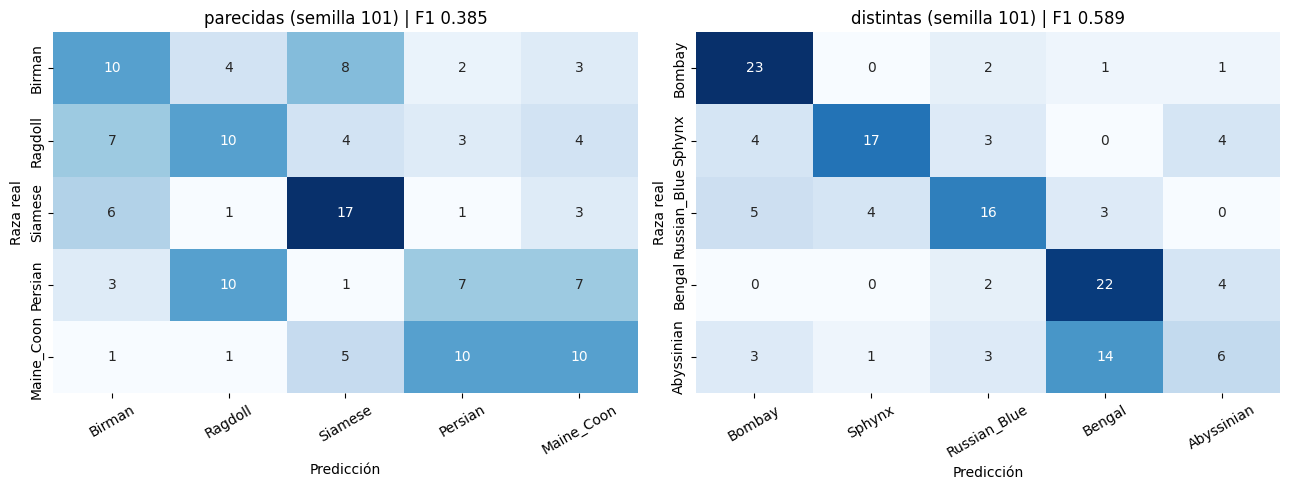

In [19]:
# ==========================================
# MÉTRICAS COMPLETAS EN PRUEBA + KPIs + MATRICES DE CONFUSIÓN (semilla 101)
# ==========================================
dft = pd.read_csv("resultados/cnn_final_por_semilla.csv")

def ms(x):
    return f"{x.mean():.3f} ± {x.std():.3f}"

resumen = pd.DataFrame({
    sub: {"Accuracy": ms(g["acc_test"]), "Precision (macro)": ms(g["precision_test"]),
          "Recall (macro)": ms(g["recall_test"]), "F1 macro": ms(g["f1_test"]),
          "Recall mínimo": ms(g["recall_min_test"])}
    for sub, g in dft.groupby("subconjunto")}).T
print("RESUMEN EN PRUEBA (media ± desv. de 5 semillas)")
print(resumen.to_string(), "\n")
resumen.to_csv("resultados/cnn_final_resumen.csv")

print("POR SEMILLA")
print(dft[["subconjunto", "semilla", "epoca_mejor", "acc_test", "precision_test", "recall_test",
           "f1_test", "recall_min_test"]].round(3).to_string(index=False), "\n")

print("KPIs (definidos en la EP1)")
for sub, g in dft.groupby("subconjunto"):
    f1m, rmin = g["f1_test"].mean(), g["recall_min_test"].mean()
    print(f"{sub:10s} KPI principal (F1 macro >= 0.4): {f1m:.3f} -> {'CUMPLE' if f1m >= 0.4 else 'NO CUMPLE'} | "
          f"KPI secundario (recall mínimo >= 0.2): {rmin:.3f} -> {'CUMPLE' if rmin >= 0.2 else 'NO CUMPLE'}")

print("\nREPORTE POR RAZA (modelo semilla 101)")
fig, ejes = plt.subplots(1, 2, figsize=(13, 5))
for ax, nombre in zip(ejes, SPLITS):
    sp = SPLITS[nombre]; y = sp["y_test"]; pred = PREDS[nombre]
    print(f"\n--- {nombre} ---")
    print(classification_report(y, pred, target_names=sp["clases"], digits=3, zero_division=0))
    cm = confusion_matrix(y, pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=sp["clases"], yticklabels=sp["clases"])
    ax.set_title(f"{nombre} (semilla 101) | F1 {f1_score(y, pred, average='macro'):.3f}")
    ax.set_xlabel("Predicción"); ax.set_ylabel("Raza real")
    ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_fig("06_matrices_confusion_cnn"); plt.show()

### Interpretación de la evaluación

En prueba, K1 obtiene F1 **0,518 ± 0,084** y accuracy **0,551 ± 0,079** en DISTINTAS, cumpliendo F1 ≥ 0,40. En PARECIDAS obtiene F1 **0,330 ± 0,064** y accuracy **0,349 ± 0,063**: supera el azar, pero no el KPI F1. El recall mínimo no cumple ≥ 0,20 en ningún grupo (0,139 ± 0,083 y 0,122 ± 0,102). Abyssinian es la clase más débil en DISTINTAS (recall 0,185 ± 0,074) y Birman en PARECIDAS (0,163 ± 0,158). La variación entre semillas limita la estabilidad, sobre todo en PARECIDAS.


### 6.2 Curvas de entrenamiento del modelo final (K1, semilla 101)

Se grafican, para cada subconjunto, la evolución del **accuracy** y de la **pérdida** en entrenamiento y validación a lo largo de las épocas del modelo de la semilla 101. Cada gráfico incluye la referencia del azar (accuracy 0,20 y pérdida ln 5 ≈ 1,609) y marca la **mejor época** elegida por `EarlyStopping`. Se leen igual que antes: si ambas curvas bajan (o suben) juntas, el modelo aprende de forma general; si el entrenamiento sigue mejorando mientras la validación se estanca o empeora, hay sobreajuste; y si ninguna se separa del azar, hay subajuste. Como el accuracy de entrenamiento se calcula con aumento de datos y dropout activos, es una medida pesimista.

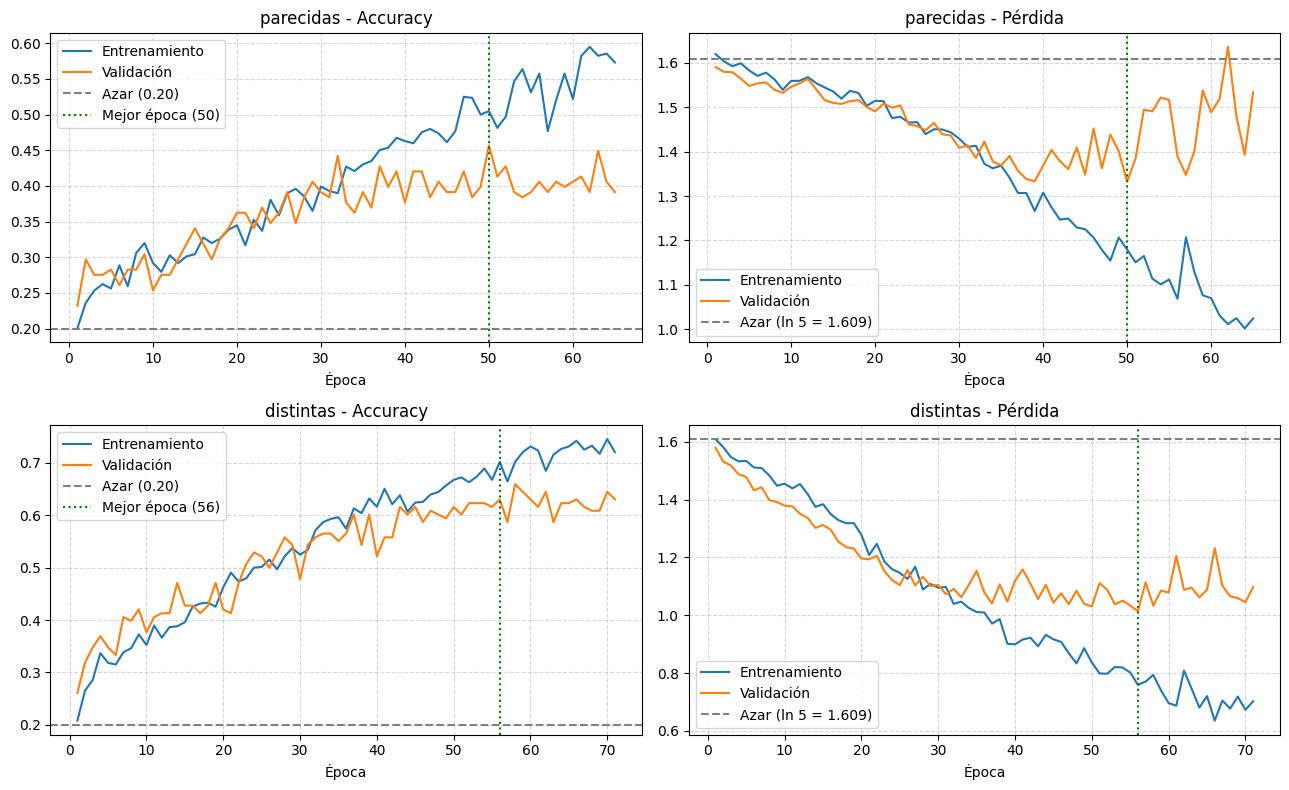

--- parecidas (K1, semilla 101) ---
Épocas entrenadas: 65 | mejor época según val_loss: 50
Pérdida de validación: mín 1.333 (época 50) | máx 1.636 (época 62)
Accuracy en la mejor época: entrenamiento 0.505 | validación 0.457 | brecha +0.048
Accuracy de validación: mín 0.232 | máx 0.457 (época 50)
Última época: accuracy de entrenamiento 0.573 | pérdida de entrenamiento 1.024

--- distintas (K1, semilla 101) ---
Épocas entrenadas: 71 | mejor época según val_loss: 56
Pérdida de validación: mín 1.014 (época 56) | máx 1.580 (época 1)
Accuracy en la mejor época: entrenamiento 0.702 | validación 0.630 | brecha +0.071
Accuracy de validación: mín 0.261 | máx 0.659 (época 58)
Última época: accuracy de entrenamiento 0.720 | pérdida de entrenamiento 0.702



In [20]:
# ==========================================
# CURVAS DEL MODELO FINAL (K1, semilla 101) EN LOS DOS SUBCONJUNTOS
# ==========================================
n = 5
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
for fila, nombre in enumerate(SPLITS):
    h = HIST[nombre]
    mejor = int(np.argmin(h["val_loss"]))
    ep = range(1, len(h["loss"]) + 1)

    ax = ejes[fila, 0]
    ax.plot(ep, h["accuracy"], label="Entrenamiento"); ax.plot(ep, h["val_accuracy"], label="Validación")
    ax.axhline(1 / n, color="gray", linestyle="--", label=f"Azar ({1/n:.2f})")
    ax.axvline(mejor + 1, color="green", linestyle=":", label=f"Mejor época ({mejor + 1})")
    ax.set_title(f"{nombre} - Accuracy"); ax.set_xlabel("Época"); ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)

    ax = ejes[fila, 1]
    ax.plot(ep, h["loss"], label="Entrenamiento"); ax.plot(ep, h["val_loss"], label="Validación")
    ax.axhline(np.log(n), color="gray", linestyle="--", label=f"Azar (ln {n} = {np.log(n):.3f})")
    ax.axvline(mejor + 1, color="green", linestyle=":")
    ax.set_title(f"{nombre} - Pérdida"); ax.set_xlabel("Época"); ax.legend(); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("07_curvas_cnn_final"); plt.show()

for nombre in SPLITS:
    h = HIST[nombre]
    mejor = int(np.argmin(h["val_loss"]))
    print(f"--- {nombre} (K1, semilla 101) ---")
    print(f"Épocas entrenadas: {len(h['loss'])} | mejor época según val_loss: {mejor + 1}")
    print(f"Pérdida de validación: mín {min(h['val_loss']):.3f} (época {mejor + 1}) | máx {max(h['val_loss']):.3f} (época {int(np.argmax(h['val_loss'])) + 1})")
    print(f"Accuracy en la mejor época: entrenamiento {h['accuracy'][mejor]:.3f} | validación {h['val_accuracy'][mejor]:.3f} | brecha {h['accuracy'][mejor] - h['val_accuracy'][mejor]:+.3f}")
    print(f"Accuracy de validación: mín {min(h['val_accuracy']):.3f} | máx {max(h['val_accuracy']):.3f} (época {int(np.argmax(h['val_accuracy'])) + 1})")
    print(f"Última época: accuracy de entrenamiento {h['accuracy'][-1]:.3f} | pérdida de entrenamiento {h['loss'][-1]:.3f}\n")

### Interpretación de las curvas del modelo final

**PARECIDAS (K1, semilla 101):** 65 épocas; mejor época 50, val_loss 1,333. Accuracy de entrenamiento/validación 0,505/0,457 (brecha 0,048). La pérdida de validación sube hasta 1,636 en época 62 mientras entrenamiento termina con accuracy 0,573 y pérdida 1,024: hay indicios de sobreajuste tardío.

**DISTINTAS:** 71 épocas; mejor época 56, val_loss 1,014. Accuracy 0,702/0,630 (brecha 0,071), con máximo de validación 0,659 en época 58. Hay aprendizaje útil y brecha moderada; siguen existiendo errores por raza. Estas curvas son de una semilla, por lo que las medias de cinco semillas son más representativas.


## 7. Comparación entre MLP y CNN

El MLP final de la EP1 se reentrena en este notebook con el mismo reparto de datos, las mismas cinco semillas (101 a 105) y las mismas métricas. Así se comparan resultados bajo una partición común. Los tiempos se informan como medidos en esta sesión y dependen del hardware y del entorno de ejecución.

**Configuración del MLP:** una capa oculta de 128 neuronas con ReLU, dropout 0,3, Adam con learning rate 1e-4, estandarización por canal, aumento de datos, batch 32, EarlyStopping sobre pérdida de validación con paciencia 20 y tope de 150 épocas; entrada 64x64x3 aplanada.

| Aspecto | MLP | CNN (K1) |
|---|---|---|
| Entrada | Imagen aplanada (12.288 valores) | Tensor 64x64x3 |
| Paciencia de EarlyStopping | 20 | 15 |
| Tope de épocas | 150 | 100 |
| Ajustes previos | unos 87 (EP1) | 15 (sección 5) |
| Datos, partición, aumento, métricas y semillas | Iguales | Iguales |

La mayor cantidad de ajuste del MLP favorece a ese modelo; se considera al interpretar la comparación.


In [21]:
# ==========================================
# MLP DE LA EP1 REENTRENADO EN ESTE NOTEBOOK (mismo reparto, semillas, métricas y máquina)
# ==========================================
CFG_MLP = dict(neuronas=128, dropout=0.3, lr=1e-4)      # configuración final de la EP1
PACIENCIA_MLP, EPOCAS_MAX_MLP = 20, 150                  # valores usados en la EP1 para el MLP

def crear_mlp(n_clases, neuronas=128, dropout=0.3, lr=1e-4, X_adapt=None, resolucion=RES_BASE):
    capas = [layers.Input(shape=(resolucion, resolucion, 3)),
             layers.RandomFlip("horizontal"), layers.RandomRotation(0.055), layers.RandomTranslation(0.1, 0.1),
             layers.Rescaling(1 / 255)]
    norm = layers.Normalization(axis=-1)
    norm.adapt(X_adapt.astype("float32") / 255.0)          # media y desviación SOLO con entrenamiento
    capas += [norm, layers.Flatten(), layers.Dense(neuronas), layers.Activation("relu"),
              layers.Dropout(dropout), layers.Dense(n_clases, activation="softmax")]
    m = models.Sequential(capas)
    m.compile(optimizer=optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar_mlp(sp, seed):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    m = crear_mlp(len(sp["clases"]), X_adapt=sp["X_train"], **CFG_MLP)
    es = EarlyStopping(monitor="val_loss", patience=PACIENCIA_MLP, restore_best_weights=True)
    t0 = time.time()
    h = m.fit(sp["X_train"], sp["y_train"], validation_data=(sp["X_val"], sp["y_val"]),
              epochs=EPOCAS_MAX_MLP, batch_size=32, callbacks=[es], verbose=0)
    return m, h, time.time() - t0

filas_mlp = []
MLPS, PREDS_MLP, HIST_MLP = {}, {}, {}
PROBS_MLP = {}      # probabilidades en prueba de las 5 semillas
for nombre, sp in SPLITS.items():
    for s in SEEDS_FINAL:
        m, h, seg = entrenar_mlp(sp, s)
        met_te, pred_te = metricas(m, sp["X_test"], sp["y_test"])
        met_va, _ = metricas(m, sp["X_val"], sp["y_val"])
        PROBS_MLP[(nombre, s)] = m.predict(sp["X_test"], verbose=0)
        mejor_ep = int(np.argmin(h.history["val_loss"]))
        filas_mlp.append(dict(subconjunto=nombre, semilla=s, parametros=m.count_params(),
                              epoca_mejor=mejor_ep + 1, epocas_totales=len(h.history["loss"]), segundos=seg,
                              acc_train=h.history["accuracy"][mejor_ep],
                              acc_val=met_va["acc"], f1_val=met_va["f1"],
                              acc_test=met_te["acc"], precision_test=met_te["precision"],
                              recall_test=met_te["recall"], f1_test=met_te["f1"],
                              recall_min_test=met_te["recall_min"]))
        pd.DataFrame(filas_mlp).to_csv("resultados/mlp_final_por_semilla.csv", index=False)   # guarda el avance
        if s == SEEDS_FINAL[0]:                          # modelo "detallado": semilla 101
            MLPS[nombre], PREDS_MLP[nombre], HIST_MLP[nombre] = m, pred_te, h.history
            m.save(f"models/mlp_{nombre}_s{s}.keras")
        print(f"{nombre} | semilla {s} | F1 test {met_te['f1']:.3f} | acc test {met_te['acc']:.3f} | "
              f"{len(h.history['loss'])} épocas | {seg:.0f} s")
    print()

res_mlp = pd.DataFrame(filas_mlp).groupby("subconjunto").agg(
    f1_test=("f1_test", "mean"), f1_test_std=("f1_test", "std"),
    acc_test=("acc_test", "mean"), acc_test_std=("acc_test", "std"),
    f1_val=("f1_val", "mean"), segundos=("segundos", "mean"))
print(res_mlp.round(3).to_string())

parecidas | semilla 101 | F1 test 0.320 | acc test 0.333 | 43 épocas | 11 s
parecidas | semilla 102 | F1 test 0.430 | acc test 0.435 | 36 épocas | 10 s
parecidas | semilla 103 | F1 test 0.366 | acc test 0.370 | 31 épocas | 9 s
parecidas | semilla 104 | F1 test 0.347 | acc test 0.341 | 46 épocas | 12 s
parecidas | semilla 105 | F1 test 0.351 | acc test 0.348 | 60 épocas | 15 s

distintas | semilla 101 | F1 test 0.527 | acc test 0.529 | 46 épocas | 12 s
distintas | semilla 102 | F1 test 0.521 | acc test 0.522 | 61 épocas | 16 s
distintas | semilla 103 | F1 test 0.483 | acc test 0.486 | 55 épocas | 14 s
distintas | semilla 104 | F1 test 0.467 | acc test 0.471 | 58 épocas | 15 s
distintas | semilla 105 | F1 test 0.438 | acc test 0.442 | 25 épocas | 7 s

             f1_test  f1_test_std  acc_test  acc_test_std  f1_val  segundos
subconjunto                                                                
distintas      0.487        0.037     0.490         0.036   0.505    12.885
parecidas   

**Valores del MLP reentrenado (semilla 101).** Para tener en este notebook las cifras del MLP que se usan en la comparación con la CNN base de la sección 4, se imprimen la mejor época y la pérdida y accuracy de validación del MLP en esa semilla.

In [22]:
for nombre in SPLITS:
    h = HIST_MLP[nombre]; mejor = int(np.argmin(h["val_loss"]))
    print(f"MLP {nombre} (semilla 101): mejor época {mejor + 1} | val_loss {h['val_loss'][mejor]:.3f} | "
          f"val_acc {h['val_accuracy'][mejor]:.3f} | val_loss mín {min(h['val_loss']):.3f} | máx {max(h['val_loss']):.3f}")

MLP parecidas (semilla 101): mejor época 23 | val_loss 1.559 | val_acc 0.420 | val_loss mín 1.559 | máx 1.953
MLP distintas (semilla 101): mejor época 26 | val_loss 1.405 | val_acc 0.486 | val_loss mín 1.405 | máx 1.735


**Verificación del MLP reentrenado (semilla 101).** En PARECIDAS, la mejor época fue 23, val_loss 1,559 y val_acc 0,420, iguales a las cifras citadas de la EP1. En DISTINTAS fue época 26, val_loss 1,405 y val_acc 0,486. Esto respalda la reproducción del MLP en esta sesión, no identidad garantizada entre entornos.


### 7.1 Tablas y gráficos de comparación

El MLP reentrenado reproduce los promedios de EP1. En DISTINTAS, K1 supera al MLP en F1 (0,518 ± 0,084 vs 0,487 ± 0,037); en PARECIDAS queda por debajo (0,330 ± 0,064 vs 0,363 ± 0,041). K1 usa 101.836 parámetros frente a 1.573.644, pero tardó 25 vs 13 s en DISTINTAS y 20 vs 11 s en PARECIDAS. Menos parámetros no implican más rapidez. Las brechas medias train-test de accuracy de K1 son 0,096 y 0,101, respectivamente; deben interpretarse junto con otras métricas.


TABLA 1: DESEMPEÑO EN PRUEBA (media ± desv. de 5 semillas), PARÁMETROS Y TIEMPO
subconjunto    modelo parámetros      F1 macro      Accuracy     Precision Recall mínimo Tiempo (s) Época mejor Seg/época F1 mediana
  distintas  CNN (K1)    101,836 0.518 ± 0.084 0.551 ± 0.079 0.560 ± 0.064 0.139 ± 0.083         25          48      0.40      0.543
  distintas MLP (EP1)  1,573,644 0.487 ± 0.037 0.490 ± 0.036 0.488 ± 0.039 0.360 ± 0.059         13          29      0.27      0.483
  parecidas  CNN (K1)    101,836 0.330 ± 0.064 0.349 ± 0.063 0.341 ± 0.071 0.122 ± 0.102         20          35      0.40      0.322
  parecidas MLP (EP1)  1,573,644 0.363 ± 0.041 0.365 ± 0.041 0.376 ± 0.041 0.254 ± 0.026         11          23      0.27      0.351 

TABLA 2: GENERALIZACIÓN (accuracy de entrenamiento en la mejor época, con aumento y dropout activos)
                       acc_train  acc_val  acc_test  gap_train_test  f1_val  f1_test  gap_f1_val_test
subconjunto modelo                                

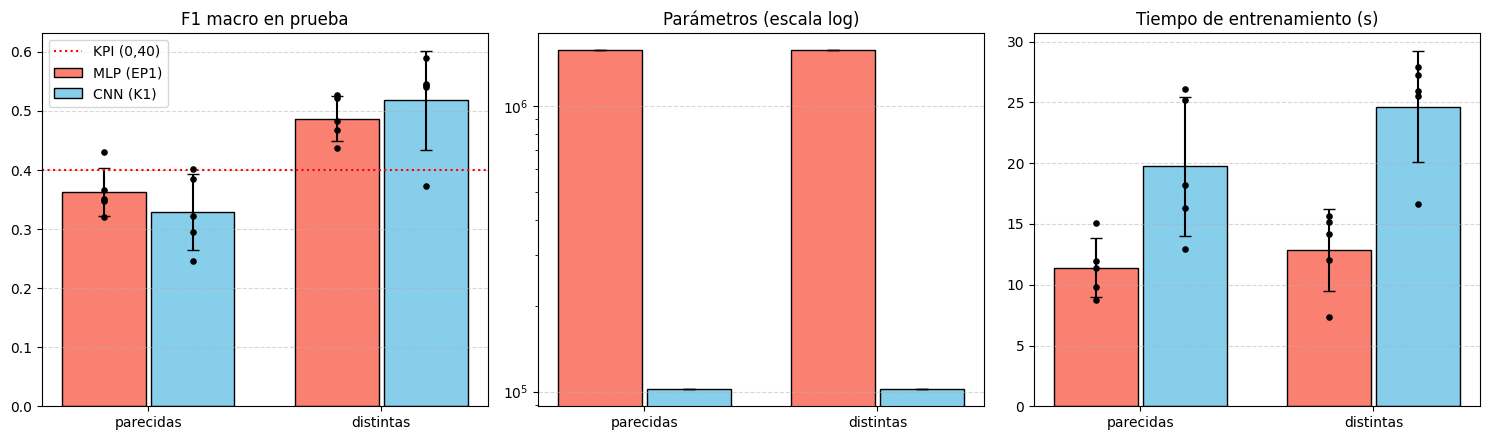

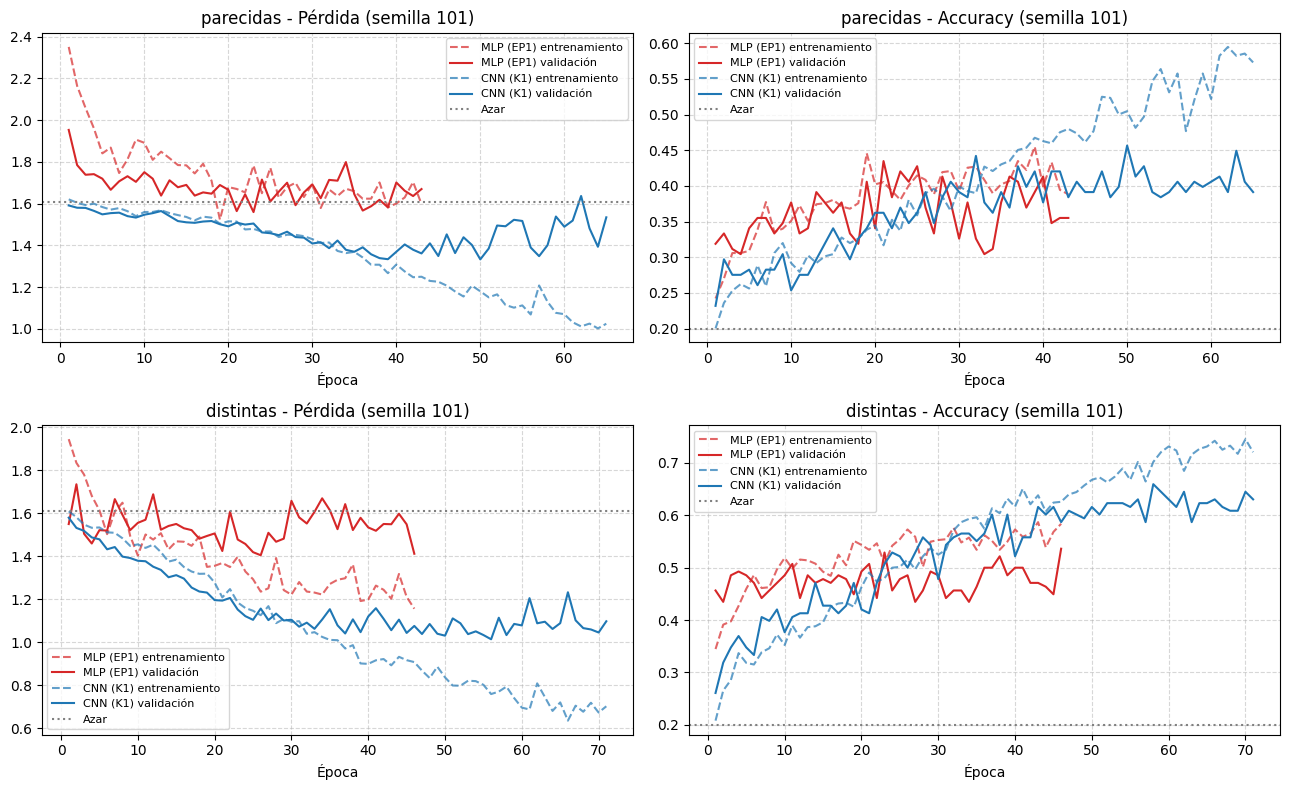

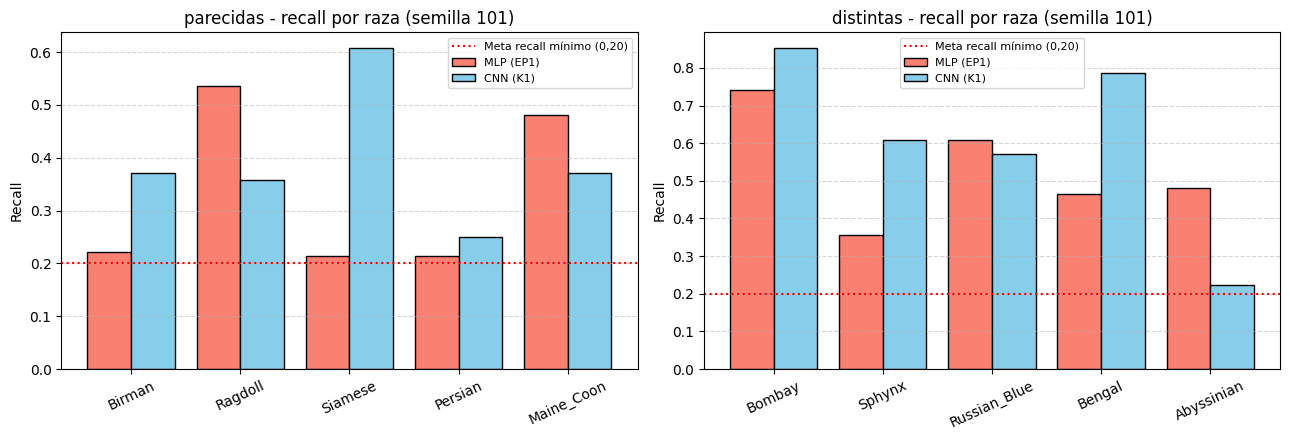

In [23]:
# ==========================================
# COMPARACIÓN MLP vs CNN (K1): TABLAS Y GRÁFICOS
# ==========================================
def ms(x):
    return f"{x.mean():.3f} ± {x.std():.3f}"

cnn = pd.read_csv("resultados/cnn_final_por_semilla.csv"); cnn["modelo"] = "CNN (K1)"
mlp = pd.read_csv("resultados/mlp_final_por_semilla.csv");  mlp["modelo"] = "MLP (EP1)"
d = pd.concat([mlp, cnn], ignore_index=True)
d["gap_train_test"] = d["acc_train"] - d["acc_test"]
d["gap_f1_val_test"] = d["f1_val"] - d["f1_test"]

# --- Tabla 1: desempeño, parámetros y tiempo ---
filas = []
for (sub, mod), g in d.groupby(["subconjunto", "modelo"]):
    filas.append({"subconjunto": sub, "modelo": mod, "parámetros": f"{int(g['parametros'].iloc[0]):,}",
                  "F1 macro": ms(g["f1_test"]), "Accuracy": ms(g["acc_test"]), "Precision": ms(g["precision_test"]),
                  "Recall mínimo": ms(g["recall_min_test"]), "Tiempo (s)": f"{g['segundos'].mean():.0f}",
                  "Época mejor": f"{g['epoca_mejor'].mean():.0f}",
                  "Seg/época": f"{(g['segundos'] / g['epocas_totales']).mean():.2f}",
                  "F1 mediana": f"{g['f1_test'].median():.3f}"})
tabla = pd.DataFrame(filas)
print("TABLA 1: DESEMPEÑO EN PRUEBA (media ± desv. de 5 semillas), PARÁMETROS Y TIEMPO")
print(tabla.to_string(index=False), "\n")
tabla.to_csv("resultados/comparacion_mlp_cnn.csv", index=False)

# --- Tabla 2: generalización ---
gen = d.groupby(["subconjunto", "modelo"]).agg(
    acc_train=("acc_train", "mean"), acc_val=("acc_val", "mean"), acc_test=("acc_test", "mean"),
    gap_train_test=("gap_train_test", "mean"), f1_val=("f1_val", "mean"), f1_test=("f1_test", "mean"),
    gap_f1_val_test=("gap_f1_val_test", "mean"))
print("TABLA 2: GENERALIZACIÓN (accuracy de entrenamiento en la mejor época, con aumento y dropout activos)")
print(gen.round(3).to_string(), "\n")

# --- Diferencia CNN - MLP por semilla, con el criterio de la sección 1.6 ---
print("DIFERENCIA CNN - MLP EN F1 MACRO DE PRUEBA (misma semilla)")
for sub in SPLITS:
    a = cnn[cnn["subconjunto"] == sub].set_index("semilla")["f1_test"]
    b = mlp[mlp["subconjunto"] == sub].set_index("semilla")["f1_test"]
    dif = a - b
    media, suma_std = a.mean() - b.mean(), a.std() + b.std()
    veredicto = "diferencia relevante" if abs(media) > suma_std else "empate técnico"
    print(f"{sub:10s} diferencia media {media:+.3f} | suma de desviaciones {suma_std:.3f} -> {veredicto} | "
          f"CNN mejor en {(dif > 0).sum()} de {len(dif)} semillas")
    print(f"{'':10s} por semilla: {dif.round(3).to_dict()}")

# --- Gráfico 1: F1, parámetros y tiempo ---
colores = {"MLP (EP1)": "salmon", "CNN (K1)": "skyblue"}
fig, ejes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (col, titulo, log) in zip(ejes, [("f1_test", "F1 macro en prueba", False),
                                         ("parametros", "Parámetros (escala log)", True),
                                         ("segundos", "Tiempo de entrenamiento (s)", False)]):
    for j, sub in enumerate(SPLITS):
        for k, mod in enumerate(["MLP (EP1)", "CNN (K1)"]):
            g = d[(d["subconjunto"] == sub) & (d["modelo"] == mod)][col]
            x = j + (k - 0.5) * 0.38
            ax.bar(x, g.mean(), 0.36, yerr=(0 if col == "parametros" else g.std()), capsize=4,
                   color=colores[mod], edgecolor="black", label=mod if j == 0 else None)
            if col != "parametros":
                ax.scatter([x] * len(g), g, color="black", s=14, zorder=3)
    ax.set_xticks(range(len(SPLITS))); ax.set_xticklabels(list(SPLITS)); ax.set_title(titulo)
    if log:
        ax.set_yscale("log")
    ax.grid(True, axis="y", linestyle="--", alpha=0.5)
ejes[0].axhline(0.4, color="red", linestyle=":", label="KPI (0,40)")
ejes[0].legend()
plt.tight_layout(); guardar_fig("08_comparacion_f1_parametros_tiempo"); plt.show()

# --- Gráfico 2: curvas de entrenamiento de ambos modelos (semilla 101) ---
fig, ejes = plt.subplots(2, 2, figsize=(13, 8))
for fila, sub in enumerate(SPLITS):
    for nombre_mod, H, col in [("MLP (EP1)", HIST_MLP[sub], "tab:red"), ("CNN (K1)", HIST[sub], "tab:blue")]:
        ep = range(1, len(H["loss"]) + 1)
        ejes[fila, 0].plot(ep, H["loss"], color=col, linestyle="--", alpha=0.7, label=f"{nombre_mod} entrenamiento")
        ejes[fila, 0].plot(ep, H["val_loss"], color=col, label=f"{nombre_mod} validación")
        ejes[fila, 1].plot(ep, H["accuracy"], color=col, linestyle="--", alpha=0.7, label=f"{nombre_mod} entrenamiento")
        ejes[fila, 1].plot(ep, H["val_accuracy"], color=col, label=f"{nombre_mod} validación")
    ejes[fila, 0].axhline(np.log(5), color="gray", linestyle=":", label="Azar")
    ejes[fila, 1].axhline(0.2, color="gray", linestyle=":", label="Azar")
    ejes[fila, 0].set_title(f"{sub} - Pérdida (semilla 101)"); ejes[fila, 1].set_title(f"{sub} - Accuracy (semilla 101)")
    for ax in ejes[fila]:
        ax.set_xlabel("Época"); ax.grid(True, linestyle="--", alpha=0.5); ax.legend(fontsize=8)
plt.tight_layout(); guardar_fig("09_curvas_mlp_vs_cnn"); plt.show()

# --- Gráfico 3: recall por raza (modelos de la semilla 101) ---
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, sub in zip(ejes, SPLITS):
    y = SPLITS[sub]["y_test"]; clases = SPLITS[sub]["clases"]
    soporte = np.bincount(y, minlength=len(clases))
    r_mlp = confusion_matrix(y, PREDS_MLP[sub]).diagonal() / soporte
    r_cnn = confusion_matrix(y, PREDS[sub]).diagonal() / soporte
    x = np.arange(len(clases))
    ax.bar(x - 0.2, r_mlp, 0.4, color=colores["MLP (EP1)"], edgecolor="black", label="MLP (EP1)")
    ax.bar(x + 0.2, r_cnn, 0.4, color=colores["CNN (K1)"], edgecolor="black", label="CNN (K1)")
    ax.axhline(0.2, color="red", linestyle=":", label="Meta recall mínimo (0,20)")
    ax.set_xticks(x); ax.set_xticklabels(clases, rotation=25); ax.set_ylabel("Recall"); ax.set_title(f"{sub} - recall por raza (semilla 101)")
    ax.legend(fontsize=8); ax.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("10_recall_por_raza_mlp_cnn"); plt.show()

### Interpretación de la comparación MLP vs CNN

En DISTINTAS, K1 mejora los promedios de F1 y accuracy y gana en 4/5 semillas; en PARECIDAS, el MLP tiene mayor F1 y accuracy, y K1 gana en 2/5. La etiqueta de empate técnico es solo una regla heurística basada en desviaciones, no demuestra equivalencia. McNemar y los intervalos bootstrap de la semilla 101 tampoco muestran diferencias concluyentes. El recall mínimo favorece al MLP (0,360 vs 0,139 en DISTINTAS; 0,254 vs 0,122 en PARECIDAS). K1 tiene 15,5 veces menos parámetros, pero tardó más en esta sesión. La hipótesis de ventaja CNN se cumple solo en DISTINTAS para promedios F1/accuracy, no en PARECIDAS ni en recall mínimo.


### 7.1b Recall por raza, matrices agregadas y reporte del MLP

Hasta aquí el MLP tenía métricas globales pero no el detalle por raza, y el análisis de errores de la CNN se basaba en una sola semilla (101, más favorable que el promedio). Esta celda usa las probabilidades guardadas de las **5 semillas** para: (1) el **recall por raza** (media ± desviación) de ambos modelos; (2) el **reporte por raza del MLP**; (3) las **matrices de confusión agregadas** de las 5 semillas (cada fila suma 1: fracción de cada raza real que se predijo como cada raza), para ambos modelos.

RECALL POR RAZA EN PRUEBA (media ± desv. de 5 semillas)

--- parecidas ---
                 CNN (K1)      MLP (EP1)
Birman      0.163 ± 0.158  0.333 ± 0.091
Ragdoll     0.271 ± 0.109  0.421 ± 0.117
Siamese     0.507 ± 0.099  0.343 ± 0.090
Persian     0.343 ± 0.090  0.300 ± 0.054
Maine_Coon  0.459 ± 0.167  0.430 ± 0.156

--- distintas ---
                   CNN (K1)      MLP (EP1)
Bombay        0.807 ± 0.109  0.696 ± 0.041
Sphynx        0.364 ± 0.233  0.386 ± 0.069
Russian_Blue  0.571 ± 0.091  0.514 ± 0.070
Bengal        0.821 ± 0.067  0.421 ± 0.059
Abyssinian    0.185 ± 0.074  0.437 ± 0.066

REPORTE POR RAZA DEL MLP (semilla 101)

--- parecidas ---
              precision    recall  f1-score   support

      Birman      0.273     0.222     0.245        27
     Ragdoll      0.306     0.536     0.390        28
     Siamese      0.400     0.214     0.279        28
     Persian      0.353     0.214     0.267        28
  Maine_Coon      0.371     0.481     0.419        27

    accuracy     

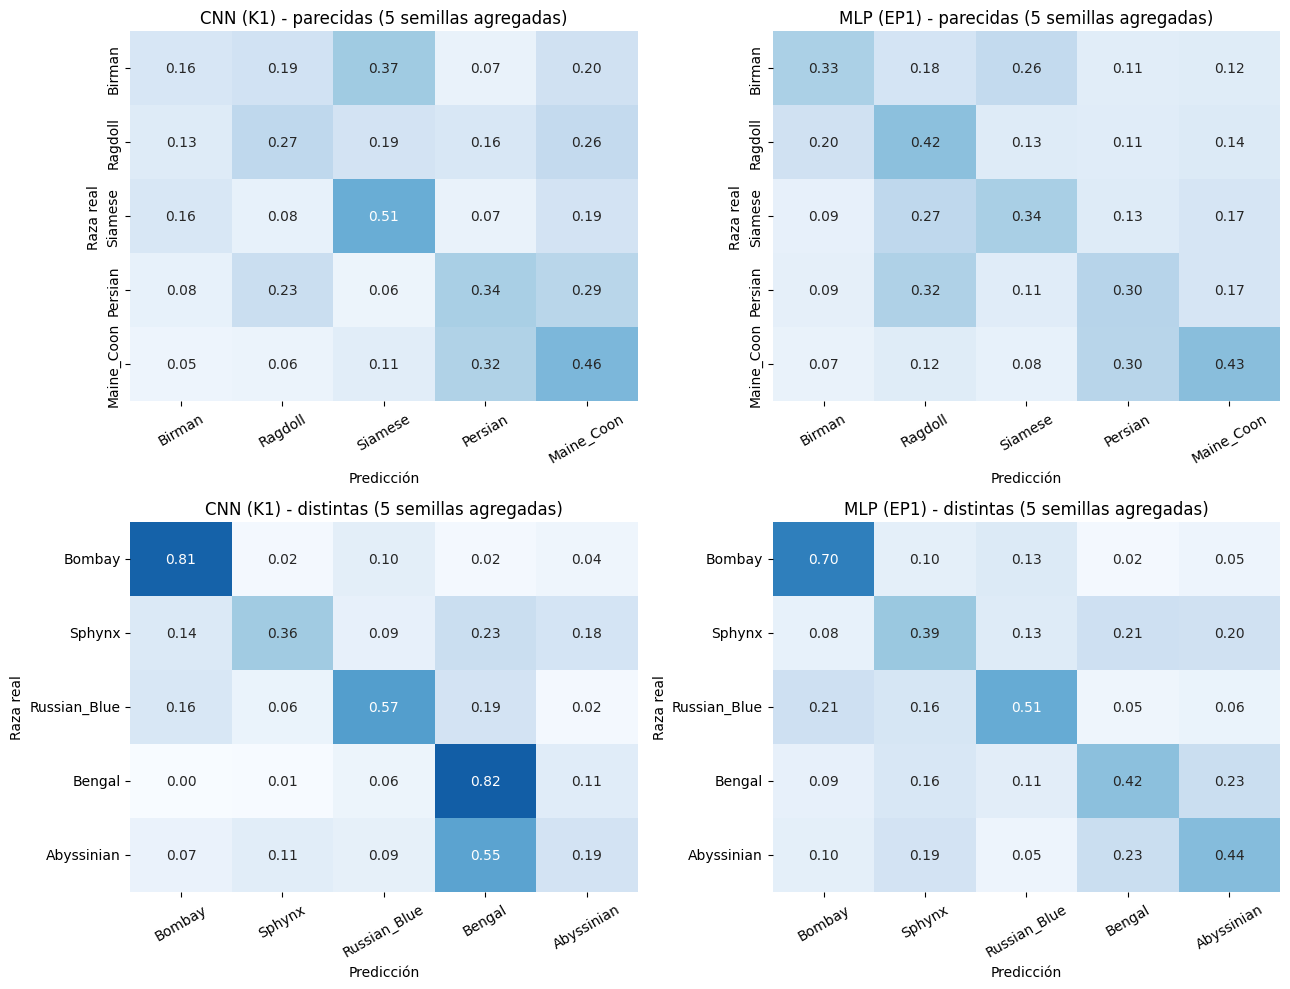

parecidas: par más confundido (5 semillas, CNN): Birman -> Siamese en el 37% de los casos
distintas: par más confundido (5 semillas, CNN): Abyssinian -> Bengal en el 55% de los casos


In [24]:
# ==========================================
# MLP vs CNN: RECALL POR RAZA (5 semillas), REPORTE DEL MLP Y MATRICES AGREGADAS
# ==========================================
def recall_semillas(nombre, store):
    y = SPLITS[nombre]["y_test"]; n = len(SPLITS[nombre]["clases"])
    return np.array([recall_score(y, store[(nombre, s)].argmax(axis=1), average=None,
                                  labels=list(range(n)), zero_division=0) for s in SEEDS_FINAL])

print("RECALL POR RAZA EN PRUEBA (media ± desv. de 5 semillas)")
for nombre in SPLITS:
    clases = SPLITS[nombre]["clases"]
    rc, rm = recall_semillas(nombre, PROBS_CNN), recall_semillas(nombre, PROBS_MLP)
    tabla_r = pd.DataFrame({"CNN (K1)": [f"{a:.3f} ± {b:.3f}" for a, b in zip(rc.mean(0), rc.std(0, ddof=1))],
                            "MLP (EP1)": [f"{a:.3f} ± {b:.3f}" for a, b in zip(rm.mean(0), rm.std(0, ddof=1))]}, index=clases)
    print(f"\n--- {nombre} ---"); print(tabla_r.to_string())

print("\nREPORTE POR RAZA DEL MLP (semilla 101)")
for nombre in SPLITS:
    print(f"\n--- {nombre} ---")
    print(classification_report(SPLITS[nombre]["y_test"], PREDS_MLP[nombre],
                                target_names=SPLITS[nombre]["clases"], digits=3, zero_division=0))

def cm_agregada(nombre, store):
    y = SPLITS[nombre]["y_test"]; n = len(SPLITS[nombre]["clases"])
    cm = sum(confusion_matrix(y, store[(nombre, s)].argmax(axis=1), labels=list(range(n))) for s in SEEDS_FINAL)
    return cm / cm.sum(axis=1, keepdims=True)

fig, ejes = plt.subplots(2, 2, figsize=(13, 10))
for fila, nombre in enumerate(SPLITS):
    clases = SPLITS[nombre]["clases"]
    for col, (mod, store) in enumerate([("CNN (K1)", PROBS_CNN), ("MLP (EP1)", PROBS_MLP)]):
        sns.heatmap(cm_agregada(nombre, store), annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, cbar=False,
                    ax=ejes[fila, col], xticklabels=clases, yticklabels=clases)
        ejes[fila, col].set_title(f"{mod} - {nombre} (5 semillas agregadas)")
        ejes[fila, col].set_xlabel("Predicción"); ejes[fila, col].set_ylabel("Raza real")
        ejes[fila, col].tick_params(axis="x", rotation=30)
plt.tight_layout(); guardar_fig("10b_matrices_agregadas_mlp_cnn"); plt.show()

for nombre in SPLITS:
    cm = cm_agregada(nombre, PROBS_CNN); np.fill_diagonal(cm, 0)
    a, b = np.unravel_index(cm.argmax(), cm.shape); c = SPLITS[nombre]["clases"]
    print(f"{nombre}: par más confundido (5 semillas, CNN): {c[a]} -> {c[b]} en el {cm[a, b]:.0%} de los casos")

**Recall por raza y confusiones.** En PARECIDAS, K1 tiene mayor recall en Siamese (0,507 ± 0,099) y menor en Birman (0,163 ± 0,158); el MLP destaca en Ragdoll (0,421 ± 0,117) y su menor es Persian (0,300 ± 0,054). En DISTINTAS, K1 destaca en Bengal (0,821 ± 0,067) y Bombay (0,807 ± 0,109), pero falla en Abyssinian (0,185 ± 0,074). El MLP es más parejo. La confusión agregada principal de K1 es Birman→Siamese (37%) y Abyssinian→Bengal (55%). En la semilla 101 sobrepredice Siamese/Bengal y subpredice Persian/Abyssinian; son tendencias muestrales, no causas demostradas.


### 7.1c KPI complementario: cobertura y precisión con confianza alta

Como la herramienta es de apoyo con confirmación del personal (sección 1.1), interesa qué fracción de las fotos podría confirmarse con poco riesgo. Se mide la **cobertura** (fracción de predicciones con confianza ≥ 0,8) y la **precisión de esas predicciones**, con las 5 semillas y para ambos modelos. Este KPI se definió **después de ver los resultados**, por lo que no se usa para declarar cumplimiento: es un complemento descriptivo a los KPIs de la sección 1.6.

In [25]:
# ==========================================
# KPI COMPLEMENTARIO: COBERTURA Y PRECISIÓN CON CONFIANZA >= 0.8 (5 semillas)
# ==========================================
UMBRAL = 0.8
filas = []
for nombre in SPLITS:
    y = SPLITS[nombre]["y_test"]
    for mod, store in [("CNN (K1)", PROBS_CNN), ("MLP (EP1)", PROBS_MLP)]:
        cob, prec = [], []
        for s in SEEDS_FINAL:
            p = store[(nombre, s)]; conf = p.max(axis=1); ok = p.argmax(axis=1) == y
            sel = conf >= UMBRAL
            cob.append(sel.mean()); prec.append(ok[sel].mean() if sel.any() else np.nan)
        filas.append(dict(subconjunto=nombre, modelo=mod,
                          cobertura=f"{np.mean(cob):.3f} ± {np.std(cob, ddof=1):.3f}",
                          precision_alta_confianza=f"{np.nanmean(prec):.3f} ± {np.nanstd(prec, ddof=1):.3f}",
                          semillas_sin_casos=int(np.isnan(prec).sum())))
kpi_neg = pd.DataFrame(filas)
print(kpi_neg.to_string(index=False))
kpi_neg.to_csv("resultados/kpi_complementario_confianza.csv", index=False)

subconjunto    modelo     cobertura precision_alta_confianza  semillas_sin_casos
  parecidas  CNN (K1) 0.052 ± 0.066            0.579 ± 0.084                   2
  parecidas MLP (EP1) 0.159 ± 0.037            0.429 ± 0.117                   0
  distintas  CNN (K1) 0.328 ± 0.121            0.831 ± 0.048                   0
  distintas MLP (EP1) 0.325 ± 0.052            0.677 ± 0.060                   0


**Cobertura con confianza ≥ 0,8.** En PARECIDAS, K1 cubre solo **5,2% ± 6,6%** y acierta 57,9% ± 8,4% de esas predicciones; en dos semillas no hubo casos. No sirve como filtro suficiente en ese subconjunto. En DISTINTAS cubre **32,8% ± 12,1%** con precisión **83,1% ± 4,8%**, frente al MLP (32,5% ± 5,2% y 67,7% ± 6,0%). Puede ayudar como filtro solo en DISTINTAS, con confirmación humana, y deja sin cubrir la mayoría de fotos. Es descriptivo y posterior a los resultados.


### 7.2 Respaldo estadístico y calibración

La sección 7.1 concluyó que hay empate técnico con el criterio de las desviaciones entre semillas. Aquí se agregan dos comprobaciones que no entrenan ningún modelo nuevo y usan los modelos de la semilla 101.

**Incertidumbre por el tamaño del set de prueba.** Con solo 138 imágenes, cada una vale unos 0,7 puntos de accuracy, así que incluso con el modelo fijo hay un margen de error. Se calcula:
- Un **intervalo de confianza del 95% para el accuracy** (método de Wilson) de cada modelo, con el accuracy promedio de las 5 semillas y n = 138. Solo refleja el tamaño del set de prueba, no la variación entre semillas.
- Una **prueba de McNemar exacta** sobre las mismas 138 imágenes (semilla 101): cuenta las imágenes que la CNN acierta y el MLP falla (b) y al revés (c), y prueba si la diferencia es mayor que la esperable por azar. Es una comparación pareada: ambos modelos ven las mismas fotos.
- Un **intervalo bootstrap del 95%** para la diferencia de F1 macro (CNN − MLP): se remuestrean las 138 imágenes 2.000 veces con la semilla 2604 y se recalcula la diferencia. Si el intervalo incluye el cero, no se puede afirmar una diferencia.

**Calibración.** Un modelo está bien calibrado si, cuando dice tener 70% de confianza, acierta cerca del 70% de las veces. Se mide con:
- **ECE (error de calibración esperado):** diferencia promedio, ponderada, entre la confianza y el accuracy en 5 tramos de confianza entre 0,2 y 1,0 (con 5 clases, la confianza mínima posible es 0,2). Menor es mejor; con 138 imágenes, algunos tramos tienen pocas fotos y el valor es ruidoso.
- **Brier:** error cuadrático promedio de las probabilidades (el azar con 5 clases da 0,80).
- **Log-loss:** la pérdida de entropía cruzada en prueba (el azar da ln 5 = 1,609).
- **Diagrama de confiabilidad:** accuracy real contra confianza, por tramo; la diagonal es la calibración perfecta.

Ambas comprobaciones se hacen sobre una sola semilla (101) y sobre el set de prueba ya usado.

INTERVALO DE CONFIANZA DEL 95% PARA EL ACCURACY (Wilson, n = 138, accuracy promedio de 5 semillas)
parecidas  CNN (K1)   accuracy 0.349 -> [0.275, 0.432] (ancho 0.157)
parecidas  MLP (EP1)  accuracy 0.365 -> [0.290, 0.448] (ancho 0.159)
distintas  CNN (K1)   accuracy 0.551 -> [0.467, 0.631] (ancho 0.164)
distintas  MLP (EP1)  accuracy 0.490 -> [0.408, 0.572] (ancho 0.165)

COMPARACIÓN PAREADA CNN vs MLP SOBRE LAS MISMAS IMÁGENES (semilla 101)
parecidas  CNN acierta y MLP falla: 30 | MLP acierta y CNN falla: 22 | McNemar exacto p = 0.332
           diferencia de F1 macro (CNN - MLP, semilla 101): +0.065 | bootstrap 95%: [-0.041, +0.168] -> incluye el cero
distintas  CNN acierta y MLP falla: 32 | MLP acierta y CNN falla: 21 | McNemar exacto p = 0.169
           diferencia de F1 macro (CNN - MLP, semilla 101): +0.063 | bootstrap 95%: [-0.043, +0.167] -> incluye el cero

CALIBRACIÓN EN PRUEBA (semilla 101): azar -> Brier 0.800, log-loss 1.609
parecidas  MLP (EP1)  confianza 0.605 | accurac

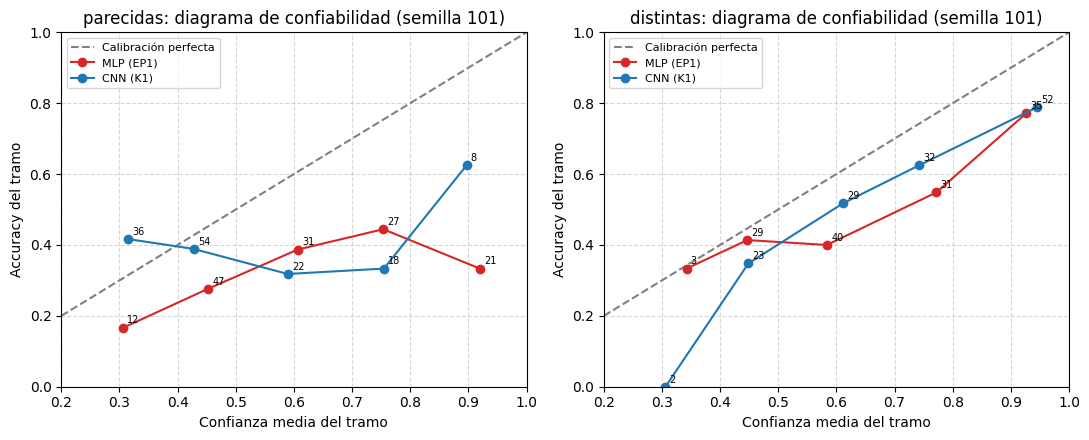

In [26]:
# ==========================================
# RESPALDO ESTADÍSTICO Y CALIBRACIÓN: CNN (K1) vs MLP, semilla 101, set de prueba
# ==========================================
from scipy.stats import binomtest

def wilson(p, n, z=1.96):
    centro = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    mitad = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centro - mitad, centro + mitad

cnn_f = pd.read_csv("resultados/cnn_final_por_semilla.csv")
mlp_f = pd.read_csv("resultados/mlp_final_por_semilla.csv")
n_test = len(SPLITS["parecidas"]["y_test"])

print(f"INTERVALO DE CONFIANZA DEL 95% PARA EL ACCURACY (Wilson, n = {n_test}, accuracy promedio de 5 semillas)")
for sub in SPLITS:
    for nombre_mod, df_mod in [("CNN (K1)", cnn_f), ("MLP (EP1)", mlp_f)]:
        p = df_mod[df_mod["subconjunto"] == sub]["acc_test"].mean()
        lo, hi = wilson(p, n_test)
        print(f"{sub:10s} {nombre_mod:10s} accuracy {p:.3f} -> [{lo:.3f}, {hi:.3f}] (ancho {hi - lo:.3f})")

print("\nCOMPARACIÓN PAREADA CNN vs MLP SOBRE LAS MISMAS IMÁGENES (semilla 101)")
rng_bs = np.random.default_rng(SEED_SPLIT)
for sub in SPLITS:
    y = SPLITS[sub]["y_test"]; pc, pm = PREDS[sub], PREDS_MLP[sub]
    cc, mm = pc == y, pm == y
    b, c = int((cc & ~mm).sum()), int((~cc & mm).sum())
    p_mcn = binomtest(min(b, c), b + c, 0.5).pvalue if (b + c) > 0 else 1.0
    difs = []
    for _ in range(2000):
        idx = rng_bs.integers(0, len(y), len(y))
        difs.append(f1_score(y[idx], pc[idx], average="macro") - f1_score(y[idx], pm[idx], average="macro"))
    lo, hi = np.percentile(difs, [2.5, 97.5])
    dif_obs = f1_score(y, pc, average="macro") - f1_score(y, pm, average="macro")
    print(f"{sub:10s} CNN acierta y MLP falla: {b} | MLP acierta y CNN falla: {c} | McNemar exacto p = {p_mcn:.3f}")
    print(f"{'':10s} diferencia de F1 macro (CNN - MLP, semilla 101): {dif_obs:+.3f} | bootstrap 95%: [{lo:+.3f}, {hi:+.3f}]"
          f" -> {'incluye el cero' if lo <= 0 <= hi else 'no incluye el cero'}")

# --- Calibración ---
def metricas_calibracion(probs, y, bins=5):
    conf, pred = probs.max(axis=1), probs.argmax(axis=1)
    ok = pred == y
    bordes = np.linspace(0.2, 1.0, bins + 1)
    ece, puntos = 0.0, []
    for lo, hi in zip(bordes[:-1], bordes[1:]):
        m = (conf > lo) & (conf <= hi) if lo > 0.2 else (conf >= lo) & (conf <= hi)
        if m.any():
            ece += m.mean() * abs(ok[m].mean() - conf[m].mean())
            puntos.append((conf[m].mean(), ok[m].mean(), int(m.sum())))
    onehot = np.eye(probs.shape[1])[y]
    brier = ((probs - onehot) ** 2).sum(axis=1).mean()
    logloss = -np.log(np.clip(probs[np.arange(len(y)), y], 1e-12, None)).mean()
    return dict(confianza=conf.mean(), accuracy=ok.mean(), ece=ece, brier=brier, logloss=logloss), puntos

print("\nCALIBRACIÓN EN PRUEBA (semilla 101): azar -> Brier 0.800, log-loss 1.609")
fig, ejes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, sub in zip(ejes, SPLITS):
    y = SPLITS[sub]["y_test"]; X = SPLITS[sub]["X_test"]
    ax.plot([0.2, 1], [0.2, 1], color="gray", linestyle="--", label="Calibración perfecta")
    for nombre_mod, modelo, color in [("MLP (EP1)", MLPS[sub], "tab:red"), ("CNN (K1)", MODELOS[sub], "tab:blue")]:
        met, pts = metricas_calibracion(modelo.predict(X, verbose=0), y)
        print(f"{sub:10s} {nombre_mod:10s} confianza {met['confianza']:.3f} | accuracy {met['accuracy']:.3f} | "
              f"ECE {met['ece']:.3f} | Brier {met['brier']:.3f} | log-loss {met['logloss']:.3f}")
        if pts:
            ax.plot([p[0] for p in pts], [p[1] for p in pts], marker="o", color=color, label=nombre_mod)
            for p in pts:
                ax.annotate(str(p[2]), (p[0], p[1]), fontsize=7, xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{sub}: diagrama de confiabilidad (semilla 101)")
    ax.set_xlabel("Confianza media del tramo"); ax.set_ylabel("Accuracy del tramo")
    ax.set_xlim(0.2, 1.0); ax.set_ylim(0, 1.0); ax.legend(fontsize=8); ax.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout(); guardar_fig("17_calibracion_mlp_cnn"); plt.show()

### Interpretación del respaldo estadístico y la calibración

Los intervalos Wilson de accuracy se solapan ampliamente para CNN y MLP: PARECIDAS [0,275; 0,432] vs [0,290; 0,448]; DISTINTAS [0,467; 0,631] vs [0,408; 0,572]. McNemar en semilla 101 da p=0,332 y 0,169; los bootstrap de diferencia de F1 incluyen cero. No hay evidencia concluyente de superioridad. En calibración de esa semilla, K1 mejora ECE/Brier/log-loss frente al MLP en ambos grupos (PARECIDAS ECE 0,156 vs 0,271; DISTINTAS 0,127 vs 0,150), pero sigue sobreconfiada: confianza media 0,494 vs accuracy 0,391 y 0,736 vs 0,609. Calibración se midió en una semilla, no generalizar.


## 8. Feature maps y mapas de activación por clase

Hasta aquí se midió *qué tan bien* clasifica la CNN. Esta sección mira *cómo* lo hace, con el modelo final seleccionado de la semilla 101 sobre imágenes del set de prueba.

**Feature maps (mapas de características).** Cada filtro convolucional recorre la imagen y produce un "mapa" que indica en qué zonas encontró su patrón (más claro = respuesta más fuerte). Es como mirar la foto con distintas lupas, cada una entrenada para buscar algo. Se muestran las salidas (después de ReLU y antes del pooling) de las tres capas convolucionales: `conv1` (16 filtros, mapas de 64x64), `conv2` (32 filtros, 32x32) y `conv3` (64 filtros, 16x16). De cada capa se muestran los **8 filtros con mayor activación promedio** para esa imagen. Se espera (hipótesis, no un dato) que las primeras capas respondan a bordes, colores y texturas simples, y que las más profundas respondan a combinaciones más abstractas, menos parecidas a la foto original.

**Imágenes elegidas.** La primera imagen de prueba bien clasificada de Siamese y Persian (PARECIDAS) y de Bombay y Bengal (DISTINTAS). Se eligieron por contraste (color liso, patrón colorpoint, pelaje largo, manchas) y no al azar, así que ilustran y no demuestran.

**Mapas de activación por clase (Grad-CAM).** Para una imagen y una raza, se calcula qué zonas de la última capa convolucional (`conv3`) más aumentan la probabilidad de esa raza, y se pintan sobre la foto: las zonas **rojas** son las que más empujaron al modelo hacia esa raza y las **azules o frías**, las que casi no influyeron. Se muestra una imagen por raza: la de prueba bien clasificada con mayor probabilidad de esa raza (si ninguna se clasificó bien, la de mayor probabilidad entre las de esa raza).

**Alcance.** El mapa de `conv3` tiene solo 16x16 celdas, así que las zonas son gruesas. El mapa muestra dónde se apoyó la red, pero no prueba que haya mirado lo correcto, y con 5 imágenes por subconjunto son ejemplos y no una estadística.

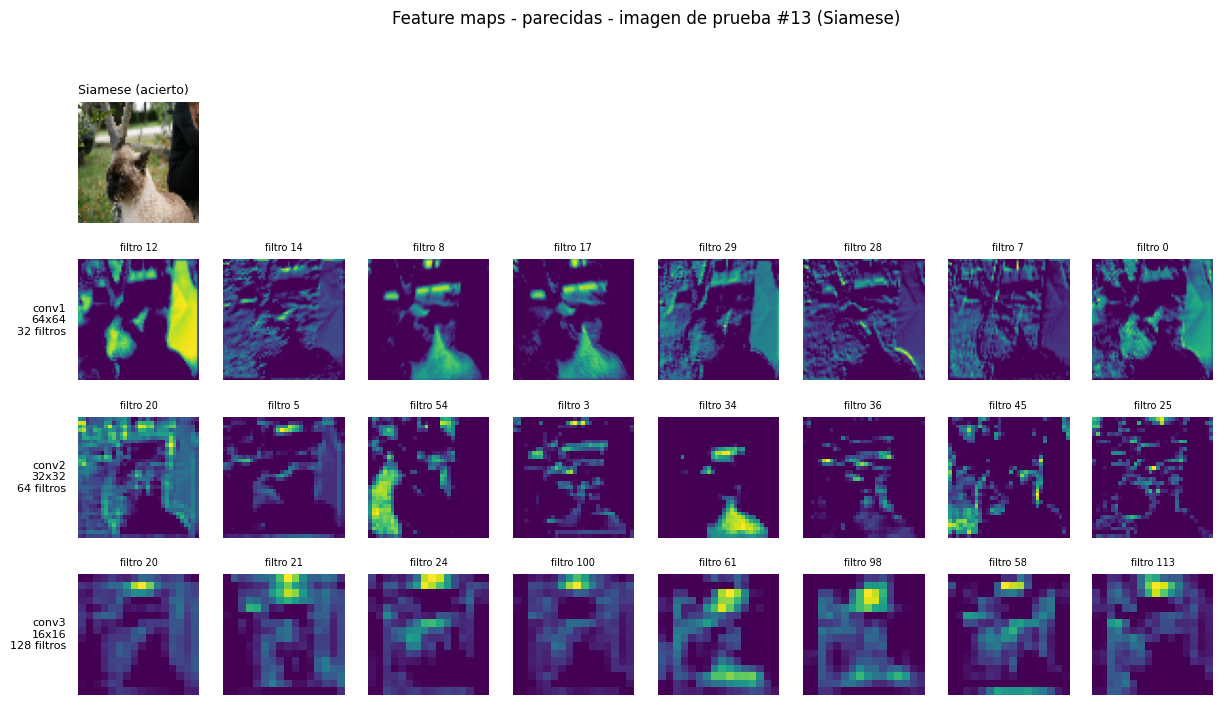

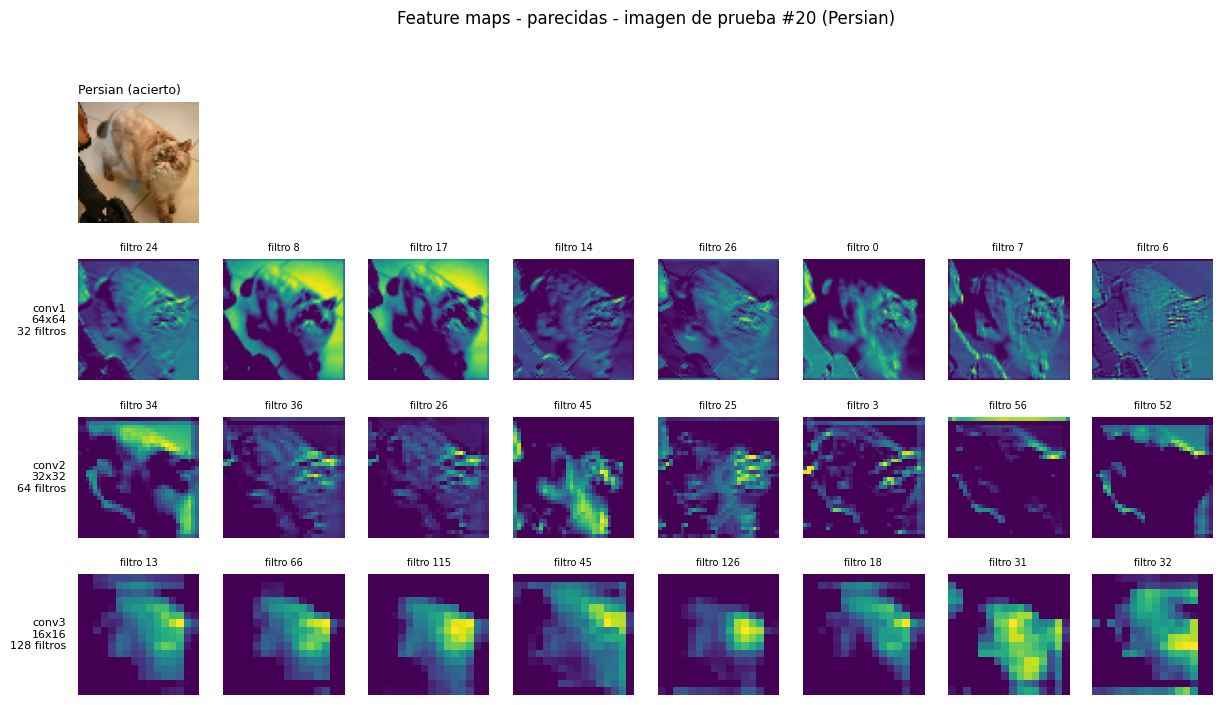

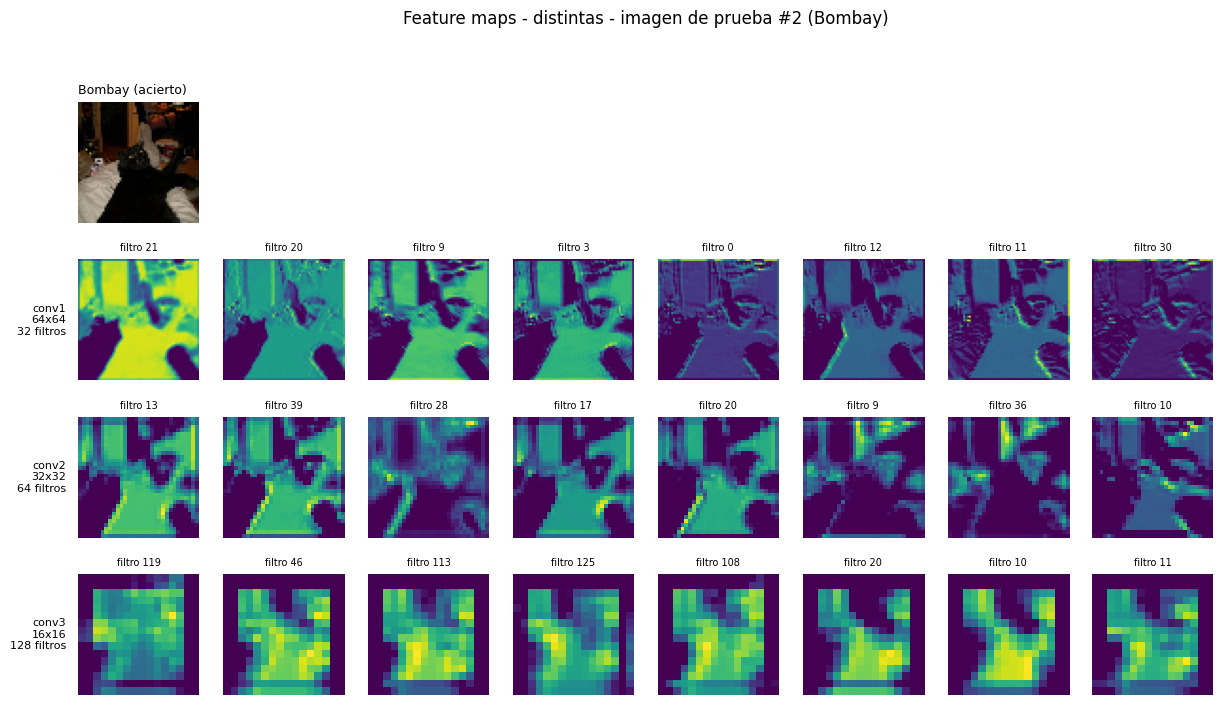

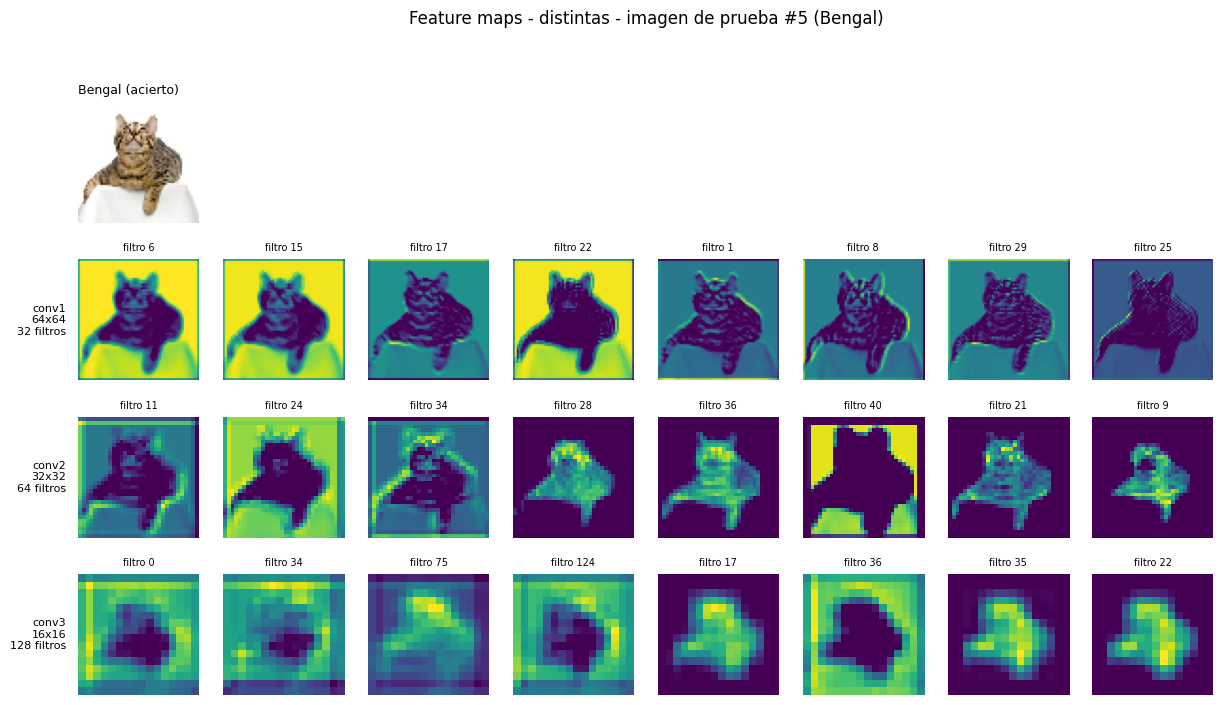

In [27]:
# ==========================================
# FEATURE MAPS DE LAS CAPAS CONVOLUCIONALES (CNN K1, semilla 101, imágenes de prueba)
# ==========================================
CAPAS_CONV = ["conv1", "conv2", "conv3"]
IMAGENES_FM = {"parecidas": ["Siamese", "Persian"], "distintas": ["Bombay", "Bengal"]}

def construir_extractor(modelo, nombres):
    """Reconstruye el modelo como grafo funcional y devuelve las salidas de las capas pedidas + la salida final."""
    entrada = tf.keras.Input(shape=(RES_BASE, RES_BASE, 3))
    x, salidas = entrada, []
    for capa in modelo.layers:
        x = capa(x)
        if capa.name in nombres:
            salidas.append(x)
    return tf.keras.Model(entrada, salidas + [x])

def elegir_imagen(nombre, raza):
    sp = SPLITS[nombre]; clase = sp["clases"].index(raza)
    idx = np.where(sp["y_test"] == clase)[0]
    ok = [i for i in idx if PREDS[nombre][i] == clase]
    return (ok[0] if ok else idx[0]), bool(ok)

def mostrar_feature_maps(nombre, raza, n_mapas=8):
    sp = SPLITS[nombre]
    i, acierto = elegir_imagen(nombre, raza)
    img = sp["X_test"][i]
    extractor = construir_extractor(MODELOS[nombre], CAPAS_CONV)
    mapas = extractor(img[None].astype("float32"), training=False)[:len(CAPAS_CONV)]
    fig, ejes = plt.subplots(len(CAPAS_CONV) + 1, n_mapas, figsize=(1.8 * n_mapas, 1.8 * (len(CAPAS_CONV) + 1) + 0.5))
    for ax in ejes.ravel():
        ax.axis("off")
    ejes[0, 0].imshow(img)
    ejes[0, 0].set_title(f"{raza} ({'acierto' if acierto else 'error'})", fontsize=9, loc="left")
    for f, (capa, m) in enumerate(zip(CAPAS_CONV, mapas), start=1):
        m = m[0].numpy()                                            # (alto, ancho, filtros)
        orden = np.argsort(m.mean(axis=(0, 1)))[::-1][:n_mapas]     # los filtros más activos
        ejes[f, 0].text(-0.1, 0.5, f"{capa}\n{m.shape[0]}x{m.shape[1]}\n{m.shape[2]} filtros", transform=ejes[f, 0].transAxes,
                        ha="right", va="center", fontsize=8)
        for j, k in enumerate(orden):
            ejes[f, j].imshow(m[:, :, k], cmap="viridis")
            ejes[f, j].set_title(f"filtro {k}", fontsize=7)
    fig.subplots_adjust(left=0.1, wspace=0.05, hspace=0.3)
    plt.suptitle(f"Feature maps - {nombre} - imagen de prueba #{i} ({raza})", y=1.0)
    guardar_fig(f"11_feature_maps_{nombre}_{raza}")
    plt.show()

for nombre, razas in IMAGENES_FM.items():
    for raza in razas:
        mostrar_feature_maps(nombre, raza)

### Interpretación de los feature maps

**Cómo se leen.** Cada recuadro es la salida de un filtro: las zonas amarillas o verde claro son donde el filtro responde con más fuerza y el violeta oscuro es respuesta cero (ReLU). Los 8 filtros mostrados por capa son los de mayor activación promedio, lo que favorece a los que responden a zonas grandes (color, brillo) y puede dejar fuera a los que detectan texturas finas y se activan poco.

**Evolución con la profundidad (se repite en las cuatro imágenes).**
- **conv1 (64x64):** los mapas todavía se parecen a la foto. Algunos filtros responden a color y brillo en zonas amplias (en el Bengal, los filtros 14 y 1 resaltan la silueta del gato contra el fondo claro), otros a bordes (el filtro 12 marca líneas finas en las imágenes de Siamese y Bombay) y otros a textura fina (en el Bengal, los filtros 0, 2, 15 y 11 marcan las rayas y manchas del pelaje; en el Persian, los filtros 0 y 14 marcan la textura del pelo).
- **conv2 (32x32):** los mapas están más fragmentados y se parecen menos a la foto. Resaltan contornos y partes del animal (en el Bengal, el contorno del cuerpo y puntos del patrón en los filtros 25, 4 y 7), y otros filtros responden a regiones del fondo o a los bordes de la imagen (en el Persian, los filtros 12, 23 y 26 se activan en la esquina superior derecha).
- **conv3 (16x16):** los mapas son gruesos, en bloques, y sin detalle fino. La activación se concentra en regiones compactas: en el Bengal, los filtros 41, 29, 56, 57 y 3 se encienden sobre el cuerpo del gato, y en el Persian, los filtros 63, 29, 9, 5 y 37 muestran una mancha compacta en la zona central derecha, que coincide aproximadamente con la posición del animal. Esto es coherente con el campo receptivo de `conv3` (18x18 de 64x64, sección 3.2): a esta profundidad la red integra información local y no la forma completa del animal. En consecuencia, la idea de que la tercera capa detecta "orejas, ojos, hocico" **no se confirma** con estas imágenes; los mapas muestran regiones compactas sin esa estructura fina.
- Es lo esperado: a mayor profundidad la representación pasa de "cómo se ve la imagen" a "en qué zona hay algo relevante" (hipótesis, no medida con un indicador).

**Filtros que miran el fondo.** En todas las imágenes hay filtros que responden al fondo o a los bordes en lugar de al animal (Persian: filtros 38, 52 y 12 de conv3; Bengal: filtros 28 y 33 de conv3, y el 33 deja el gato en oscuro y enciende el marco; Bombay: filtros 26, 3 y 9 de conv2, sobre los bordes laterales). Es esperable que parte de lo aprendido sea "qué no es el animal", pero también es una vía por la que el fondo podría influir en la decisión.

**Casos menos claros.**
- *Siamese (imagen #13):* la foto tiene césped, una persona y un objeto en la parte superior. Varios filtros de conv3 (61, 28, 43, 48, 8, 20 y 1) concentran la activación en la parte superior central, donde a esta resolución no se distingue con claridad al gato. No se puede afirmar qué ve ahí la red; es un punto a revisar con los mapas de activación por clase.
- *Bombay (imagen #2):* es un gato negro sobre un fondo oscuro con una zona clara. Casi todos los filtros resaltan el contraste entre la zona clara y las oscuras, y la activación de conv3 se concentra en la parte baja central. Con esta imagen no se puede decir si la red se apoya en el gato o en la zona clara.

**Relación con los resultados (hipótesis, no probadas).**
- En el Bengal, el patrón de manchas y rayas aparece en conv1 y conv2, pero en conv3, a 16x16, queda reducido a manchas gruesas sobre el cuerpo. Si esa pérdida de detalle ocurre en general, podría ayudar a explicar la confusión de Abyssinian con Bengal de la matriz (15 de 27 Abyssinian), aunque una sola imagen no lo prueba.
- Hay filtros muy parecidos entre sí: en conv1, los filtros 3, 4, 5, 15 y 1 de la imagen del Siamese dan mapas casi iguales, y en el Bengal ocurre con los filtros 14 y 1. Con solo 16 filtros en la primera capa, parte de ellos parece redundante.

**Alcance.** Son 4 imágenes elegidas por contraste y solo 8 filtros por capa. Lo que se ve depende de cada imagen y no se probó que un filtro determine la decisión del modelo.

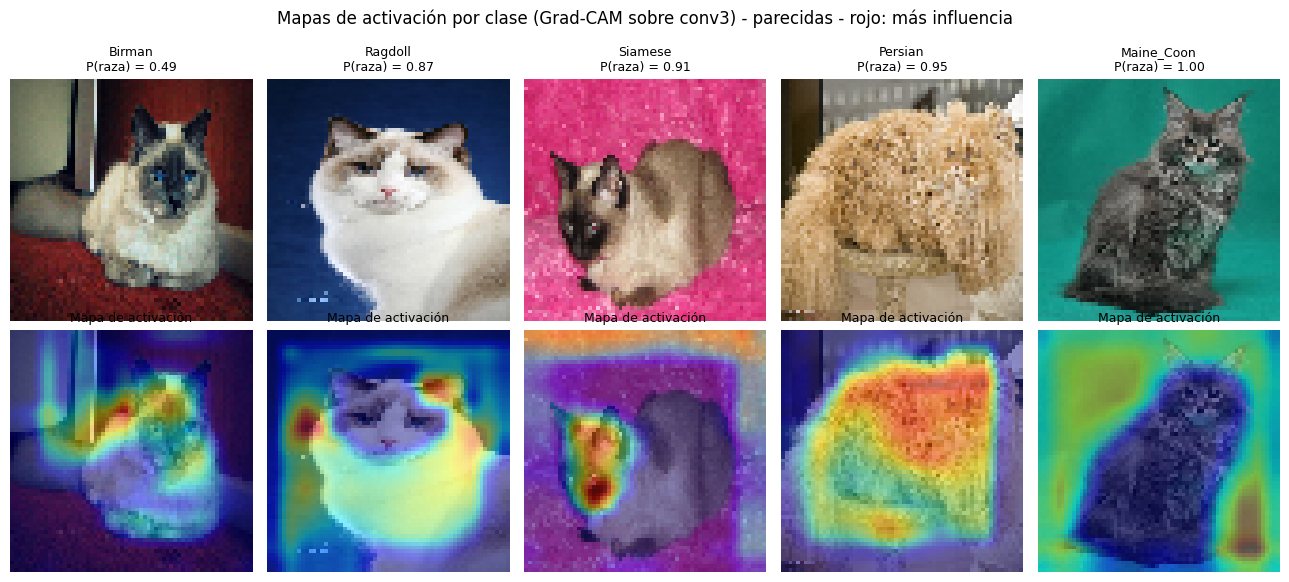

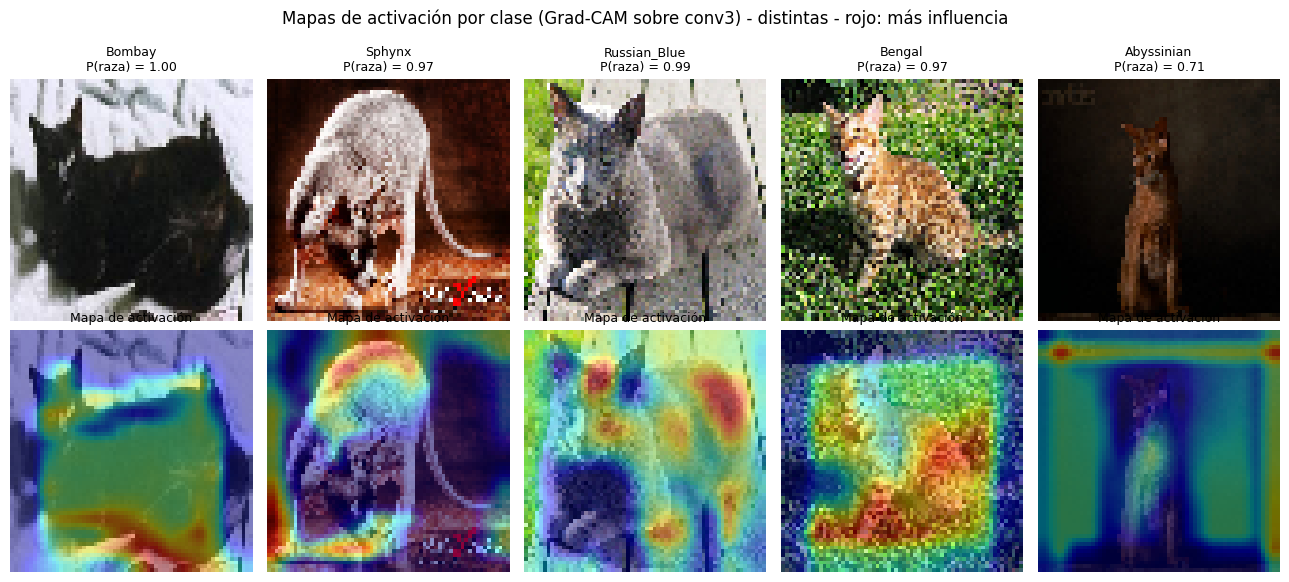

In [28]:
# ==========================================
# MAPAS DE ACTIVACIÓN POR CLASE (Grad-CAM sobre conv3), una imagen por raza
# ==========================================
def calcular_gradcam(modelo, img, clase):
    extractor = construir_extractor(modelo, ["conv3"])
    x = tf.convert_to_tensor(img[None].astype("float32"))
    with tf.GradientTape() as tape:
        conv, probs = extractor(x, training=False)
        puntaje = probs[:, clase]
    grads = tape.gradient(puntaje, conv)
    pesos = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)           # importancia de cada filtro
    cam = tf.nn.relu(tf.reduce_sum(pesos * conv, axis=-1))[0].numpy()   # mapa de 16x16
    return cam / (cam.max() + 1e-8), probs[0].numpy()

def imagen_por_clase(nombre, clase):
    sp = SPLITS[nombre]
    idx = np.where(sp["y_test"] == clase)[0]
    ok = [i for i in idx if PREDS[nombre][i] == clase]
    pool = np.array(ok if ok else idx)
    p = MODELOS[nombre].predict(sp["X_test"][pool], verbose=0)[:, clase]
    return int(pool[int(np.argmax(p))]), bool(ok)

def superponer(ax, img, cam):
    cam_r = np.array(Image.fromarray((cam * 255).astype("uint8")).resize(img.shape[1::-1], Image.BILINEAR)) / 255.0
    ax.imshow(img)
    ax.imshow(cam_r, cmap="jet", alpha=0.45, vmin=0, vmax=1)

for nombre in SPLITS:
    sp = SPLITS[nombre]
    fig, ejes = plt.subplots(2, 5, figsize=(13, 5.8))
    for c, raza in enumerate(sp["clases"]):
        i, acierto = imagen_por_clase(nombre, c)
        img = sp["X_test"][i]
        cam, probs = calcular_gradcam(MODELOS[nombre], img, c)
        ejes[0, c].imshow(img)
        ejes[0, c].set_title(f"{raza}\nP(raza) = {probs[c]:.2f}" + ("" if acierto else " (sin aciertos)"), fontsize=9)
        superponer(ejes[1, c], img, cam)
        ejes[1, c].set_title("Mapa de activación", fontsize=9)
        ejes[0, c].axis("off"); ejes[1, c].axis("off")
    plt.suptitle(f"Mapas de activación por clase (Grad-CAM sobre conv3) - {nombre} - rojo: más influencia", y=1.0)
    plt.tight_layout(); guardar_fig(f"12_gradcam_{nombre}"); plt.show()

### Interpretación de los mapas de activación por clase

**Cómo se leen.** El mapa se pinta sobre la foto: rojo y naranjo son las zonas que más empujaron al modelo hacia esa raza, y azul o violeta las que casi no influyeron. Cada mapa se normaliza por imagen (el máximo de cada una es rojo), así que el color indica influencia relativa dentro de esa foto y no una influencia absoluta comparable entre imágenes. Lo que sigue es lectura visual de una imagen por raza (modelo K1, semilla 101).

**PARECIDAS.**
- *Birman (P = 0,50):* la activación se concentra en la cabeza y el cuerpo casi no influye. Es la probabilidad más baja del subconjunto, coherente con que Birman sea la raza con peor recall (0,222).
- *Ragdoll (P = 0,61):* la zona más activa está en el pecho y cuello blancos, debajo de la cara; la cara tiene poca influencia.
- *Siamese (P = 0,89):* la activación alta está en el **fondo rosado** y en los bordes de la imagen, mientras que el gato casi no influye.
- *Persian (P = 0,82):* la activación cubre gran parte del pelaje del cuerpo, coherente con que el pelaje esponjoso sea su rasgo distintivo.
- *Maine_Coon (P = 0,99):* las zonas cálidas aparecen en el **fondo** (esquinas) y la activación sobre el gato es casi nula.

**DISTINTAS.**
- *Bombay (P = 1,00):* activación moderada sobre el cuerpo del gato y baja en el fondo blanco.
- *Sphynx (P = 0,91):* la zona más activa está en la cabeza y las orejas, y menos a lo largo del cuerpo.
- *Russian_Blue (P = 0,98):* mixta: hay activación sobre el lado izquierdo del gato y también franjas cálidas en el borde superior (fondo).
- *Bengal (P = 0,98):* la activación alta está repartida por gran parte de la imagen, incluido el pasto del fondo, y no se ve concentrada en el animal. Hipótesis, no probada: podría responder a la textura moteada, que el pasto y el pelaje comparten.
- *Abyssinian (P = 0,69):* la zona roja está en la parte baja (cuerpo y pecho) y el fondo marrón liso casi no influye. Es la probabilidad más baja de DISTINTAS, coherente con su bajo recall (0,222 en esta semilla).

**Lectura general (impresión visual).** En unas 6 de las 10 imágenes la activación se apoya principalmente en el animal (Birman, Ragdoll, Persian, Bombay, Sphynx y Abyssinian), en 2 sobre el fondo (Siamese y Maine_Coon) y en 2 es mixta o poco clara (Russian_Blue y Bengal).

**Lo que más importa.** En Siamese y Maine_Coon el modelo asigna probabilidades altas (0,89 y 0,99) mientras la zona que más pesa es el fondo y no el gato. Una explicación posible, **no probada**, es un atajo: con solo 644 imágenes de entrenamiento, el color del fondo (rosado, verde azulado) podría coincidir con una raza en esas fotos y la red lo habría aprendido en lugar de rasgos del animal. Es coherente con dos hallazgos anteriores: en el EDA se observaron fondos de colores intensos, y la EP1 encontró errores con fondos intensos y con alta confianza. Si fuera un atajo, afectaría a la generalización con fotos de otros fondos, y eso es relevante para el uso en la clínica (sección 1.9). Esta impresión se cuantifica en la sección 9.3: promediando las 138 imágenes de prueba, la activación sobre el animal supera moderadamente su área, incluso en Siamese (+0,055) y Maine_Coon (+0,057), así que las imágenes mostradas aquí son casos extremos y no el comportamiento típico.

**Alcance y cautelas.**
- Se muestra una sola imagen por raza, y es la bien clasificada con mayor probabilidad, por lo que no es representativa del conjunto: puede sobrerrepresentar casos en que la red está muy segura.
- El mapa es de 16x16 (capa conv3), así que las zonas son gruesas y no delimitan bien al animal.
- Grad-CAM muestra dónde se apoyó la red, pero no prueba causalidad ni que mirara lo correcto.
- Es una sola semilla. La impresión visual se cuantifica en la sección 9.3 con las máscaras del dataset.

## 9. Análisis de errores

Se analiza el modelo final seleccionado de la semilla 101 sobre el set de prueba (138 imágenes por subconjunto). Hay tres partes:

**9.1 Confianza.** La CNN entrega para cada foto una probabilidad por raza; se toma la de la raza que predice (su "confianza"). Se compara la confianza en los aciertos con la de los errores. Si fuera parecida, la probabilidad no serviría para filtrar predicciones dudosas. En la EP1 el MLP resultó sobreconfiado (confianza promedio cercana a 0,60 con un accuracy de 0,33), y aquí se revisa si la CNN corrige eso. También se cuenta cuántas predicciones recibe cada raza, para detectar una "clase comodín".

**9.2 Galería de ejemplos.** Aciertos (en verde) y errores (en rojo) elegidos al azar con la semilla 2604, y las imágenes del **par más confundido** de cada subconjunto (la raza real y la raza que el modelo predijo, con la mayor cantidad de confusiones). Cada título indica la raza real, la predicha y su probabilidad. Es una muestra pequeña, así que lo que se observe son hipótesis y no conclusiones.

**9.3 ¿La red mira al animal o al fondo?** En la sección 8 los mapas de activación mostraron casos en que la zona más influyente era el fondo. Para pasar de una impresión visual a una medida, se usan las **máscaras (trimaps)** que trae el dataset: para cada píxel indican si pertenece al animal (1), al fondo (2) o a un borde sin clasificar (3). Se calcula, para cada imagen de prueba, qué **fracción de la activación** del mapa de la raza verdadera cae sobre el animal, y se compara con la **fracción del área** de la imagen que ocupa el animal (que es lo que se esperaría si la red no distinguiera entre animal y fondo). Si la fracción de activación es mayor que la del área, la red se apoya en el animal más de lo esperado por azar; si es parecida, no distingue; si es menor, favorece el fondo.

**Alcance.** El mapa de activación proviene de `conv3` (16x16) ampliado a 64x64, así que es grueso; la máscara se reduce a 64x64 con el vecino más cercano. Es una sola semilla, y la medida describe dónde se apoya la red, no prueba que esa zona cause la decisión. Las razas más difíciles se identifican con el recall por raza de la sección 6.1, y las causas posibles que se discuten son hipótesis.

=== parecidas ===
Aciertos: 54 de 138 | errores: 84
Confianza media (probabilidad de la raza predicha): aciertos 0.500 | errores 0.490 | global 0.494 | accuracy 0.391
Confianza máxima: 1.000 | errores con confianza >= 0.8: 6 de 84 | aciertos con confianza >= 0.8: 6 de 54
Predicciones por raza (soporte real entre paréntesis): Birman 27 (27), Ragdoll 26 (28), Siamese 35 (28), Persian 23 (28), Maine_Coon 27 (27)
Par más confundido: Persian (real) -> Ragdoll (predicha): 10 de 28 imágenes



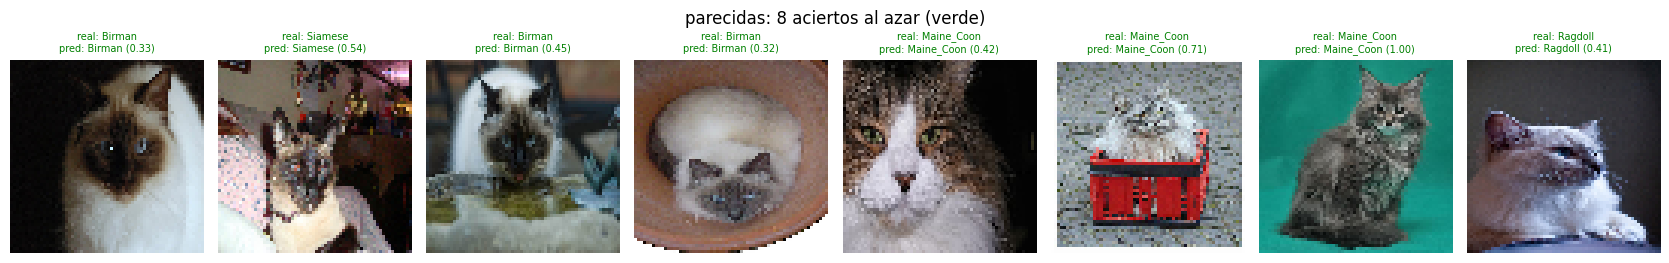

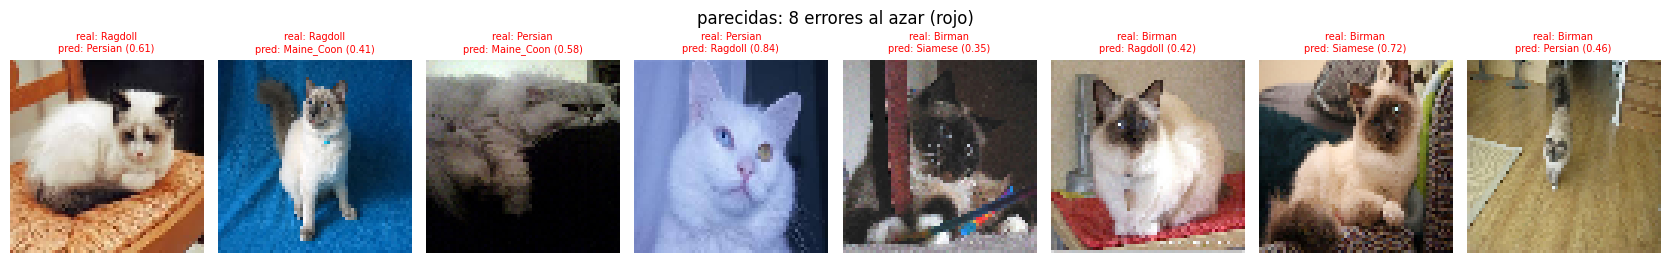

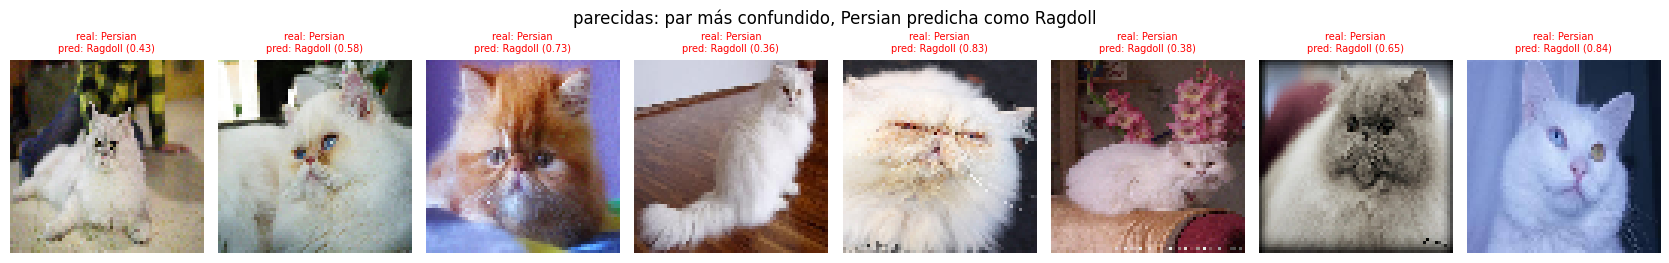

=== distintas ===
Aciertos: 84 de 138 | errores: 54
Confianza media (probabilidad de la raza predicha): aciertos 0.797 | errores 0.642 | global 0.736 | accuracy 0.609
Confianza máxima: 1.000 | errores con confianza >= 0.8: 11 de 54 | aciertos con confianza >= 0.8: 45 de 84
Predicciones por raza (soporte real entre paréntesis): Bombay 35 (27), Sphynx 22 (28), Russian_Blue 26 (28), Bengal 40 (28), Abyssinian 15 (27)
Par más confundido: Abyssinian (real) -> Bengal (predicha): 14 de 27 imágenes



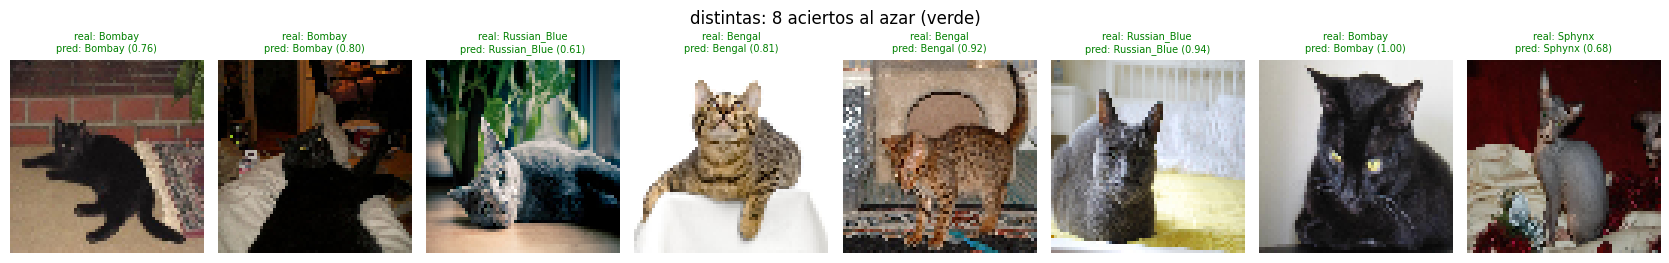

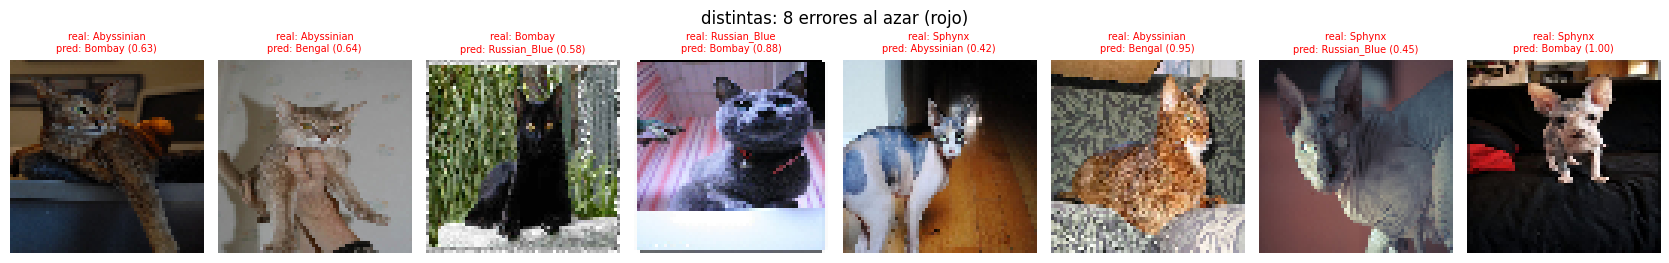

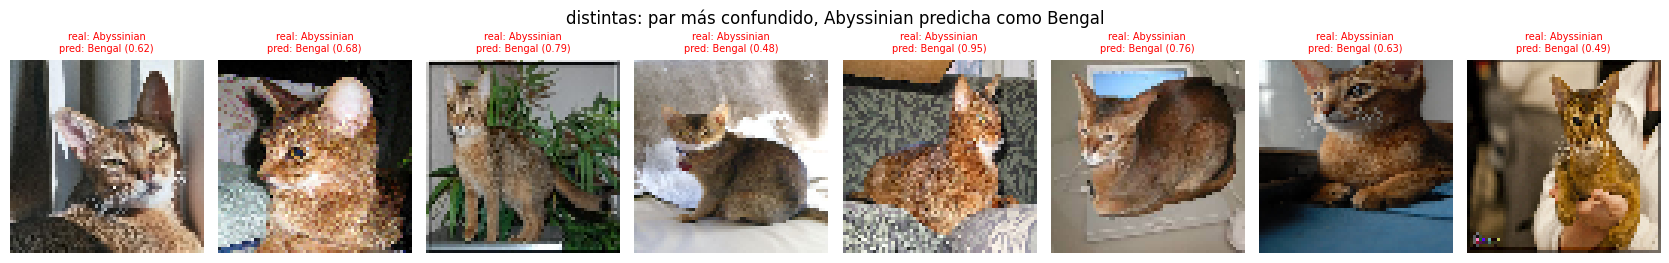

In [29]:
# ==========================================
# ANÁLISIS DE ERRORES: CONFIANZA Y GALERÍAS (CNN K1, semilla 101, set de prueba)
# ==========================================
rng = np.random.default_rng(SEED_SPLIT)
INFO = {}

def galeria(nombre, indices, titulo, archivo, columnas=8):
    sp = SPLITS[nombre]; info = INFO[nombre]
    filas = int(np.ceil(len(indices) / columnas))
    fig, ejes = plt.subplots(filas, columnas, figsize=(2.1 * columnas, 2.6 * filas))
    ejes = np.atleast_2d(ejes)
    for ax in ejes.ravel():
        ax.axis("off")
    for ax, i in zip(ejes.ravel(), indices):
        ax.imshow(sp["X_test"][i])
        real, pr = sp["clases"][sp["y_test"][i]], sp["clases"][info["pred"][i]]
        ax.set_title(f"real: {real}\npred: {pr} ({info['conf'][i]:.2f})", fontsize=7,
                     color="green" if info["ok"][i] else "red")
    plt.suptitle(titulo, y=1.0)
    plt.tight_layout(); guardar_fig(archivo); plt.show()

for nombre in SPLITS:
    sp = SPLITS[nombre]; y = sp["y_test"]; clases = sp["clases"]
    probs = MODELOS[nombre].predict(sp["X_test"], verbose=0)
    pred = probs.argmax(axis=1)
    assert (pred == PREDS[nombre]).all(), "Las predicciones no coinciden con las de la evaluación final"
    conf, ok = probs.max(axis=1), pred == y
    INFO[nombre] = dict(probs=probs, pred=pred, conf=conf, ok=ok)

    print(f"=== {nombre} ===")
    print(f"Aciertos: {ok.sum()} de {len(y)} | errores: {(~ok).sum()}")
    print(f"Confianza media (probabilidad de la raza predicha): aciertos {conf[ok].mean():.3f} | "
          f"errores {conf[~ok].mean():.3f} | global {conf.mean():.3f} | accuracy {ok.mean():.3f}")
    print(f"Confianza máxima: {conf.max():.3f} | errores con confianza >= 0.8: {(conf[~ok] >= 0.8).sum()} de {(~ok).sum()} "
          f"| aciertos con confianza >= 0.8: {(conf[ok] >= 0.8).sum()} de {ok.sum()}")
    print("Predicciones por raza (soporte real entre paréntesis): " +
          ", ".join(f"{c} {n} ({s})" for c, n, s in zip(clases, np.bincount(pred, minlength=len(clases)),
                                                       np.bincount(y, minlength=len(clases)))))
    cm = confusion_matrix(y, pred)
    off = cm.copy(); np.fill_diagonal(off, 0)
    a, b = np.unravel_index(off.argmax(), off.shape)
    print(f"Par más confundido: {clases[a]} (real) -> {clases[b]} (predicha): {off[a, b]} de {cm[a].sum()} imágenes\n")

    idx_ok = rng.choice(np.where(ok)[0], 8, replace=False)
    idx_err = rng.choice(np.where(~ok)[0], 8, replace=False)
    galeria(nombre, idx_ok, f"{nombre}: 8 aciertos al azar (verde)", f"13_aciertos_{nombre}")
    galeria(nombre, idx_err, f"{nombre}: 8 errores al azar (rojo)", f"14_errores_{nombre}")
    idx_par = np.where((y == a) & (pred == b))[0][:8]
    galeria(nombre, idx_par, f"{nombre}: par más confundido, {clases[a]} predicha como {clases[b]}", f"15_par_confundido_{nombre}")

### Interpretación del análisis de errores: confianza y ejemplos

En PARECIDAS la confianza media casi no separa aciertos y errores (0,500 vs 0,490); con umbral 0,8 hubo seis aciertos y seis errores en semilla 101. En DISTINTAS separa mejor (0,797 vs 0,642), pero aún hay 11 errores de alta confianza; 45 de 56 predicciones seguras fueron correctas (80,4%). Mantener revisión humana. K1 predice Siamese 35 veces (28 reales) y Persian 23 (28 reales); en DISTINTAS predice Bengal 40 (28 reales) y Abyssinian 15 (27 reales). La confusión más común de la semilla 101 es Persian→Ragdoll (10/28) y Abyssinian→Bengal (14/27). La galería ilustra, no explica causalmente.


Máscaras (trimaps) que faltan para las imágenes de prueba: 0
=== parecidas === valores distintos en las máscaras: [1, 2, 3] (1 = animal, 2 = fondo, 3 = borde)
Imágenes con mapa de activación nulo (excluidas): 0
Fracción del área que ocupa el animal: media 0.367
Fracción de la activación sobre el animal: media 0.503 | mediana 0.502
Imágenes en que la activación sobre el animal supera a su área: 100 de 138
Aciertos: activación sobre el animal 0.543 (área 0.387) | errores: 0.478 (área 0.355)
            share   area  diferencia
raza                                
Birman      0.512  0.343       0.169
Ragdoll     0.616  0.377       0.239
Siamese     0.469  0.341       0.127
Persian     0.543  0.455       0.088
Maine_Coon  0.373  0.319       0.055 

=== distintas === valores distintos en las máscaras: [1, 2, 3] (1 = animal, 2 = fondo, 3 = borde)
Imágenes con mapa de activación nulo (excluidas): 0
Fracción del área que ocupa el animal: media 0.284
Fracción de la activación sobre el animal: m

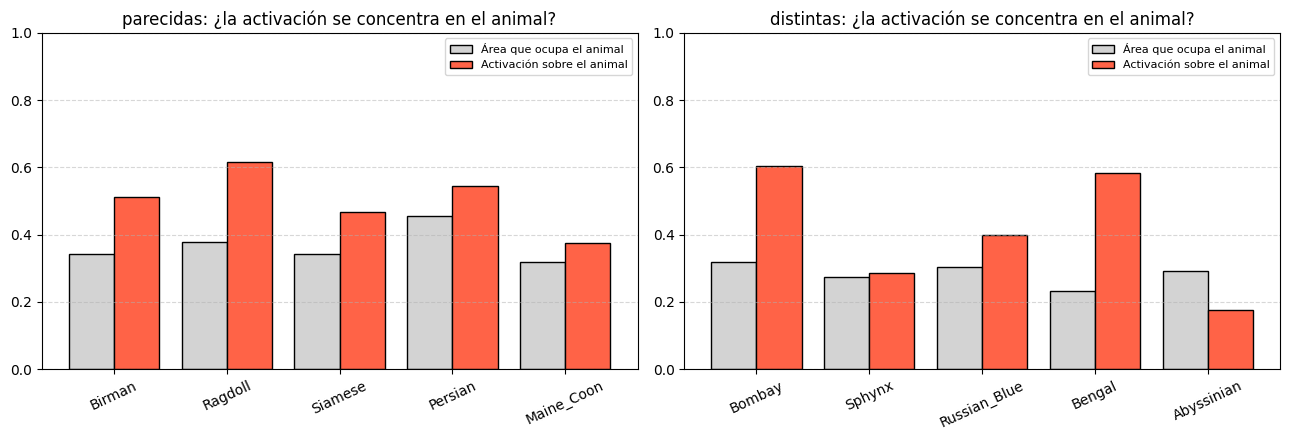

In [30]:
# ==========================================
# ¿LA RED MIRA AL ANIMAL? FRACCIÓN DE LA ACTIVACIÓN (Grad-CAM) QUE CAE SOBRE EL GATO
# ==========================================
RUTA_TRIMAPS = "/content/annotations/trimaps"

def cargar_mascara(imagen, lado=RES_BASE):
    ruta = f"{RUTA_TRIMAPS}/{imagen}.png"
    if not os.path.exists(ruta):
        return None
    return np.array(Image.open(ruta).resize((lado, lado), Image.NEAREST))

def gradcam_lote(modelo, X, clases):
    extractor = construir_extractor(modelo, ["conv3"])
    x = tf.convert_to_tensor(X.astype("float32"))
    with tf.GradientTape() as tape:
        conv, probs = extractor(x, training=False)
        puntaje = tf.reduce_sum(tf.gather(probs, clases, axis=1, batch_dims=1))
    grads = tape.gradient(puntaje, conv)
    pesos = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(pesos * conv, axis=-1))
    cam = tf.image.resize(cam[..., None], (RES_BASE, RES_BASE), method="bilinear")[..., 0]
    return cam.numpy()

faltan = sum(cargar_mascara(im) is None for nombre in SPLITS for im in SPLITS[nombre]["test"]["imagen"])
print(f"Máscaras (trimaps) que faltan para las imágenes de prueba: {faltan}")

if faltan == 0:
    fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, nombre in zip(ejes, SPLITS):
        sp = SPLITS[nombre]; y = sp["y_test"]; clases = sp["clases"]; ok = INFO[nombre]["ok"]
        M = np.stack([cargar_mascara(im) for im in sp["test"]["imagen"]])
        print(f"=== {nombre} === valores distintos en las máscaras: {np.unique(M).tolist()} (1 = animal, 2 = fondo, 3 = borde)")
        animal = (M == 1)
        cam = gradcam_lote(MODELOS[nombre], sp["X_test"], y)       # mapa de la raza verdadera
        suma = cam.sum(axis=(1, 2)); valido = suma > 0
        share = np.where(valido, (cam * animal).sum(axis=(1, 2)) / np.where(valido, suma, 1), np.nan)
        area = animal.mean(axis=(1, 2))
        print(f"Imágenes con mapa de activación nulo (excluidas): {(~valido).sum()}")
        print(f"Fracción del área que ocupa el animal: media {np.nanmean(area):.3f}")
        print(f"Fracción de la activación sobre el animal: media {np.nanmean(share):.3f} | mediana {np.nanmedian(share):.3f}")
        print(f"Imágenes en que la activación sobre el animal supera a su área: {np.nansum(share > area)} de {valido.sum()}")
        print(f"Aciertos: activación sobre el animal {np.nanmean(share[ok]):.3f} (área {area[ok].mean():.3f}) | "
              f"errores: {np.nanmean(share[~ok]):.3f} (área {area[~ok].mean():.3f})")
        tabla = pd.DataFrame({"raza": [clases[c] for c in y], "share": share, "area": area}).groupby("raza", sort=False).mean()
        tabla["diferencia"] = tabla["share"] - tabla["area"]
        print(tabla.reindex(clases).round(3).to_string(), "\n")
        x = np.arange(len(clases)); t = tabla.reindex(clases)
        ax.bar(x - 0.2, t["area"], 0.4, color="lightgray", edgecolor="black", label="Área que ocupa el animal")
        ax.bar(x + 0.2, t["share"], 0.4, color="tomato", edgecolor="black", label="Activación sobre el animal")
        ax.set_xticks(x); ax.set_xticklabels(clases, rotation=25); ax.set_ylim(0, 1)
        ax.set_title(f"{nombre}: ¿la activación se concentra en el animal?"); ax.legend(fontsize=8)
        ax.grid(True, axis="y", linestyle="--", alpha=0.5)
    plt.tight_layout(); guardar_fig("16_activacion_sobre_animal"); plt.show()
else:
    print("No se encontraron las máscaras en la carpeta de anotaciones; esta medida se omite.")

### Interpretación: ¿la red mira al animal o al fondo?

Con Grad-CAM de probabilidad y clase verdadera, el animal ocupa 36,7% del área en PARECIDAS y recibe 50,3% de activación (+13,6 puntos); 100/138 imágenes superan su área. En DISTINTAS ocupa 28,4% y recibe 41,0% (+12,6); 94/138 superan el área. Sugiere atención moderadamente mayor al animal, pero hay excepciones: Abyssinian recibe 17,7% para 29,1% de área; Sphynx queda cerca (28,6% vs 27,4%). En DISTINTAS la activación animal es mayor en aciertos (49,3%) que errores (28,0%); en PARECIDAS la diferencia es menor (54,3% vs 47,8%). Grad-CAM es aproximado, no prueba causal.


### 9.4 Comprobación: Grad-CAM con el puntaje previo al softmax

Los mapas de las secciones 8 y 9.3 se calcularon derivando la **probabilidad** de la raza (salida softmax). La formulación original de Grad-CAM usa el **puntaje previo al softmax** (logit). Con probabilidades cercanas a 1 el gradiente se aplana, y el mapa tiende a reflejar qué separa a una raza de las otras más que la evidencia a su favor. Esta celda repite la medida de 9.3 con logits, para comprobar si la conclusión sobre "animal frente a fondo" depende de ese detalle.

In [31]:
# ==========================================
# COMPROBACIÓN: GRAD-CAM CON LOGITS (PUNTAJE PREVIO AL SOFTMAX) vs. PROBABILIDAD
# ==========================================
def gradcam_lote_logits(modelo, X, clases):
    entrada = tf.keras.Input(shape=(RES_BASE, RES_BASE, 3))
    x, conv = entrada, None
    for capa in modelo.layers[:-1]:                    # todas menos la Dense(5) con softmax
        x = capa(x)
        if capa.name == "conv3":
            conv = x
    ext = tf.keras.Model(entrada, [conv, x])
    W, b = modelo.layers[-1].get_weights()
    xt = tf.convert_to_tensor(X.astype("float32"))
    with tf.GradientTape() as tape:
        conv_o, pen = ext(xt, training=False)
        logits = tf.matmul(pen, W) + b
        puntaje = tf.reduce_sum(tf.gather(logits, clases, axis=1, batch_dims=1))
    grads = tape.gradient(puntaje, conv_o)
    pesos = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(pesos * conv_o, axis=-1))
    cam = tf.image.resize(cam[..., None], (RES_BASE, RES_BASE), method="bilinear")[..., 0]
    return cam.numpy()

def fraccion_animal(cam, animal):
    suma = cam.sum(axis=(1, 2)); valido = suma > 0
    return np.where(valido, (cam * animal).sum(axis=(1, 2)) / np.where(valido, suma, 1), np.nan)

for nombre in SPLITS:
    sp = SPLITS[nombre]; y = sp["y_test"]; clases = sp["clases"]
    M = np.stack([cargar_mascara(im) for im in sp["test"]["imagen"]]); animal = (M == 1); area = animal.mean(axis=(1, 2))
    cam_p = gradcam_lote(MODELOS[nombre], sp["X_test"], y)                 # con probabilidad (secciones 8 y 9.3)
    cam_l = gradcam_lote_logits(MODELOS[nombre], sp["X_test"], y)           # con logits
    sh_p, sh_l = fraccion_animal(cam_p, animal), fraccion_animal(cam_l, animal)
    corr = np.nanmean([np.corrcoef(a.ravel(), b.ravel())[0, 1] for a, b in zip(cam_p, cam_l)])
    print(f"=== {nombre} === mapas nulos con logits: {int(np.isnan(sh_l).sum())} | correlación media entre ambos mapas: {corr:.3f}")
    print(f"Activación sobre el animal: probabilidad {np.nanmean(sh_p):.3f} | logits {np.nanmean(sh_l):.3f} | área del animal {area.mean():.3f}")
    t = pd.DataFrame({"raza": [clases[c] for c in y], "prob": sh_p - area, "logits": sh_l - area}).groupby("raza", sort=False).mean()
    print("Ventaja (activación - área) por raza:"); print(t.reindex(clases).round(3).to_string(), "\n")

=== parecidas === mapas nulos con logits: 0 | correlación media entre ambos mapas: 0.831
Activación sobre el animal: probabilidad 0.503 | logits 0.535 | área del animal 0.367
Ventaja (activación - área) por raza:
             prob  logits
raza                     
Birman      0.169   0.192
Ragdoll     0.239   0.232
Siamese     0.127   0.140
Persian     0.088   0.097
Maine_Coon  0.055   0.180 

=== distintas === mapas nulos con logits: 0 | correlación media entre ambos mapas: 0.732
Activación sobre el animal: probabilidad 0.410 | logits 0.433 | área del animal 0.284
Ventaja (activación - área) por raza:
               prob  logits
raza                       
Bombay        0.284   0.261
Sphynx        0.012   0.033
Russian_Blue  0.094   0.081
Bengal        0.351   0.293
Abyssinian   -0.114   0.080 



**Comprobación con logits.** La conclusión global se mantiene: activación sobre el animal 53,5% vs área 36,7% en PARECIDAS, y 43,3% vs 28,4% en DISTINTAS. La correlación entre mapas de probabilidad/logits es 0,831 y 0,732: similares, no idénticos. Para Abyssinian, la ventaja cambia de −0,114 con probabilidades a +0,080 con logits; no es sólido afirmar menor atención al animal para esa clase. La conclusión general es más robusta que las lecturas por raza.


## Anexo A. Ablaciones complementarias de las decisiones de diseño

Estas pruebas se diseñaron **después de ver la evaluación en prueba**, para respaldar con datos las decisiones de arquitectura de la sección 3. Se hacen solo sobre PARECIDAS y en **validación**, con las mismas 3 semillas de la sección 5, y **no cambian el modelo final seleccionado (K1 esperado; confirmar tras repetir selección)**. Se incluye un control K3 que reproduce la sección 5 para comprobar la comparabilidad. Una diferencia se considera relevante solo si supera la suma de las desviaciones (criterio de la sección 1.6).

| Ablación | Qué se prueba |
|---|---|
| A1 | `Flatten` en lugar de `GlobalAveragePooling` |
| A2 | Filtros de 5x5 en lugar de 3x3 |
| A3 | Cuatro bloques (16-32-64-128) en lugar de tres |
| A4 | `BatchNormalization` en cada bloque |
| A5 | Entrada de 128x128 |
| A6 | `EarlyStopping` que empieza a vigilar desde la época 20 (para evitar casos como la semilla 102) |
| A7 | Recorte central que conserva la proporción, en lugar de deformar la imagen |

In [32]:
# ==========================================
# ANEXO A: ABLACIONES COMPLEMENTARIAS (PARECIDAS, VALIDACIÓN, 3 semillas)
# ==========================================
def crear_cnn_v2(n_clases, filtros=(16, 32, 64), kernel=3, densa=64, dropout=0.3, lr=1e-3,
                 salida="gap", bn=False, X_adapt=None):
    res = X_adapt.shape[1]
    capas = [layers.Input(shape=(res, res, 3)),
             layers.RandomFlip("horizontal"), layers.RandomRotation(0.055), layers.RandomTranslation(0.1, 0.1),
             layers.Rescaling(1 / 255)]
    norm = layers.Normalization(axis=-1)
    norm.adapt(X_adapt.astype("float32") / 255.0)
    capas.append(norm)
    for i, f in enumerate(filtros, start=1):
        if bn:
            capas += [layers.Conv2D(f, kernel, padding="same", use_bias=False, name=f"conv{i}"),
                      layers.BatchNormalization(), layers.Activation("relu")]
        else:
            capas.append(layers.Conv2D(f, kernel, padding="same", activation="relu", name=f"conv{i}"))
        capas.append(layers.MaxPooling2D(2, name=f"pool{i}"))
    capas.append(layers.GlobalAveragePooling2D() if salida == "gap" else layers.Flatten())
    capas += [layers.Dense(densa, activation="relu"), layers.Dropout(dropout),
              layers.Dense(n_clases, activation="softmax")]
    m = models.Sequential(capas)
    m.compile(optimizer=optimizers.Adam(learning_rate=lr),
              loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m

def entrenar_v2(Xtr, ytr, Xva, yva, seed, paciencia=PACIENCIA, start=0, **cfg):
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    m = crear_cnn_v2(5, X_adapt=Xtr, **cfg)
    es = EarlyStopping(monitor="val_loss", patience=paciencia, restore_best_weights=True, start_from_epoch=start)
    t0 = time.time()
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=EPOCAS_MAX, batch_size=BATCH_SIZE,
              callbacks=[es], verbose=0)
    return m, h, time.time() - t0

sp = SPLITS["parecidas"]
def cargar_recorte(df, lado):                      # recorte central que conserva la proporción
    return np.stack([np.array(tf.keras.utils.load_img(r, target_size=(lado, lado), keep_aspect_ratio=True))
                     for r in df["ruta"]]).astype("uint8")

DATOS = {"64": (sp["XR"][64]["train"], sp["XR"][64]["val"]),
         "128": (sp["XR"][128]["train"], sp["XR"][128]["val"]),
         "64 recorte": (cargar_recorte(sp["train"], 64), cargar_recorte(sp["val"], 64))}

ABLACIONES = {                                      # nombre: (datos, cambios de arquitectura, cambios de entrenamiento)
    "K3 control": ("64", {}, {}),
    "A1 Flatten (sin GAP)": ("64", dict(salida="flatten"), {}),
    "A2 filtros 5x5": ("64", dict(kernel=5), {}),
    "A3 cuatro bloques": ("64", dict(filtros=(16, 32, 64, 128)), {}),
    "A4 BatchNorm": ("64", dict(bn=True), {}),
    "A5 entrada 128x128": ("128", {}, {}),
    "A6 parada desde época 20": ("64", {}, dict(start=20)),
    "A7 recorte central": ("64 recorte", {}, {}),
}

filas = []
for nombre_ab, (clave, cambios, extra) in ABLACIONES.items():
    Xtr, Xva = DATOS[clave]
    for s in SEEDS_EXP:
        m, h, seg = entrenar_v2(Xtr, sp["y_train"], Xva, sp["y_val"], s, **extra, **cambios)
        met, _ = metricas(m, Xva, sp["y_val"])
        filas.append(dict(config=nombre_ab, semilla=s, parametros=m.count_params(), f1_val=met["f1"], acc_val=met["acc"],
                          val_loss=min(h.history["val_loss"]), epocas=len(h.history["loss"]), segundos=seg))
        pd.DataFrame(filas).to_csv("resultados/ablaciones_por_semilla.csv", index=False)
        print(f"{nombre_ab} | semilla {s} | F1 val {met['f1']:.3f} | {len(h.history['loss'])} épocas | {seg/60:.1f} min")

ab = pd.DataFrame(filas)
res_ab = ab.groupby("config", sort=False).agg(parametros=("parametros", "first"), f1_media=("f1_val", "mean"),
                                              f1_std=("f1_val", "std"), acc_val=("acc_val", "mean"),
                                              val_loss=("val_loss", "mean"), minutos=("segundos", lambda x: x.mean() / 60))
ctrl = res_ab.loc["K3 control"]
res_ab["dif_vs_control"] = res_ab["f1_media"] - ctrl["f1_media"]
res_ab["veredicto"] = ["referencia" if c == "K3 control" else
                       ("relevante" if abs(r["dif_vs_control"]) > r["f1_std"] + ctrl["f1_std"] else "empate técnico")
                       for c, r in res_ab.iterrows()]
print(res_ab.round(3).to_string())
res_ab.to_csv("resultados/ablaciones_resumen.csv")
ref = pd.read_csv("resultados/experimentos_cnn_por_semilla.csv")
print("\nReferencia de la sección 5 para K3 (semillas 11, 22, 33):", ref.loc[ref["config"] == "K3 filtros 16-32-64", "f1_val"].round(3).tolist())

K3 control | semilla 11 | F1 val 0.254 | 20 épocas | 0.1 min
K3 control | semilla 22 | F1 val 0.343 | 32 épocas | 0.2 min
K3 control | semilla 33 | F1 val 0.349 | 29 épocas | 0.2 min
A1 Flatten (sin GAP) | semilla 11 | F1 val 0.413 | 22 épocas | 0.1 min
A1 Flatten (sin GAP) | semilla 22 | F1 val 0.463 | 20 épocas | 0.1 min
A1 Flatten (sin GAP) | semilla 33 | F1 val 0.395 | 24 épocas | 0.2 min
A2 filtros 5x5 | semilla 11 | F1 val 0.443 | 47 épocas | 0.3 min
A2 filtros 5x5 | semilla 22 | F1 val 0.539 | 62 épocas | 0.3 min
A2 filtros 5x5 | semilla 33 | F1 val 0.457 | 52 épocas | 0.3 min
A3 cuatro bloques | semilla 11 | F1 val 0.422 | 44 épocas | 0.3 min
A3 cuatro bloques | semilla 22 | F1 val 0.340 | 24 épocas | 0.2 min
A3 cuatro bloques | semilla 33 | F1 val 0.371 | 26 épocas | 0.2 min
A4 BatchNorm | semilla 11 | F1 val 0.383 | 35 épocas | 0.3 min
A4 BatchNorm | semilla 22 | F1 val 0.388 | 31 épocas | 0.2 min
A4 BatchNorm | semilla 33 | F1 val 0.395 | 37 épocas | 0.3 min
A5 entrada 128x1

**Interpretación de las ablaciones.** El control K3 reproduce los F1 de la sección 5 (0,254; 0,343; 0,349). Frente al control (0,315 ± 0,053), Flatten llega a 0,424 ± 0,036 (+0,108), 5x5 a 0,480 ± 0,052 (+0,164) y BatchNorm a 0,389 ± 0,006 (+0,074); superan la suma de desviaciones usada como regla. Cuatro bloques (+0,062), 128x128 (−0,002), parada desde época 20 (+0,016) y recorte (+0,020) quedan como empate técnico bajo esa regla.

Son pruebas exploratorias, posteriores a revisar el test y solo en validación PARECIDAS. No justifican cambiar K1 ni afirman mejora en prueba. Matizan la elección de GAP/3x3; haría falta evaluación independiente para escoger alternativas.


## 10. Conclusiones

La selección por validación eligió **K1 (dropout 0,5)** con F1 0,381 ± 0,028. En prueba logra F1 0,518 ± 0,084 en DISTINTAS (cumple KPI ≥0,40) y 0,330 ± 0,064 en PARECIDAS (no cumple). El recall mínimo no cumple ≥0,20 en ninguno (0,139 y 0,122), por fallas concentradas en ciertas razas.

Frente al MLP, K1 mejora los promedios en DISTINTAS y queda debajo en PARECIDAS; con cinco semillas y una partición no se concluye superioridad estadística. Tiene unas 15,5 veces menos parámetros, pero fue más lento en esta sesión. Las confusiones principales son Abyssinian→Bengal y Birman→Siamese. Grad-CAM sugiere activación moderadamente mayor sobre el animal que su área, con excepciones y dependencia de la formulación.

Flatten, filtros 5x5 y BatchNorm mejoraron el F1 de validación frente al control en pruebas exploratorias hechas después de revisar el test; no son evidencia de mejora en test. Las limitaciones incluyen partición fija, test pequeño y pocas semillas. El modelo puede apoyar a una persona, especialmente en DISTINTAS, pero no debe clasificar sin revisión humana.


## 11. Archivos del proyecto

La última celda deja el proyecto ordenado en la carpeta `entrega_EP2/` (y en un `.zip` para descargarla), con la estructura que pide la pauta:

- `data/`: `particiones.csv`, con la lista de imágenes de cada subconjunto y partición (entrenamiento, validación y prueba), su raza y su etiqueta numérica. Permite reproducir exactamente el reparto. Las fotos originales no se incluyen por tamaño: el notebook las descarga del sitio oficial del Oxford-IIIT Pet Dataset.
- `images/`: las figuras generadas por el notebook (distribución de clases, curvas, matrices de confusión, feature maps, mapas de activación, comparaciones).
- `models/`: los modelos guardados de la semilla 101 (CNN final seleccionado y MLP, para cada subconjunto).
- `resultados/`: las tablas en CSV (experimentos, evaluación por semilla, resúmenes y comparaciones).
- `notebooks/`: aquí debe quedar este notebook (`.ipynb`) ya ejecutado.
- `README.md`: el informe técnico en Markdown.

En Colab, la carpeta `images/` mezcla las fotos del dataset (descargadas ahí) con las figuras, por eso la celda copia solo los archivos `.png` a la carpeta de entrega.

In [33]:
# ==========================================
# ARCHIVOS DEL PROYECTO: NOTEBOOK, README Y ZIP
# ==========================================
from pathlib import Path
import shutil, glob

RAIZ = Path("entrega_EP2")
for sub in ["data", "images", "models", "resultados", "notebooks"]:
    (RAIZ / sub).mkdir(parents=True, exist_ok=True)

# --- Lista reproducible de imágenes por subconjunto y partición ---
partes = []
for nombre, sp in SPLITS.items():
    for parte in ["train", "val", "test"]:
        d = sp[parte][["imagen", "raza", "y"]].copy()
        d.insert(0, "particion", parte)
        d.insert(0, "subconjunto", nombre)
        partes.append(d)
particiones = pd.concat(partes, ignore_index=True)
particiones.to_csv(RAIZ / "data" / "particiones.csv", index=False)
print("Imágenes por subconjunto y partición:")
print(particiones.groupby(["subconjunto", "particion"]).size().unstack().to_string(), "\n")

# --- Copiar figuras, modelos y resultados ya generados ---
for patron, destino in [("images/*.png", "images"), ("models/*.keras", "models"),
                        ("resultados/*.csv", "resultados")]:
    for archivo in glob.glob(patron):
        shutil.copy2(archivo, RAIZ / destino / Path(archivo).name)

# El notebook debe estar en el directorio de trabajo al ejecutar esta celda.
# Si tiene otro nombre o está en otra ruta, cambia NOTEBOOK_ORIGEN.
NOTEBOOK_ORIGEN = Path("EP2_CNN_Razas_Gatos_preparado_K1.ipynb")
if not NOTEBOOK_ORIGEN.is_file():
    # En Google Colab el notebook abierto en el navegador no siempre existe como archivo
    # dentro del entorno. En ese caso, pedir que se suba el .ipynb desde el computador.
    try:
        from google.colab import files
        print("El notebook no está en el directorio de trabajo. Selecciona el archivo .ipynb editado para incluirlo en el paquete.")
        subidos = files.upload()
        candidatos = [nombre for nombre in subidos if nombre.lower().endswith(".ipynb")]
        if candidatos:
            NOTEBOOK_ORIGEN = Path(candidatos[0])
    except ImportError:
        pass
if not NOTEBOOK_ORIGEN.is_file():
    raise FileNotFoundError(
        f"No se encontró un notebook .ipynb. Sube el notebook editado cuando aparezca el selector "
        "de archivos, o cambia NOTEBOOK_ORIGEN a la ruta correcta."
    )
shutil.copy2(NOTEBOOK_ORIGEN, RAIZ / "notebooks" / NOTEBOOK_ORIGEN.name)

# Crear informe técnico reproducible junto al notebook.
readme = """# EP2 — Clasificación de razas de gatos con CNN

## Problema y objetivo
Clasificar fotografías en cinco razas de gatos como apoyo al registro de pacientes veterinarios. La predicción requiere confirmación humana. Se comparan dos subconjuntos (PARECIDAS y DISTINTAS) y una CNN con el MLP de la EP1.

## Datos y variante
Oxford-IIIT Pet Dataset. Se seleccionan 184 imágenes por raza para cada subconjunto, con muestreo reproducible (semilla 2604) y partición estratificada 70/15/15: 644 imágenes de entrenamiento y 138 de validación y prueba por subconjunto. Las listas exactas quedan en `data/particiones.csv`; las imágenes originales se descargan al ejecutar el notebook.

## Modelos
- **K0:** CNN base inicial con bloques convolucionales de 32-64-128 filtros. Sus curvas ilustran el entrenamiento de referencia.
- **Modelo final:** configuración seleccionada tras experimentación en validación. La evaluación final y la comparación con MLP se refieren a esa selección.
- **MLP:** configuración final de la EP1, reentrenada con el mismo reparto para comparación.

El notebook documenta preparación, EDA, entrenamiento, métricas, comparación, feature maps, análisis de errores y conclusiones. La celda de empaquetado genera el README, copia el notebook y reúne las salidas de la ejecución; ejecutar previamente todo el notebook para que los archivos correspondan a la misma corrida.

## Ejecución
Abrir el notebook ejecutado incluido en notebooks/ en Google Colab o Jupyter con TensorFlow/Keras, scikit-learn, pandas, NumPy, Matplotlib, Seaborn y Pillow instalados. Ejecutar las celdas en orden. La primera etapa descarga el dataset oficial y usa las rutas de Colab indicadas en el notebook. Para empaquetar, deja el notebook editado en el directorio de trabajo (o ajusta `NOTEBOOK_ORIGEN` en la última celda).

## Estructura
- `data/`: lista de particiones y etiquetas.
- `images/`: figuras generadas.
- `models/`: CNN final y MLP guardados (semilla 101).
- `resultados/`: tablas CSV generadas.
- `notebooks/`: notebook ejecutable.

## Resultados y limitaciones
La configuración seleccionada fue K1 (dropout 0,5). En prueba, el KPI de F1 se cumple en DISTINTAS y no en PARECIDAS; el KPI de recall mínimo no se cumple en ninguno. Las conclusiones, comparación, errores, Grad-CAM y ablaciones se interpretan en el notebook a partir de las salidas guardadas. Los resultados se limitan a una partición y cinco semillas; las ablaciones son exploratorias y se midieron solo en validación.
"""
(RAIZ / "README.md").write_text(readme, encoding="utf-8")

print("ESTRUCTURA DEL PROYECTO")
for sub in ["data", "images", "models", "resultados", "notebooks"]:
    carpeta = RAIZ / sub
    archivos = sorted(carpeta.iterdir())
    peso = sum(a.stat().st_size for a in archivos if a.is_file()) / 1e6
    print(f"{carpeta}/ ({len(archivos)} archivos, {peso:.1f} MB)")
    for archivo in archivos:
        print("   ", archivo.name)
print(f"{RAIZ}/README.md")

# Actualiza el ZIP desde la carpeta del proyecto.
ZIP_BASE = "EP2_proyecto"
shutil.make_archive(ZIP_BASE, "zip", root_dir=".", base_dir=str(RAIZ))
print(f"\nZip creado: {ZIP_BASE}.zip ({Path(ZIP_BASE + '.zip').stat().st_size / 1e6:.1f} MB)")
try:
    from google.colab import files
    files.download(ZIP_BASE + ".zip")
except Exception as e:
    print("Descarga automática no disponible; descarga el zip desde el panel de archivos.", e)


Imágenes por subconjunto y partición:
particion    test  train  val
subconjunto                  
distintas     138    644  138
parecidas     138    644  138 

El notebook no está en el directorio de trabajo. Selecciona el archivo .ipynb editado para incluirlo en el paquete.


Saving EP2_CNN_Razas_Gatos_preparado_K1.ipynb to EP2_CNN_Razas_Gatos_preparado_K1.ipynb
ESTRUCTURA DEL PROYECTO
entrega_EP2/data/ (1 archivos, 0.1 MB)
    particiones.csv
entrega_EP2/images/ (29 archivos, 5.8 MB)
    00_convolucion_pooling_ejemplo.png
    01_distribucion_clases.png
    02_ejemplos_distintas.png
    02_ejemplos_parecidas.png
    02b_imagen_promedio.png
    03_aumento_datos.png
    03_dimensiones.png
    04_curvas_cnn_base.png
    05_experimentos_cnn.png
    06_matrices_confusion_cnn.png
    07_curvas_cnn_final.png
    08_comparacion_f1_parametros_tiempo.png
    09_curvas_mlp_vs_cnn.png
    10_recall_por_raza_mlp_cnn.png
    10b_matrices_agregadas_mlp_cnn.png
    11_feature_maps_distintas_Bengal.png
    11_feature_maps_distintas_Bombay.png
    11_feature_maps_parecidas_Persian.png
    11_feature_maps_parecidas_Siamese.png
    12_gradcam_distintas.png
    12_gradcam_parecidas.png
    13_aciertos_distintas.png
    13_aciertos_parecidas.png
    14_errores_distintas.png
    

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>